# Q1C | Analyze Relationships Between Attributes

> *Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.*

---

#### IMPORTANT

This notebook uses only the `train` dataset, so no analysis or treatment decision is influenced by the test data (`data snooping`). Every statistic below is computed on the training rows only.

# Answer Summary

**What was done:** a Pearson (lower) vs Spearman (upper) correlation matrix and a scatter matrix of every attribute and `Life Ladder`, a collinearity check and a combination gain check between attributes, then single attribute interventions. Each intervention reshapes one attribute (hinge, indicator, power transform, clip, spline) inside a `LinearRegression` pipeline and is compared with the raw column (A) on the same 20 folds, using Δrmse vs A, the one-standard-error rule and a Holm adjusted p.

**Attributes vs label**

| Attribute | Pearson r | Spearman ρ | A r2 (raw) | Main shape carried forward | r2 (Δrmse vs A) | Spline ceiling r2 |
|---|---|---|---|---|---|---|
| Log GDP per capita | 0.79 | 0.80 | 0.617 | Two bends, nested (10.3 or 10.4, 10.8 or 10.9) | 0.655 (-0.036) | 0.667 |
| Healthy life expectancy | 0.75 | 0.79 | 0.562 | Hinge alone `max(0, x - t)`, t = 57.5 | 0.615 (-0.046) | 0.623 |
| Social support | 0.70 | 0.75 | 0.493 | Raw + hinge, t = 0.84 | 0.558 (-0.053) | 0.561 |
| Freedom to make life choices | 0.53 | 0.54 | 0.276 | Raw + hinge, t = 0.80 | 0.318 (-0.028) | 0.312 |
| Positive affect | 0.53 | 0.54 | 0.282 | Raw + indicator, t = 0.749 | 0.298 (-0.011) | 0.293 |
| Perceptions of corruption | -0.43 | -0.32 | 0.178 | Raw + indicator, t = 0.58 | 0.195 (-0.011) | 0.207 |
| Negative affect | -0.30 | -0.26 | 0.088 | Hinge alone `max(0, x - t)`, t = 0.20 | 0.100 (-0.007) | 0.096 |
| Generosity | 0.19 | 0.17 | 0.033 | Indicator alone, t = 0.087 | 0.064 (-0.017) | 0.071 |

- **Strongest linear relationships with Life Ladder:** Log GDP per capita (r = 0.79), Healthy life expectancy (0.75) and Social support (0.70). **Moderate:** Freedom to make life choices and Positive affect (0.53 each) and Perceptions of corruption (-0.43). **Weak:** Negative affect (-0.30) and Generosity (0.19). Corruption and Negative affect are the only negative relationships.
- **The PCC ranking holds under cross validation.** The raw single attribute LR (A) ranks the attributes in the same order as |r|, from GDP (r2 0.617) down to Generosity (0.033).
- **PCC understates the curved relationships.** Spearman is above Pearson for Social support (0.75 vs 0.70) and Healthy life expectancy (0.79 vs 0.75): both rise steadily, but not in a straight line. Corruption is the reverse (-0.43 vs -0.32), since Life Ladder moves mostly across its low tail.
- **None of the relationships is a straight line.** Every attribute has at least one shape that beats the raw column by more than 1 SE, and seven of eight have a Holm significant one. Corruption is the exception: its lowest `p (Holm)` is 0.139.
- **Gains are largest for the strong attributes:** Social support (best Δrmse -0.055), Healthy life expectancy (-0.054) and Log GDP per capita (-0.047). Corruption, Positive affect, Negative affect and Generosity gain 0.021 rmse or less.

**Shapes found in the scatter plots and confirmed by the interventions**

- **A bend (two slopes joined at a corner):**
  - Healthy life expectancy is flat below about 57 and steep above. The hinge alone ties raw + hinge (rmse 0.695 for both), so the slope below the bend adds nothing, and the nested picks stayed between 56.5 and 58.0.
  - Social support is shallow below about 0.8 and steep above (raw + hinge picks 0.79 to 0.85).
  - Freedom to make life choices bends near 0.80 (picks 0.77 to 0.82) but keeps a slope below it: the hinge alone is within noise.
  - Negative affect is flat until about 0.20 and falls above. The hinge alone at 0.20 is its only significant intervention (`p (Holm)` 0.007).
- **A jump (a level shift at one value):**
  - Generosity jumps near 0.09 (indicator picks 0.09 to 0.13). Adding the raw column does not help, and the ramp search picked narrow ramps that behave like the jump.
  - Positive affect jumps near 0.75 (picked in 17 of 20 folds), but the gain is small (Δ -0.011).
  - Log GDP per capita rises sharply near 10.3 to 10.5 (two-bend picks 10.3 or 10.4, indicator picks 10.42 to 10.52) and bends again near 10.8 to 10.9.
- **Corruption:** Life Ladder falls steeply across the low tail and is nearly flat across the crowded top. The best simple shapes give small gains and none is significant after the Holm adjustment.
- **The flexible spline ceiling rarely beats the simple shapes.** It is within a few thousandths of rmse of the carried forward shape for Social support (0.736 vs 0.739), Healthy life expectancy (0.687 vs 0.695), Generosity (1.068 vs 1.072) and Corruption (0.999 vs 1.006), and does not beat it for Freedom, Positive affect or Negative affect. Log GDP per capita is the exception (0.641 vs 0.652), where it picked 10 knots, the top of its grid, in every fold.

**Q1B treatment notes, tested**

- **Q1B's thresholds mostly held.** Nested searches stayed near 57.5 (Healthy life expectancy), 0.84 (Social support), 0.80 (Freedom), 0.087 (Generosity) and 0.749 (Positive affect). They moved for GDP's step (9.63 to 10.42 through 10.52, and D fixed at 9.63 barely beats A with Δ -0.002), Corruption's hinge alone (0.58 to 0.81 through 0.85, and B fixed at 0.58 loses with Δ +0.025) and Negative affect's step (0.334 to 0.17).
- **Stretching the end where the bend is helps.** Yeo-Johnson gains -0.050 for Social support and -0.035 for Healthy life expectancy, and `-log(1 - x)` gains -0.025 for Freedom. Each needs no threshold, but each trails the hinge.
- **Stretching the flat end hurts.** Log loses to A for Healthy life expectancy (+0.025), Freedom (+0.019), GDP (+0.013, which supports Q1B's "do not log it again"), Negative affect (+0.011) and Positive affect (+0.007). Yeo-Johnson loses or ties where it stretches the flat end: Corruption (+0.023), Negative affect (+0.008) and Generosity (+0.001).
- **Indicators alone lose for the strong, bent attributes:** Healthy life expectancy (+0.096), Social support (+0.067) and Freedom (+0.019). Generosity is the only attribute where the indicator alone is the best simple shape.
- **Clipping IQR outliers does little.** The largest gain is -0.008 (Social support), and the clip is within noise or not significant for Corruption, Healthy life expectancy and Freedom, and slightly worse than A for Negative affect (+0.002). Keep the outliers unclipped.
- **Q1B's "None needed" for Log GDP per capita did not hold** (six of eight interventions significant, best Δ -0.047). For Positive affect it holds loosely: two shapes are significant, but the best gain is only -0.011.

**Attributes vs attributes**

- **One redundant pair:** Log GDP per capita and Healthy life expectancy (Pearson 0.85, Spearman 0.86) are the only pair above the 0.7 collinearity threshold. Their scatter is a tight rising band, so a multi-feature model should keep one, or use Ridge.
- **Other notable pairs:** GDP and Social support (0.70), Social support and Healthy life expectancy (0.62), Freedom and Positive affect (0.61), Freedom and Corruption (-0.48), Social support and Negative affect (-0.40).
- **Generosity is nearly unrelated to the strong attributes:** GDP (-0.01), Healthy life expectancy (0.02) and Social support (0.06).
- **Complementary pairs (Cohen f² ≥ 0.15):** eight pairs, led by GDP + Positive affect (R 0.787 to 0.847, f² 0.346), Healthy life expectancy + Positive affect (f² 0.296) and Social support + Healthy life expectancy (f² 0.271). Positive affect and Freedom are the most common added attributes, and Positive affect correlates only 0.30 with GDP. The only triple is Healthy life expectancy + Positive affect + Social support (R 0.816 to 0.844, f² 0.164). GDP + Healthy life expectancy is not among the pairs.

**Carry forward to the multi-feature model**

- **Main shape per attribute:** two bends for GDP, hinge alone at 57.5 for Healthy life expectancy, raw + hinge for Social support (0.84) and Freedom (0.80), raw + indicator for Positive affect (0.749) and Corruption (searched, picks 0.51 to 0.63), hinge alone at 0.20 for Negative affect, indicator alone at 0.087 for Generosity.
- **Candidates to drop:** Generosity (best r2 0.071) and Negative affect (best r2 0.103).
- **Pick one of GDP and Healthy life expectancy, or use Ridge,** because of their 0.85 correlation.
- All gains are single attribute gains. Each one must clear the noise threshold again once the other attributes are in the model.

---

# Imports

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.special import logit
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, PowerTransformer, SplineTransformer

from OLD.Q1.consts import *

from OLD.Q1.utils import (
	read_csv_to_df,
)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Attribute vs Attribute

## Scatter Matrix

array([[<Axes: xlabel='Ladder', ylabel='Ladder'>,
        <Axes: xlabel='GDP', ylabel='Ladder'>,
        <Axes: xlabel='Social', ylabel='Ladder'>,
        <Axes: xlabel='Life exp', ylabel='Ladder'>,
        <Axes: xlabel='Freedom', ylabel='Ladder'>,
        <Axes: xlabel='Generosity', ylabel='Ladder'>,
        <Axes: xlabel='Corruption', ylabel='Ladder'>,
        <Axes: xlabel='Pos affect', ylabel='Ladder'>,
        <Axes: xlabel='Neg affect', ylabel='Ladder'>],
       [<Axes: xlabel='Ladder', ylabel='GDP'>,
        <Axes: xlabel='GDP', ylabel='GDP'>,
        <Axes: xlabel='Social', ylabel='GDP'>,
        <Axes: xlabel='Life exp', ylabel='GDP'>,
        <Axes: xlabel='Freedom', ylabel='GDP'>,
        <Axes: xlabel='Generosity', ylabel='GDP'>,
        <Axes: xlabel='Corruption', ylabel='GDP'>,
        <Axes: xlabel='Pos affect', ylabel='GDP'>,
        <Axes: xlabel='Neg affect', ylabel='GDP'>],
       [<Axes: xlabel='Ladder', ylabel='Social'>,
        <Axes: xlabel='GDP', ylabel='Social

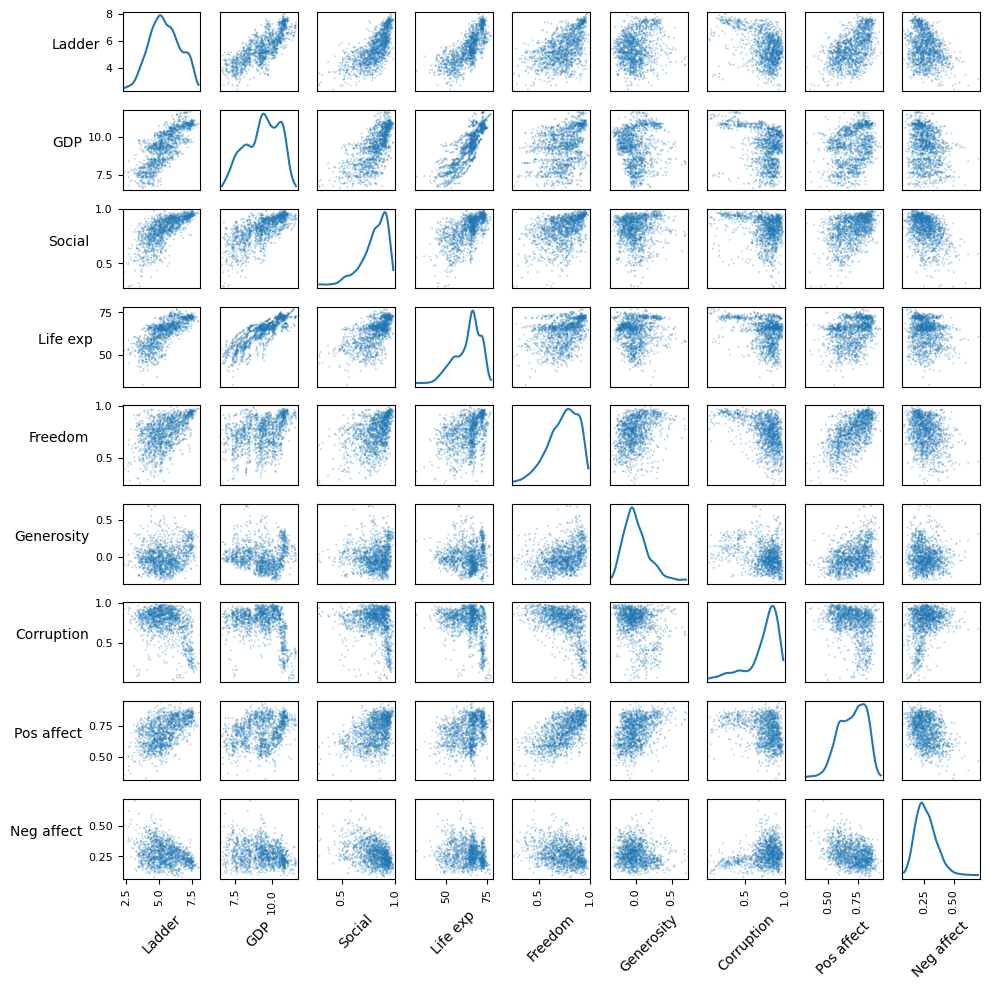

In [3]:
plotting.scatter_matrix(df=train_df, labels=SHORT_NAMES)

## Correlation

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) CorrelaMatrix (train)'}>

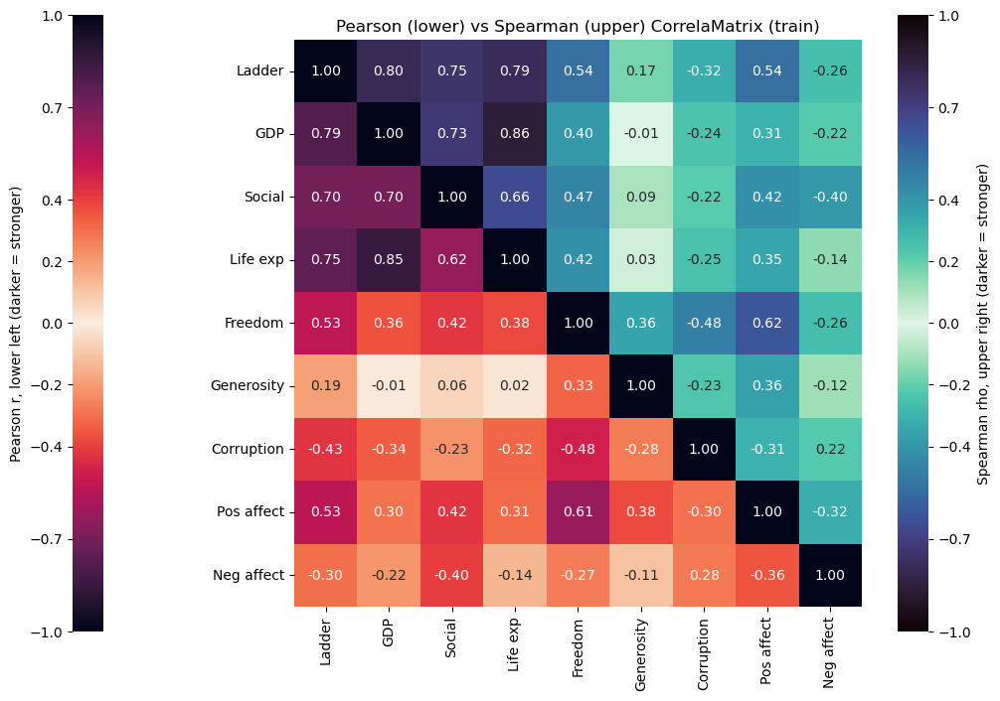

In [4]:
plotting.correlation_matrix(
      pearson=train_df.corr(),
      spearman=train_df.corr(method='spearman'),
      labels=SHORT_NAMES,
      title='Pearson (lower) vs Spearman (upper) CorrelaMatrix (train)',
)

### Collinearity

In [5]:
statistics.collinearity_df(df=train_df.drop(columns=TARGET),
													 # feature_pearson_threshold=0.7, filter=True # defaults
													 )

,rows used,Pearson r between features,|r| between features > 0.7,outcome
Log GDP per capita + Healthy life expectancy at birth,1509,0.851,True,"redundant: keep one, or use Ridge"


In [6]:
statistics.combination_gain_df(df=train_df, target=train_df[TARGET],
															 # size=2, cohen_f2_threshold=0.15, filter=True # defaults
															 )

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome
Log GDP per capita + Positive affect,1516,Log GDP per capita,Positive affect,0.787,0.847,0.060,0.800,0.858,0.058,0.346,True,keep together
Healthy life expectancy at birth + Positive affect,1505,Healthy life expectancy at birth,Positive affect,0.753,0.816,0.063,0.791,0.840,0.049,0.296,True,keep together
Social support + Healthy life expectancy at birth,1512,Healthy life expectancy at birth,Social support,0.751,0.810,0.060,0.788,0.847,0.060,0.271,True,keep together
Log GDP per capita + Freedom to make life choices,1511,Log GDP per capita,Freedom to make life choices,0.788,0.830,0.042,0.802,0.839,0.037,0.219,True,keep together
Healthy life expectancy at birth + Freedom to make life choices,1500,Healthy life expectancy at birth,Freedom to make life choices,0.752,0.798,0.046,0.790,0.828,0.038,0.197,True,keep together
Social support + Perceptions of corruption,1468,Social support,Perceptions of corruption,0.709,0.760,0.051,0.755,0.760,0.005,0.177,True,keep together
Social support + Positive affect,1540,Social support,Positive affect,0.704,0.750,0.046,0.748,0.783,0.035,0.153,True,keep together
Social support + Freedom to make life choices,1532,Social support,Freedom to make life choices,0.705,0.750,0.045,0.748,0.779,0.031,0.151,True,keep together


In [7]:
statistics.combination_gain_df(df=train_df, target=train_df[TARGET], size=3,
															 # cohen_f2_threshold=0.15, filter=True # defaults
															 )

,rows used,baseline features,added feature,baseline Pearson R,all features Pearson R,Pearson R gain,baseline Spearman rho,all features Spearman rho,Spearman rho gain,cohen f²,cohen f² ≥ 0.15,outcome
Social support + Healthy life expectancy at birth + Positive affect,1503,Healthy life expectancy at birth + Positive af...,Social support,0.816,0.844,0.028,0.84,0.872,0.032,0.164,True,keep together


# Attribute Interventions

## Perceptions of Corruption

Rows missing Corruption are dropped. Rows missing other attributes are kept, since only Corruption is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported.
- **nested** variants search t from 0.05 to 0.95 (step 0.02) with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [8]:
poc_col = COLUMNS['POC']['col']
poc_df = train_df[[poc_col, TARGET]].dropna(subset=[poc_col])
poc_X = poc_df[[poc_col]]
poc_y = poc_df[TARGET]

poc_folds = pipelines.make_folds(poc_X, seeds=SEEDS)
poc_results = {}

print(f"rows used: {len(poc_df)} of {len(train_df)}")
print(f"folds: {len(poc_folds)}")

rows used: 1473 of 1559
folds: 20


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Perceptions of corruption value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow both the steep fall across the low tail and the nearly flat top that LOWESS shows in Q1B.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

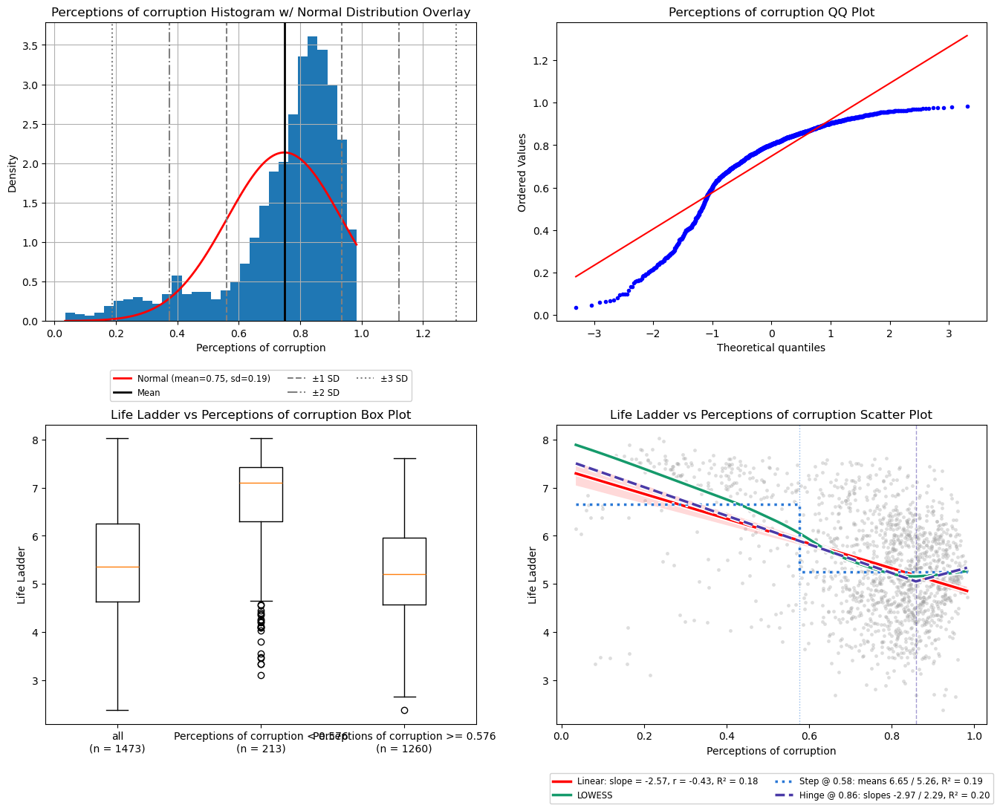

In [9]:
plotting.single_feature_plots(df=poc_df, feature=poc_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [10]:
poc_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=poc_X, y=poc_y, folds=poc_folds,
)
display(scoring.results_df({k: poc_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.017,0.035,0.836,0.029,0.178,0.037,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Low-side hinge

**What it targets**
In Q1B's scatter plot, Life Ladder vs Perceptions of corruption is not a straight line. LOWESS falls steeply across the low tail and is nearly flat across the crowded top of the range, where most rows sit. A LinearRegression on the raw value can only fit one slope for the whole range, so it has to compromise: too shallow for the low tail and too steep for the top, where it predicts Life Ladder differences between rows that LOWESS says are not there.

**What the intervention does**
Replaces the raw value with one new feature, the distance below a threshold `t`:

`h = max(0, t - x)`

| x | h (t = 0.58) |
|---|---|
| 0.90 | 0 |
| 0.58 | 0 |
| 0.50 | 0.08 |
| 0.20 | 0.38 |

No rows are dropped, and the low values keep their order and spacing. The model becomes `Life Ladder = a + b·h`:
- **At or above t:** h = 0, so every row gets the same prediction `a`. The top of the range is forced flat.
- **Below t:** the prediction moves in a straight line with the distance below t.

**What it gives up**
Every difference between values above t is erased. That is only safe if those differences carry no information about Life Ladder. If they do, B removes real signal and scores worse than A.

**Variants**
- **B fixed (t = 0.58):** Q1B's step threshold, close to where LOWESS stops falling steeply. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the bend.

**Hypothesis**
If Life Ladder only responds to Perceptions of corruption below t, forcing the top flat removes noise the raw slope was fitting, and B beats A by more than the noise threshold. If the top of the range still carries signal, B ties with A or loses to it.

/opt/homebrew/Caskroom/miniconda/base/envs/homl3/lib/python3.10/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


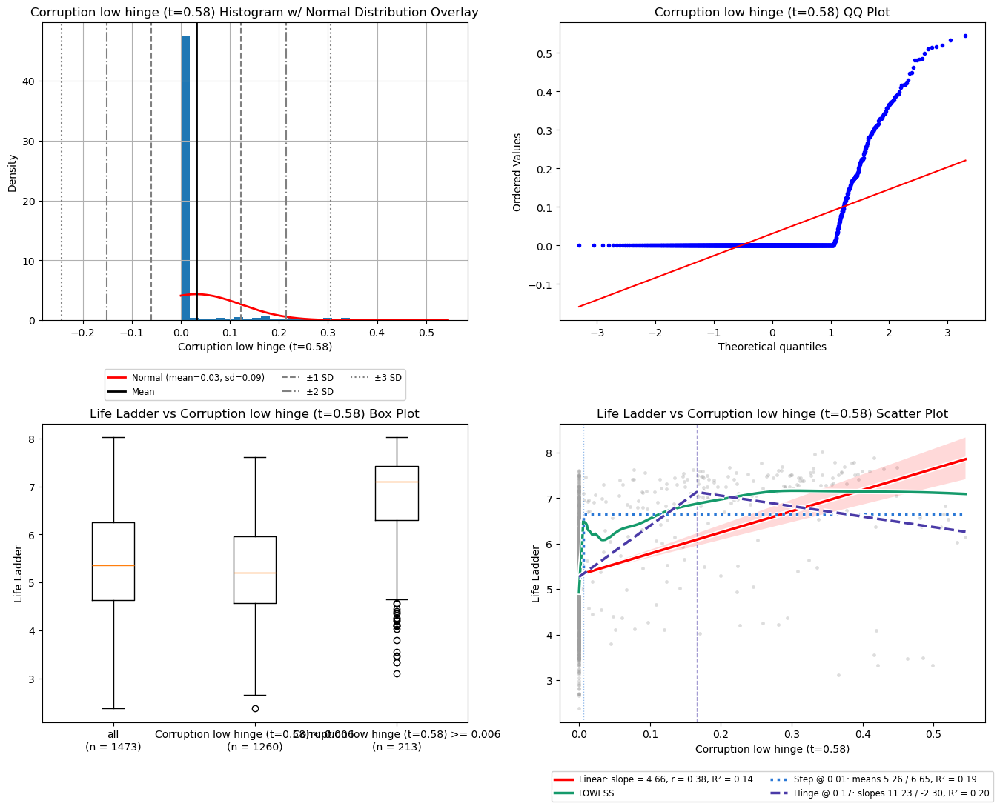

In [11]:
# fit on all poc_df rows, for illustration only (the scores below refit inside each training fold)
poc_b_df = pd.DataFrame(
	{"Corruption low hinge (t=0.58)": np.ravel(features.LowHinge(t=0.58).fit_transform(poc_X)), TARGET: poc_y},
	index=poc_df.index,
)
plotting.single_feature_plots(df=poc_b_df, feature="Corruption low hinge (t=0.58)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [12]:
poc_b_pipeline = Pipeline([("features", features.LowHinge(t=0.58)), ("model", LinearRegression())])

poc_results["B fixed (t=0.58)"] = pipelines.evaluate_pipeline(
	poc_b_pipeline,
	X=poc_X, y=poc_y, folds=poc_folds,
)
poc_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(poc_b_pipeline, param="features__t"),
	X=poc_X, y=poc_y, folds=poc_folds, return_estimator=True,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "B fixed (t=0.58)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B nested,1.011,0.036,0.823,0.029,0.188,0.041,-0.006,0.003,-2.294,0.017,candidate,20
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20
B fixed (t=0.58),1.042,0.038,0.848,0.029,0.137,0.045,0.025,0.008,3.236,0.998,worse,20


In [13]:
# threshold picked by the inner search in each of the 20 folds
poc_b_picked = features.picked_thresholds(poc_results["B nested"]["estimator"], param="features__t")
display(pd.Series(poc_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.81,2
0.83,14
0.85,4


### Intervention C | Linear spline (raw + hinge)

**What it targets**
The same bend as B: LOWESS falls steeply across the low tail and is nearly flat across the top of the range. Unlike B, C does not force the top flat, so it can keep a slope there if the data support one.

**What the intervention does**
Keeps the raw value and adds the hinge from B as a second feature:

`[x, max(0, t - x)]`

| x | features [x, h] (t = 0.86) |
|---|---|
| 0.95 | [0.95, 0] |
| 0.86 | [0.86, 0] |
| 0.70 | [0.70, 0.16] |
| 0.30 | [0.30, 0.56] |

The model becomes `Life Ladder = a + b·x + c·max(0, t - x)`, two straight segments joined at t:
- **At or above t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Below t:** h = t - x, so the prediction is `(a + c·t) + (b - c)·x`, a line with slope b - c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and C reduces to A with an extra parameter.

**Variants**
- **C fixed (t = 0.86):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
If both sides of t have a real but different slope, C beats A by more than the noise threshold, and also beats B, because it keeps the slope above t that B erases. If the top is truly flat, C has no advantage over B. If there is no bend, C ties with A.

#### Intervention C vs Target

In [14]:
poc_c_pipeline = Pipeline([("features", features.LowHinge(t=0.86, keep_raw=True)), ("model", LinearRegression())])

poc_results["C fixed (t=0.86)"] = pipelines.evaluate_pipeline(
	poc_c_pipeline,
	X=poc_X, y=poc_y, folds=poc_folds,
)
poc_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(poc_c_pipeline, param="features__t"),
	X=poc_X, y=poc_y, folds=poc_folds, return_estimator=True,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "C fixed (t=0.86)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.86),1.009,0.037,0.823,0.029,0.190,0.041,-0.008,0.003,-2.332,0.015,candidate,20
C nested,1.015,0.034,0.830,0.027,0.180,0.041,-0.002,0.003,-0.450,0.329,within noise,20
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20


In [15]:
# threshold picked by the inner search in each of the 20 folds
poc_c_picked = features.picked_thresholds(poc_results["C nested"]["estimator"], param="features__t")
display(pd.Series(poc_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.29,2
0.31,4
0.33,2
0.83,1
0.85,5
0.87,6


### Intervention D1 | Low-value indicator

**What it targets**
Q1B's box plot showed a level difference in Life Ladder between the rows below and above the step threshold. D1 tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 0.58) |
|---|---|
| 0.90 | 0 |
| 0.58 | 0 |
| 0.50 | 1 |
| 0.20 | 1 |

The model becomes `Life Ladder = a + b·i`, which predicts one mean per side:
- **At or above t:** i = 0, so every row gets `a`, the mean Life Ladder of the training rows above t.
- **Below t:** i = 1, so every row gets `a + b`, the mean Life Ladder of the training rows below t.

No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at 0.20 gets the same prediction as a row at 0.50. The change at t is a hard jump, so two rows just either side of t get predictions that differ by the full b.

**Variants**
- **D1 fixed (t = 0.58):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D1 nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the split.

**Hypothesis**
If most of the signal is just "below vs above t", D1 matches or beats A with a simpler shape. If Life Ladder keeps changing within the low side, D1 loses to A.

#### Intervention D1 vs Target

In [16]:
poc_d1_pipeline = Pipeline([("features", features.Indicator(t=0.58)), ("model", LinearRegression())])

poc_results["D1 fixed (t=0.58)"] = pipelines.evaluate_pipeline(
	poc_d1_pipeline,
	X=poc_X, y=poc_y, folds=poc_folds,
)
poc_results["D1 nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(poc_d1_pipeline, param="features__t"),
	X=poc_X, y=poc_y, folds=poc_folds, return_estimator=True,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "D1 fixed (t=0.58)", "D1 nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D1 fixed (t=0.58),1.014,0.033,0.820,0.025,0.183,0.038,-0.003,0.007,-0.477,0.320,within noise,20
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20
D1 nested,1.022,0.034,0.825,0.026,0.169,0.041,0.005,0.006,0.853,0.798,within noise,20


In [17]:
# threshold picked by the inner search in each of the 20 folds
poc_d1_picked = features.picked_thresholds(poc_results["D1 nested"]["estimator"], param="features__t")
display(pd.Series(poc_d1_picked).value_counts().sort_index().rename_axis("D1 nested picked t").to_frame("folds"))

,folds
D1 nested picked t,
0.51,6
0.53,5
0.55,2
0.57,5
0.63,2


### Intervention D2 | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range.

**What the intervention does**
Keeps the raw value and adds the indicator from D1 as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 0.58) |
|---|---|
| 0.90 | [0.90, 0] |
| 0.58 | [0.58, 0] |
| 0.50 | [0.50, 1] |
| 0.20 | [0.20, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot make it steeper than the top.

**Variants**
- **D2 fixed (t = 0.58):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D2 nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
If there is a level shift at t on top of a trend, D2 beats both A and D1 by more than the noise threshold. If there is no jump, c ends up near 0 and D2 ties with A.

#### Intervention D2 vs Target

In [18]:
poc_d2_pipeline = Pipeline([("features", features.Indicator(t=0.58, keep_raw=True)), ("model", LinearRegression())])

poc_results["D2 fixed (t=0.58)"] = pipelines.evaluate_pipeline(
	poc_d2_pipeline,
	X=poc_X, y=poc_y, folds=poc_folds,
)
poc_results["D2 nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(poc_d2_pipeline, param="features__t"),
	X=poc_X, y=poc_y, folds=poc_folds, return_estimator=True,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "D2 fixed (t=0.58)", "D2 nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D2 fixed (t=0.58),1.006,0.034,0.817,0.027,0.195,0.039,-0.011,0.004,-2.469,0.012,candidate,20
D2 nested,1.009,0.035,0.818,0.028,0.190,0.041,-0.007,0.004,-1.796,0.044,candidate,20
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20


In [19]:
# threshold picked by the inner search in each of the 20 folds
poc_d2_picked = features.picked_thresholds(poc_results["D2 nested"]["estimator"], param="features__t")
display(pd.Series(poc_d2_picked).value_counts().sort_index().rename_axis("D2 nested picked t").to_frame("folds"))

,folds
D2 nested picked t,
0.51,11
0.53,4
0.57,4
0.63,1


### Intervention E | Stretch the low tail (log)

**What it targets**
The same curvature as B and C, steep across the low tail and nearly flat across the top, but with a smooth curve and no threshold to pick.

**What the intervention does**
Replaces the raw value with its log:

`z = log(x)`

| x | log(x) |
|---|---|
| 0.10 | -2.303 |
| 0.20 | -1.609 |
| 0.50 | -0.693 |
| 0.80 | -0.223 |
| 0.90 | -0.105 |

The log spreads out the low values and squeezes the high ones: the gap from 0.10 to 0.20 becomes 0.693, while the same 0.10 gap from 0.80 to 0.90 becomes 0.118. The model becomes `Life Ladder = a + b·log(x)`, a straight line in log(x), which is a curve in x that is steep at the low end and flat at the top.

**What it gives up**
It assumes the bend has the specific log shape, with no parameter to adjust it. It also makes the left skew of the column worse on purpose: what matters for the LR is that the feature is linear with the target, not the shape of the feature's own histogram.

**Hypothesis**
If the bend is gradual rather than a sharp corner, E beats A by more than the noise threshold without needing a threshold. If the bend is a sharp corner, B or C fit it better than E.

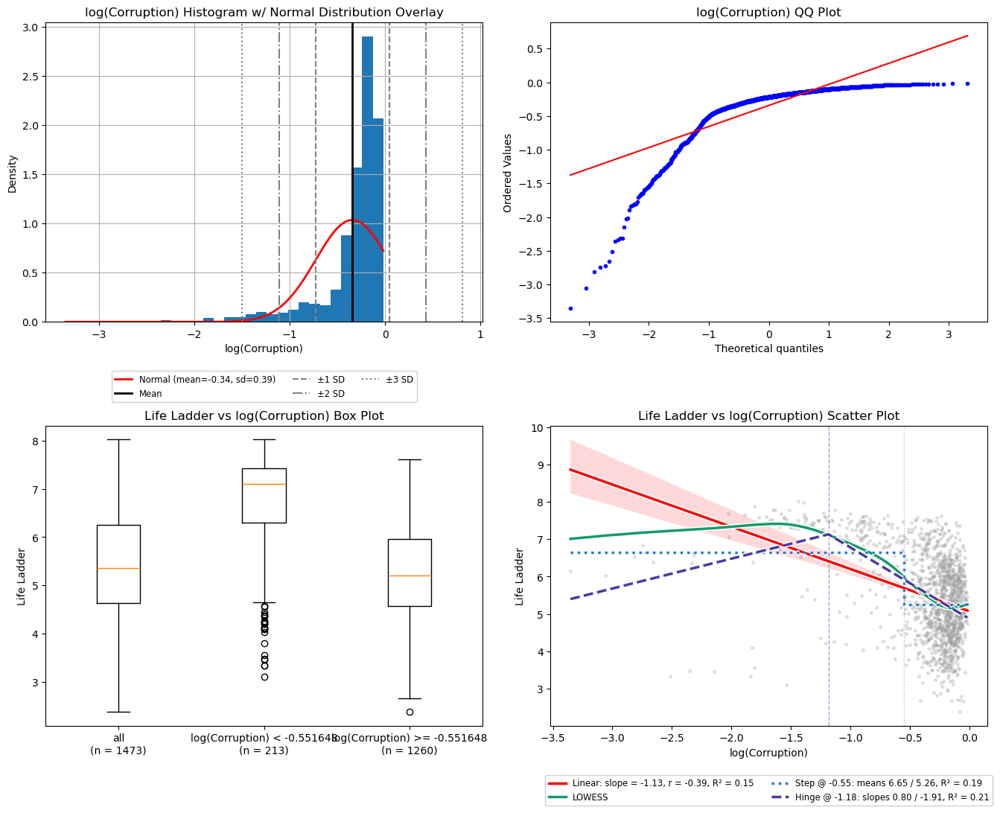

In [20]:
# fit on all poc_df rows, for illustration only (the scores below refit inside each training fold)
poc_e_df = pd.DataFrame(
	{"log(Corruption)": np.ravel(FunctionTransformer(np.log).fit_transform(poc_X)), TARGET: poc_y},
	index=poc_df.index,
)
plotting.single_feature_plots(df=poc_e_df, feature="log(Corruption)", target=TARGET, threshold="auto");

#### Intervention E vs Target

In [21]:
poc_results["E"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.log)), ("model", LinearRegression())]),
	X=poc_X, y=poc_y, folds=poc_folds,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "E"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20
E,1.038,0.037,0.850,0.030,0.143,0.044,0.022,0.008,2.771,0.994,worse,20


### Intervention F | Skew fix control (Yeo-Johnson)

**What it targets**
Control. The left skew Q1B flagged in this column: most rows crowd the top of the range, with a long tail toward low values.

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a left skewed column it stretches the crowded top end and compresses the low tail. The model becomes `Life Ladder = a + b·YJ(x)`.

**What it gives up**
It stretches exactly the region Q1B saw as flat, giving the LR more room to fit differences there, and compresses the low tail, where Q1B saw the target change. It bends the fit in the opposite direction from E.

**Hypothesis**
Tests Q1B's note that a skew fixing transform is unlikely to help this column. Expected to tie with or lose to A.

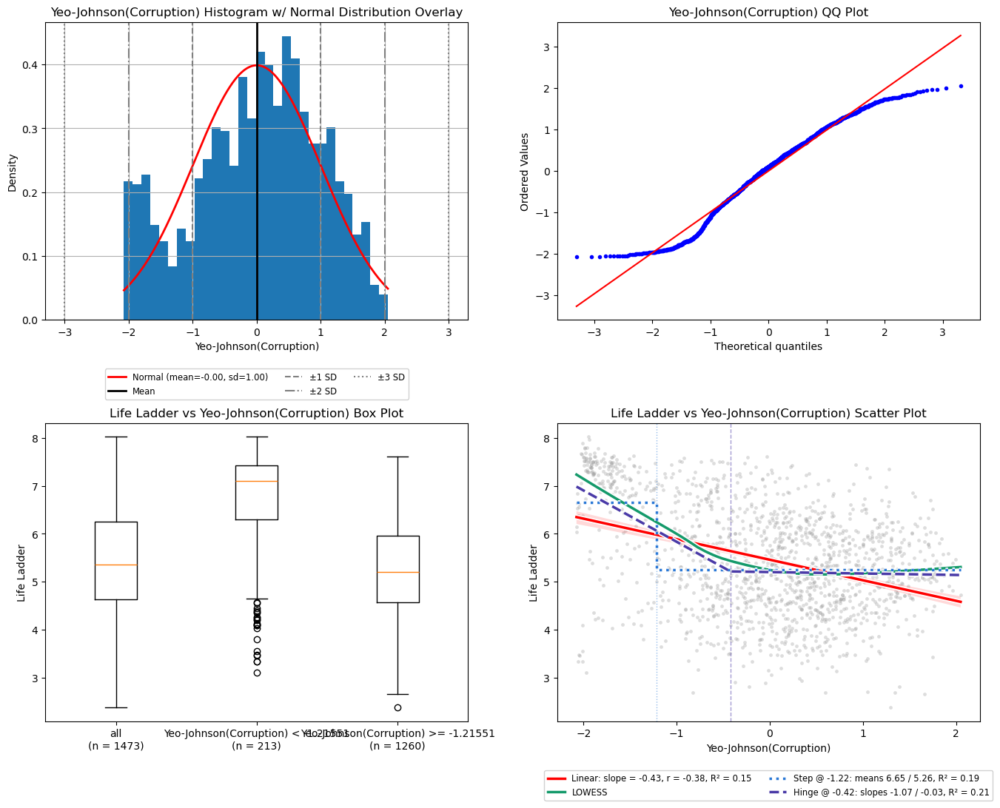

In [22]:
# fit on all poc_df rows, for illustration only (the scores below refit inside each training fold)
poc_f_df = pd.DataFrame(
	{"Yeo-Johnson(Corruption)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(poc_X)), TARGET: poc_y},
	index=poc_df.index,
)
plotting.single_feature_plots(df=poc_f_df, feature="Yeo-Johnson(Corruption)", target=TARGET, threshold="auto");

#### Intervention F vs Target

In [23]:
poc_results["F"] = pipelines.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=poc_X, y=poc_y, folds=poc_folds,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "F"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20
F,1.040,0.032,0.868,0.030,0.141,0.029,0.023,0.007,3.304,0.998,worse,20


### Intervention G | Winsorize control (IQR fence clip)

**What it targets**
Control. The low outliers Q1B flagged, the values below the lower IQR fence.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. Every value below the lower fence becomes the lower fence value, every value above the upper fence becomes the upper fence value, and every value between the fences is unchanged. The model becomes `Life Ladder = a + b·clip(x)`.

**What it gives up**
The detail in the low tail: every low outlier gets the same feature value and so the same prediction, and the low tail is where Q1B saw the target change.

**Hypothesis**
Tests Q1B's note not to clip the low outliers. Expected to tie with or lose to A.

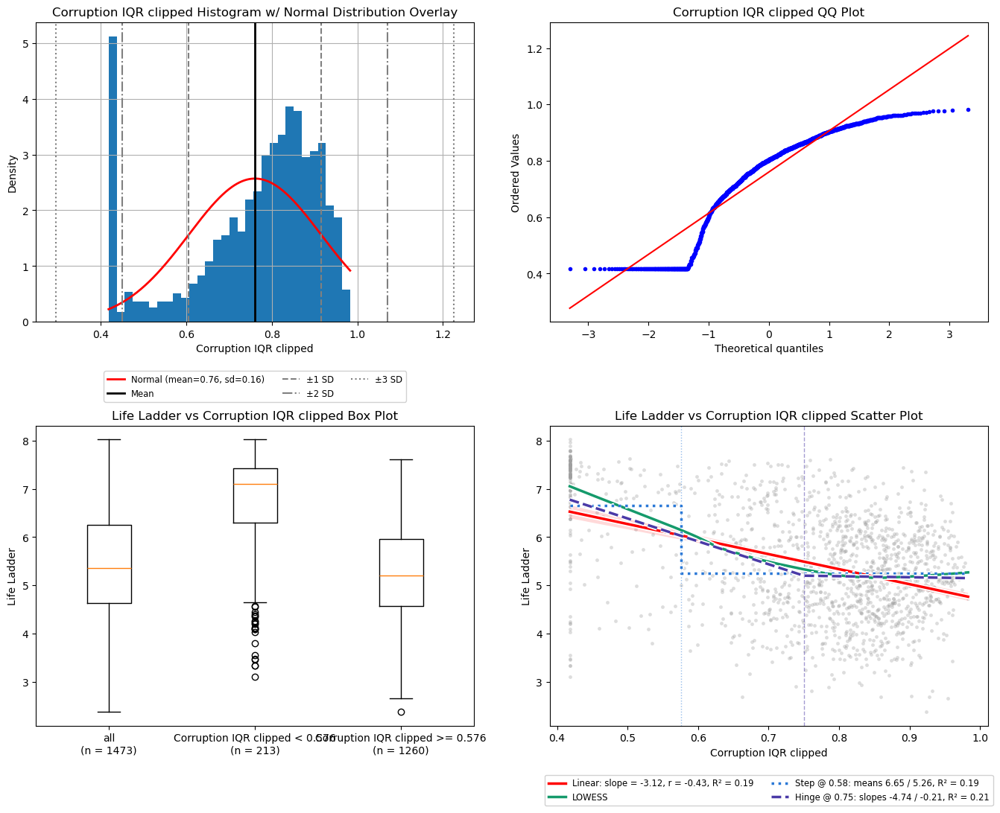

In [24]:
# fit on all poc_df rows, for illustration only (the scores below refit inside each training fold)
poc_g_df = pd.DataFrame(
	{"Corruption IQR clipped": np.ravel(features.IQRClip().fit_transform(poc_X)), TARGET: poc_y},
	index=poc_df.index,
)
plotting.single_feature_plots(df=poc_g_df, feature="Corruption IQR clipped", target=TARGET, threshold="auto");

#### Intervention G vs Target

In [25]:
poc_results["G"] = pipelines.evaluate_pipeline(
	Pipeline([("features", features.IQRClip()), ("model", LinearRegression())]),
	X=poc_X, y=poc_y, folds=poc_folds,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "G"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
G,1.015,0.033,0.838,0.029,0.181,0.034,-0.002,0.005,-0.321,0.376,within noise,20
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20


### Intervention H | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Perceptions of corruption can explain. B to E each force one shape (bend, jump, log curve). H tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If H scores about the same as the best of B to E:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If H is clearly better:** the simple shapes are missing part of the relationship.


#### Intervention H vs Target

In [26]:
poc_h_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

poc_results["H nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(poc_h_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=poc_X, y=poc_y, folds=poc_folds, return_estimator=True,
)
display(scoring.results_df({k: poc_results[k] for k in ["A", "H nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
H nested,0.999,0.032,0.807,0.026,0.207,0.037,-0.018,0.008,-2.379,0.014,candidate,20
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,baseline,20


In [27]:
# number of knots picked by the inner search in each of the 20 folds
poc_h_picked = features.picked_thresholds(poc_results["H nested"]["estimator"], param="features__n_knots")
display(pd.Series(poc_h_picked).astype(int).value_counts().sort_index().rename_axis("H nested picked n_knots").to_frame("folds"))

,folds
H nested picked n_knots,
3,11
4,1
5,1
6,3
8,3
10,1


### Comparison

In [28]:
display(scoring.results_df(poc_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
H nested,0.999,0.032,0.807,0.026,0.207,0.037,-0.018,0.008,-2.379,0.014,0.154,candidate,20
D2 fixed (t=0.58),1.006,0.034,0.817,0.027,0.195,0.039,-0.011,0.004,-2.469,0.012,0.139,candidate,20
C fixed (t=0.86),1.009,0.037,0.823,0.029,0.190,0.041,-0.008,0.003,-2.332,0.015,0.154,candidate,20
D2 nested,1.009,0.035,0.818,0.028,0.190,0.041,-0.007,0.004,-1.796,0.044,0.353,candidate,20
B nested,1.011,0.036,0.823,0.029,0.188,0.041,-0.006,0.003,-2.294,0.017,0.154,candidate,20
D1 fixed (t=0.58),1.014,0.033,0.820,0.025,0.183,0.038,-0.003,0.007,-0.477,0.320,1.000,within noise,20
G,1.015,0.033,0.838,0.029,0.181,0.034,-0.002,0.005,-0.321,0.376,1.000,within noise,20
C nested,1.015,0.034,0.830,0.027,0.180,0.041,-0.002,0.003,-0.450,0.329,1.000,within noise,20
A,1.017,0.035,0.836,0.029,0.178,0.037,0.000,NaN,NaN,NaN,NaN,baseline,20


## Perceptions of Corruption Results

- **No intervention is significant.** After the Holm adjustment across the 12 comparisons with A, the lowest `p (Holm)` is 0.139 (D2 fixed). Every gain is small: the best Δrmse vs A is -0.018, on an A rmse of 1.017.
- **Five candidates beat A by more than 1 SE:** H nested (Δ -0.018, Δ / SE -2.379), D2 fixed t = 0.58 (-0.011, -2.469), C fixed t = 0.86 (-0.008, -2.332), D2 nested (-0.007, -1.796) and B nested (-0.006, -2.294).
- **H, the flexible spline ceiling, scores best** (rmse 0.999, r2 0.207 vs A's 0.178), so the simple shapes leave a little signal behind. It picked 3 knots in 11 of 20 folds.
- **The jump location is stable, the bend location is not.** D2 nested picked t between 0.51 and 0.63 in all 20 folds, and B nested between 0.81 and 0.85. C nested split between 0.29 to 0.33 (8 folds) and 0.83 to 0.87 (12 folds), and is within noise (Δ / SE -0.450).
- **What loses to A:** B fixed at t = 0.58 (Δ +0.025), F (+0.023) and E (+0.022). Forcing everything above 0.58 flat removes signal; B nested only flattens above about 0.83. The two controls behave as Q1B expected: F (Yeo-Johnson) loses and G (IQR clip) ties A (Δ / SE -0.321). The indicator alone (D1) does not beat A in either variant.

#### Carry forward

- **D2 (raw + indicator `1[x < t]`)** as the main candidate for the multi-feature model, with t searched in each fold (the nested picks fell between 0.51 and 0.63).
- **H (cubic spline, few knots)** as the flexible option, to check whether its edge over D2 holds once the other features are in the model.
- **B nested and C fixed** (a bend near 0.83 to 0.86) as lower priority alternatives.
- **Drop:** E, F, G, D1 and B fixed at 0.58. Keep the low outliers unclipped.
- All gains are small and none is significant, so each one must clear the same noise threshold again in the multi-feature stage.

## Social Support

Rows missing Social support are dropped. Rows missing other attributes are kept, since only Social support is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported for the same shape (the hinge or the step).
- **nested** variants search t from 0.05 to 0.95 (step 0.02) with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [29]:
ss_col = COLUMNS['SS']['col']
ss_df = train_df[[ss_col, TARGET]].dropna(subset=[ss_col])
ss_X = ss_df[[ss_col]]
ss_y = ss_df[TARGET]

ss_folds = pipelines.make_folds(ss_X, seeds=SEEDS)
ss_results = {}

print(f"rows used: {len(ss_df)} of {len(train_df)}")
print(f"folds: {len(ss_folds)}")

rows used: 1549 of 1559
folds: 20


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Social support value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow both the shallow rise below about 0.8 and the steep rise across the top that LOWESS shows in Q1B.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model.

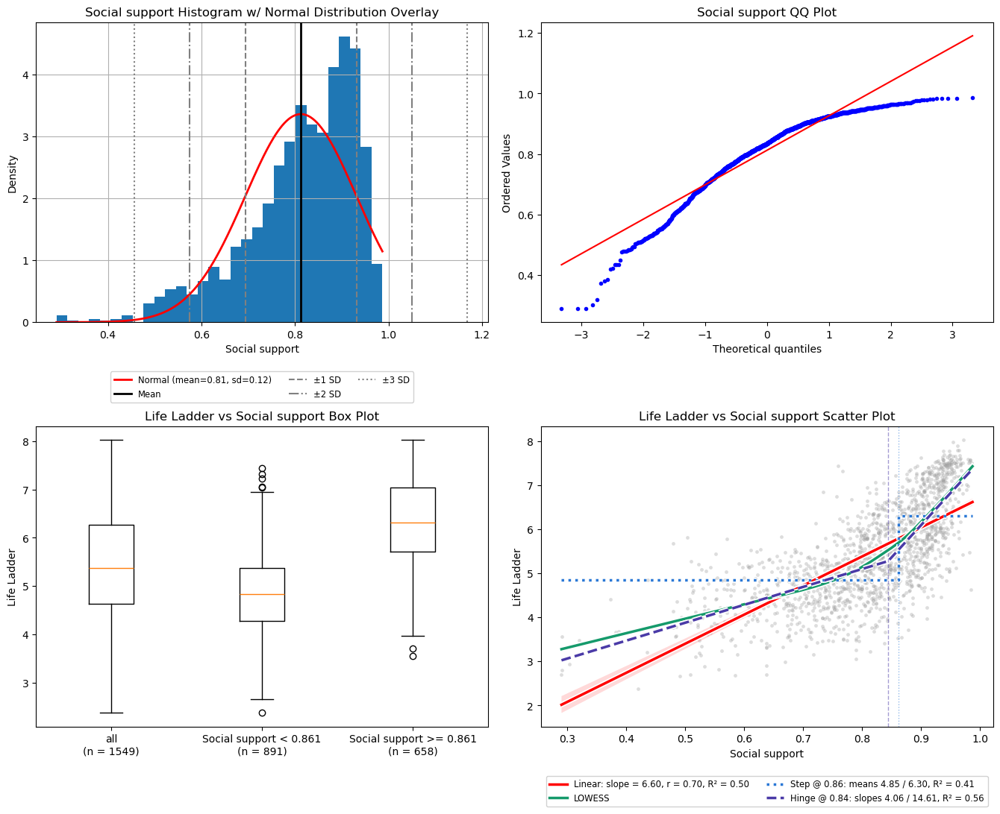

In [30]:
plotting.single_feature_plots(df=ss_df, feature=ss_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [31]:
ss_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=ss_X, y=ss_y, folds=ss_folds,
)
display(scoring.results_df({k: ss_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.792,0.018,0.649,0.016,0.493,0.024,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | High-side hinge

**What it targets**
In Q1B's scatter plot, Life Ladder vs Social support is not a straight line. LOWESS rises slowly below about 0.8 and steeply across the crowded top of the range, where most rows sit. A LinearRegression on the raw value can only fit one slope for the whole range, so it has to compromise: the line sits below LOWESS in the low tail and at the top, and above it in the middle of the range.

**What the intervention does**
Replaces the raw value with one new feature, the distance above a threshold `t`:

`h = max(0, x - t)`

| x | h (t = 0.84) |
|---|---|
| 0.98 | 0.14 |
| 0.90 | 0.06 |
| 0.84 | 0 |
| 0.50 | 0 |

No rows are dropped, and the high values keep their order and spacing. The model becomes `Life Ladder = a + b·h`:
- **Above t:** the prediction moves in a straight line with the distance above t.
- **At or below t:** h = 0, so every row gets the same prediction `a`. The bottom of the range is forced flat.

**What it gives up**
Every difference between values below t is erased. That is only safe if those differences carry no information about Life Ladder. Q1B's hinge fit at 0.84 found a low-side slope of 4.06, which is shallower than the top but not flat, so B may remove real signal and score worse than A.

**Variants**
- **B fixed (t = 0.84):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the bend.

**Hypothesis**
If Life Ladder only responds to Social support above t, forcing the bottom flat removes noise the raw slope was fitting, and B beats A by more than the noise threshold. Since Q1B's low-side slope is 4.06, B is expected to lose to A, unless that slope is mostly noise.

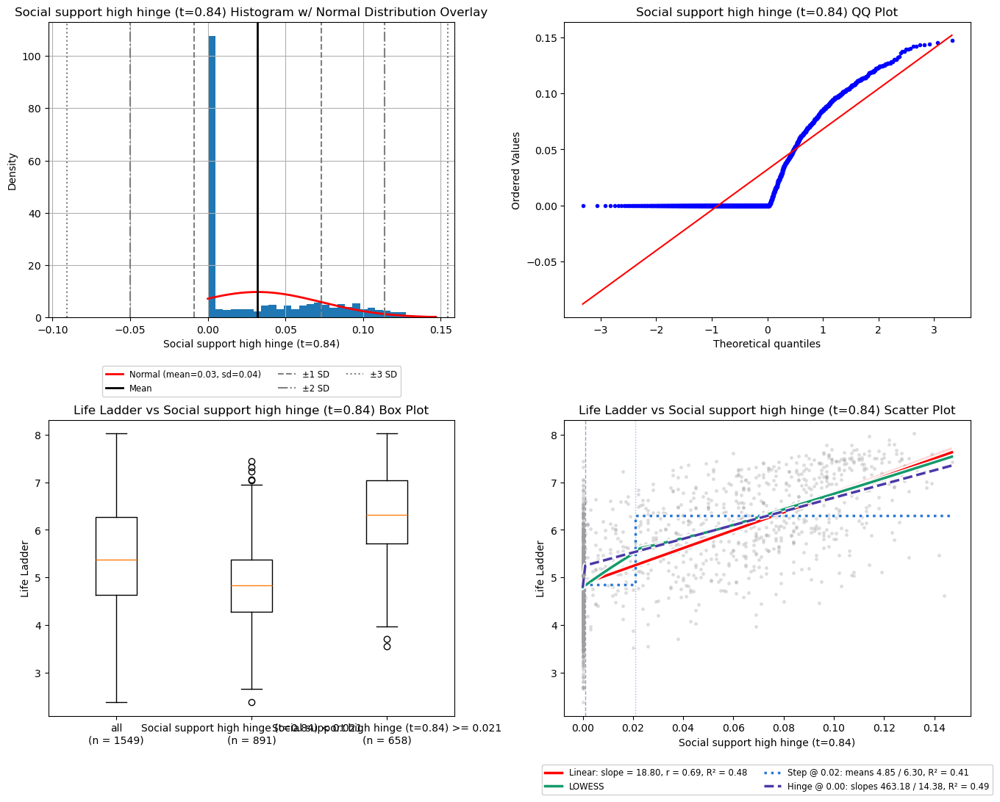

In [32]:
# fit on all ss_df rows, for illustration only (the scores below refit inside each training fold)
ss_b_df = pd.DataFrame(
	{"Social support high hinge (t=0.84)": np.ravel(features.HighHinge(t=0.84).fit_transform(ss_X)), TARGET: ss_y},
	index=ss_df.index,
)
plotting.single_feature_plots(df=ss_b_df, feature="Social support high hinge (t=0.84)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [33]:
ss_b_pipeline = Pipeline([("features", features.HighHinge(t=0.84)), ("model", LinearRegression())])

ss_results["B fixed (t=0.84)"] = pipelines.evaluate_pipeline(
	ss_b_pipeline,
	X=ss_X, y=ss_y, folds=ss_folds,
)
ss_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(ss_b_pipeline, param="features__t"),
	X=ss_X, y=ss_y, folds=ss_folds, return_estimator=True,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "B fixed (t=0.84)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B nested,0.750,0.019,0.611,0.017,0.544,0.028,-0.041,0.007,-5.851,0.000,candidate,20
A,0.792,0.018,0.649,0.016,0.493,0.024,0.000,NaN,NaN,NaN,baseline,20
B fixed (t=0.84),0.806,0.022,0.650,0.019,0.474,0.032,0.014,0.013,1.119,0.861,worse,20


In [34]:
# threshold picked by the inner search in each of the 20 folds
ss_b_picked = features.picked_thresholds(ss_results["B nested"]["estimator"], param="features__t")
display(pd.Series(ss_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.71,2
0.73,18


### Intervention C | Linear spline (raw + hinge)

**What it targets**
The same bend as B: LOWESS rises slowly below about 0.8 and steeply across the top of the range. Unlike B, C does not force the bottom flat, so it can keep a slope there if the data support one. This is the two-slope shape of Q1B's hinge fit at 0.84 (slopes 4.06 below and 14.61 above).

**What the intervention does**
Keeps the raw value and adds the hinge from B as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 0.84) |
|---|---|
| 0.98 | [0.98, 0.14] |
| 0.90 | [0.90, 0.06] |
| 0.84 | [0.84, 0] |
| 0.50 | [0.50, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

Using the low-side hinge instead, `[x, max(0, t - x)]` as in Corruption, would give exactly the same predictions: the two hinges differ by `x - t`, which the raw column and the intercept already cover. Only the coefficients change, not the fit.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and C reduces to A with an extra parameter.

**Variants**
- **C fixed (t = 0.84):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
If both sides of t have a real but different slope, C beats A by more than the noise threshold, and also beats B, because it keeps the slope below t that B erases. If the bottom is truly flat, C has no advantage over B. If there is no bend, C ties with A.

#### Intervention C vs Target

In [35]:
ss_c_pipeline = Pipeline([("features", features.HighHinge(t=0.84, keep_raw=True)), ("model", LinearRegression())])

ss_results["C fixed (t=0.84)"] = pipelines.evaluate_pipeline(
	ss_c_pipeline,
	X=ss_X, y=ss_y, folds=ss_folds,
)
ss_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(ss_c_pipeline, param="features__t"),
	X=ss_X, y=ss_y, folds=ss_folds, return_estimator=True,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "C fixed (t=0.84)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.84),0.739,0.019,0.599,0.016,0.558,0.028,-0.053,0.008,-6.766,0.0,candidate,20
C nested,0.742,0.019,0.601,0.016,0.554,0.029,-0.050,0.008,-6.481,0.0,candidate,20
A,0.792,0.018,0.649,0.016,0.493,0.024,0.000,NaN,NaN,NaN,baseline,20


In [36]:
# threshold picked by the inner search in each of the 20 folds
ss_c_picked = features.picked_thresholds(ss_results["C nested"]["estimator"], param="features__t")
display(pd.Series(ss_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.79,6
0.81,1
0.83,4
0.85,9


### Intervention D1 | Low-value indicator

**What it targets**
Q1B's step fit at 0.86 split the rows into two groups with mean Life Ladder 4.85 below and 6.30 above. D1 tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 0.86) |
|---|---|
| 0.95 | 0 |
| 0.86 | 0 |
| 0.80 | 1 |
| 0.40 | 1 |

The model becomes `Life Ladder = a + b·i`, which predicts one mean per side:
- **At or above t:** i = 0, so every row gets `a`, the mean Life Ladder of the training rows above t.
- **Below t:** i = 1, so every row gets `a + b`, the mean Life Ladder of the training rows below t.

No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at 0.40 gets the same prediction as a row at 0.80. The change at t is a hard jump, so two rows just either side of t get predictions that differ by the full b.

**Variants**
- **D1 fixed (t = 0.86):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D1 nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the split.

**Hypothesis**
If most of the signal is just "below vs above t", D1 matches or beats A with a simpler shape. Q1B's step R² (0.41) is below the linear R² (0.50), so D1 is expected to lose to A.

#### Intervention D1 vs Target

In [37]:
ss_d1_pipeline = Pipeline([("features", features.Indicator(t=0.86)), ("model", LinearRegression())])

ss_results["D1 fixed (t=0.86)"] = pipelines.evaluate_pipeline(
	ss_d1_pipeline,
	X=ss_X, y=ss_y, folds=ss_folds,
)
ss_results["D1 nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(ss_d1_pipeline, param="features__t"),
	X=ss_X, y=ss_y, folds=ss_folds, return_estimator=True,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "D1 fixed (t=0.86)", "D1 nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.792,0.018,0.649,0.016,0.493,0.024,0.000,NaN,NaN,NaN,baseline,20
D1 fixed (t=0.86),0.859,0.022,0.699,0.019,0.403,0.024,0.067,0.012,5.704,1.0,worse,20
D1 nested,0.869,0.023,0.709,0.020,0.389,0.027,0.077,0.010,7.639,1.0,worse,20


In [38]:
# threshold picked by the inner search in each of the 20 folds
ss_d1_picked = features.picked_thresholds(ss_results["D1 nested"]["estimator"], param="features__t")
display(pd.Series(ss_d1_picked).value_counts().sort_index().rename_axis("D1 nested picked t").to_frame("folds"))

,folds
D1 nested picked t,
0.85,9
0.87,10
0.89,1


### Intervention D2 | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range.

**What the intervention does**
Keeps the raw value and adds the indicator from D1 as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 0.86) |
|---|---|
| 0.95 | [0.95, 0] |
| 0.86 | [0.86, 0] |
| 0.80 | [0.80, 1] |
| 0.40 | [0.40, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot make the top steeper than the low side.

**Variants**
- **D2 fixed (t = 0.86):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D2 nested:** t is searched from 0.05 to 0.95 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
Tests a jump at t on top of the trend. If there is a level shift at t, D2 beats both A and D1 by more than the noise threshold. Q1B's LOWESS shows a bend rather than a jump, so c is expected to end up near 0 and D2 to tie with A.

#### Intervention D2 vs Target

In [39]:
ss_d2_pipeline = Pipeline([("features", features.Indicator(t=0.86, keep_raw=True)), ("model", LinearRegression())])

ss_results["D2 fixed (t=0.86)"] = pipelines.evaluate_pipeline(
	ss_d2_pipeline,
	X=ss_X, y=ss_y, folds=ss_folds,
)
ss_results["D2 nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(ss_d2_pipeline, param="features__t"),
	X=ss_X, y=ss_y, folds=ss_folds, return_estimator=True,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "D2 fixed (t=0.86)", "D2 nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D2 nested,0.760,0.019,0.620,0.016,0.532,0.028,-0.031,0.007,-4.496,0.0,candidate,20
D2 fixed (t=0.86),0.767,0.018,0.625,0.015,0.524,0.024,-0.025,0.005,-5.428,0.0,candidate,20
A,0.792,0.018,0.649,0.016,0.493,0.024,0.000,NaN,NaN,NaN,baseline,20


In [40]:
# threshold picked by the inner search in each of the 20 folds
ss_d2_picked = features.picked_thresholds(ss_results["D2 nested"]["estimator"], param="features__t")
display(pd.Series(ss_d2_picked).value_counts().sort_index().rename_axis("D2 nested picked t").to_frame("folds"))

,folds
D2 nested picked t,
0.63,1
0.89,11
0.91,8


### Intervention E | Stretch the top (logit)

**What it targets**
The same curvature as B and C, shallow across the low and middle range and steep across the top, but with a smooth curve and no threshold to pick.

**What the intervention does**
Replaces the raw value with its logit:

`z = logit(x) = log(x / (1 - x))`

| x | logit(x) |
|---|---|
| 0.30 | -0.847 |
| 0.60 | 0.405 |
| 0.84 | 1.658 |
| 0.90 | 2.197 |
| 0.95 | 2.944 |
| 0.98 | 3.892 |

The logit spreads out the values near the top and leaves the middle of the range close to evenly spaced: the gap from 0.30 to 0.40 becomes 0.442, while the same 0.10 gap from 0.88 to 0.98 becomes 1.899. The model becomes `Life Ladder = a + b·logit(x)`, a straight line in logit(x), which is a curve in x that is shallow across the low and middle range and steep near the top. The column max is 0.987, so `1 - x` is never 0 in these rows and the logit is always defined.

**What it gives up**
It assumes the bend has the specific logit shape, with no parameter to adjust it. The logit also stretches values near 0, but the column min is 0.29, so that side has little effect here.

**Hypothesis**
If the bend is gradual rather than a sharp corner, E beats A by more than the noise threshold without needing a threshold. If the bend is a sharp corner, C fits it better than E.

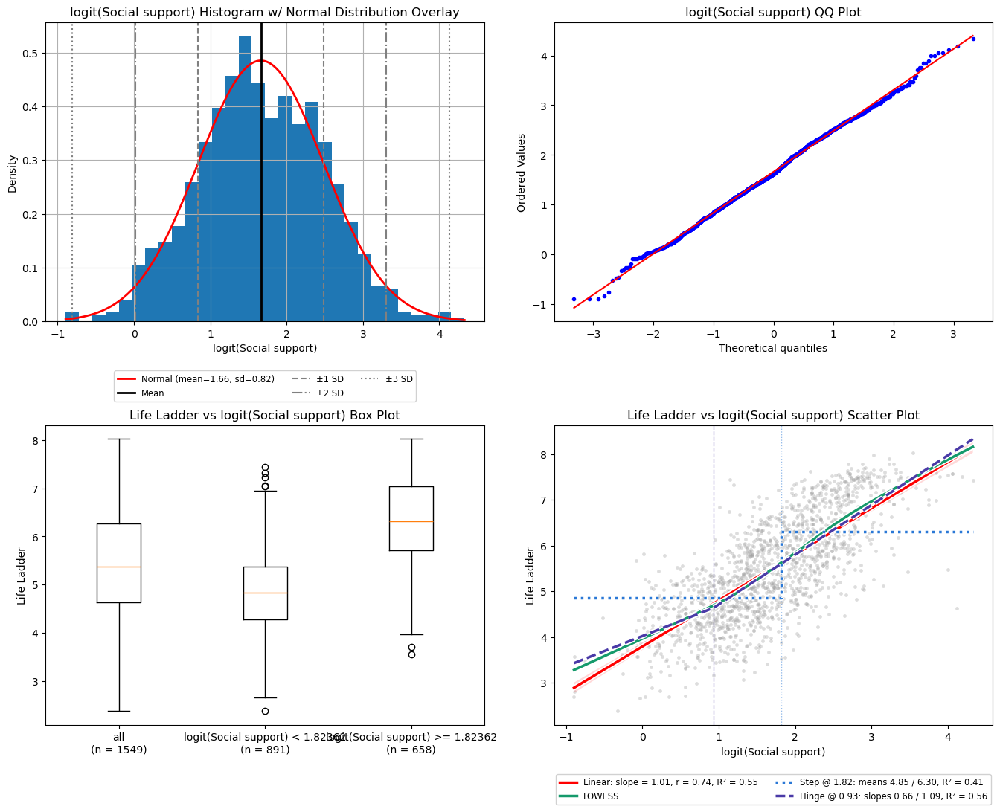

In [41]:
# fit on all ss_df rows, for illustration only (the scores below refit inside each training fold)
ss_e_df = pd.DataFrame(
	{"logit(Social support)": np.ravel(FunctionTransformer(logit).fit_transform(ss_X)), TARGET: ss_y},
	index=ss_df.index,
)
plotting.single_feature_plots(df=ss_e_df, feature="logit(Social support)", target=TARGET, threshold="auto");

#### Intervention E vs Target

In [42]:
ss_results["E"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(logit)), ("model", LinearRegression())]),
	X=ss_X, y=ss_y, folds=ss_folds,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "E"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E,0.744,0.021,0.602,0.016,0.552,0.032,-0.048,0.008,-5.766,0.0,candidate,20
A,0.792,0.018,0.649,0.016,0.493,0.024,0.000,NaN,NaN,NaN,baseline,20


### Intervention F | Stretch the top (Yeo-Johnson)

**What it targets**
The same curvature as E, with the amount of stretch fit to the data instead of fixed. Unlike Corruption, F is not a control here: Social support is left skewed (skew -1.138), with most rows crowding the top of the range, and Q1B lists Yeo-Johnson as a candidate.

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a left skewed column it stretches the crowded top end and compresses the low tail. That is the same direction as the bend Q1B saw, so it both reduces the skew and bends the fit the right way. The model becomes `Life Ladder = a + b·YJ(x)`.

**What it gives up**
The power is chosen to make the histogram symmetric, not to fit Life Ladder, so the amount of stretch at the top may be more or less than the bend needs. It also compresses the low tail, where Q1B's line sits below LOWESS.

**Hypothesis**
Expected to beat A. Compared with E, it shows whether a fitted power beats the fixed logit shape.

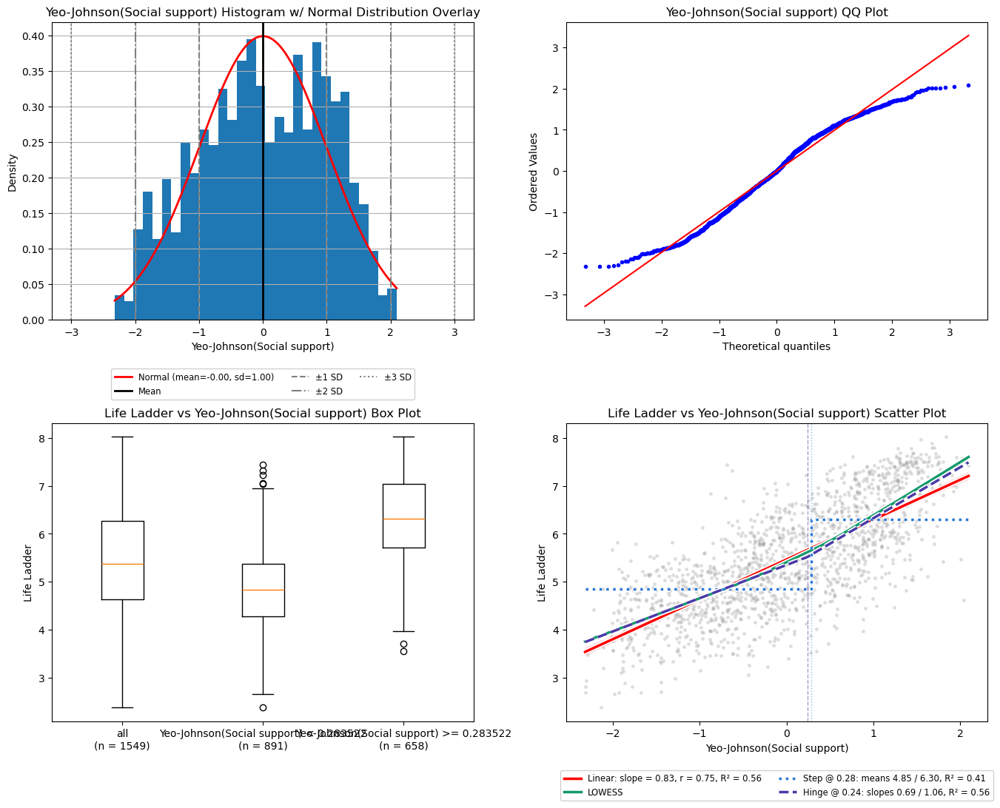

In [43]:
# fit on all ss_df rows, for illustration only (the scores below refit inside each training fold)
ss_f_df = pd.DataFrame(
	{"Yeo-Johnson(Social support)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(ss_X)), TARGET: ss_y},
	index=ss_df.index,
)
plotting.single_feature_plots(df=ss_f_df, feature="Yeo-Johnson(Social support)", target=TARGET, threshold="auto");

#### Intervention F vs Target

In [44]:
ss_results["F"] = pipelines.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=ss_X, y=ss_y, folds=ss_folds,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "F"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
F,0.742,0.019,0.601,0.016,0.555,0.029,-0.05,0.006,-8.759,0.0,candidate,20
A,0.792,0.018,0.649,0.016,0.493,0.024,0.00,NaN,NaN,NaN,baseline,20


### Intervention G | Winsorize control (IQR fence clip)

**What it targets**
Control. The low outliers Q1B flagged: 42 rows below the lower IQR fence (0.525), and none above the upper fence.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. Every value below the lower fence becomes the lower fence value, every value above the upper fence becomes the upper fence value, and every value between the fences is unchanged. The model becomes `Life Ladder = a + b·clip(x)`.

**What it gives up**
The detail in the low tail: every low outlier gets the same feature value and so the same prediction.

**Hypothesis**
Tests Q1B's note to keep the low outliers, since in the scatter they follow the LOWESS curve. The low tail is flatter than the straight line (the line sits below LOWESS there), so moving the low tail inward could help a straight line. If G beats A, that goes against Q1B's note. If it ties with or loses to A, the note holds.

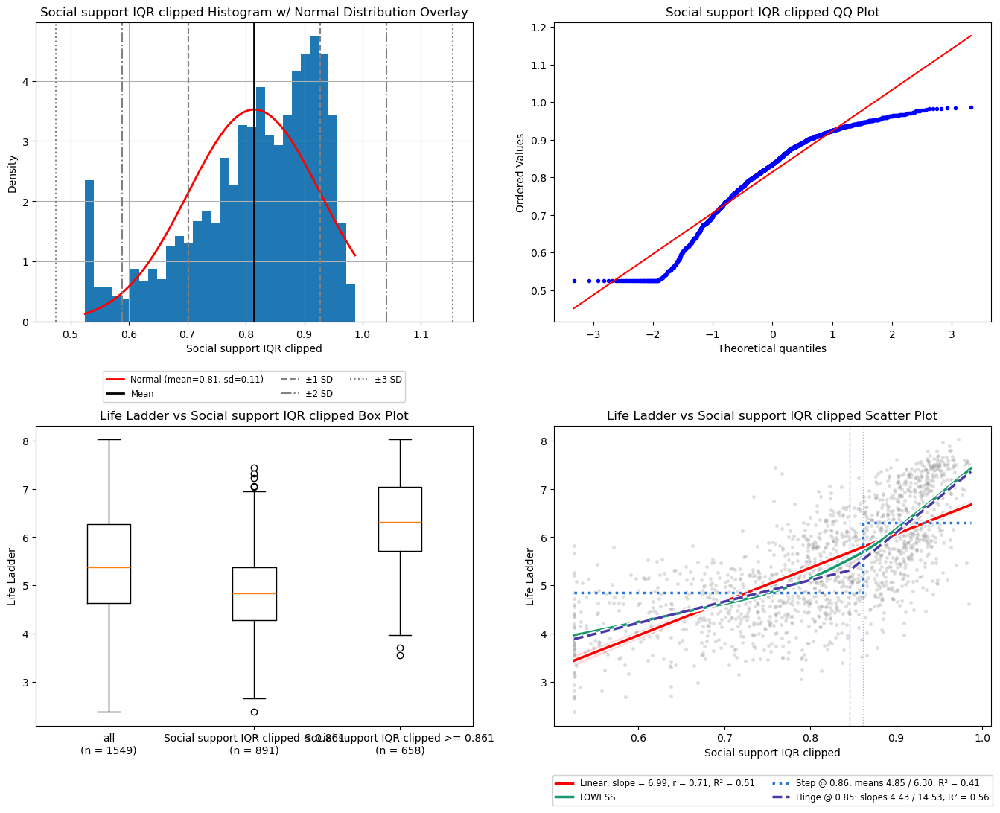

In [45]:
# fit on all ss_df rows, for illustration only (the scores below refit inside each training fold)
ss_g_df = pd.DataFrame(
	{"Social support IQR clipped": np.ravel(features.IQRClip().fit_transform(ss_X)), TARGET: ss_y},
	index=ss_df.index,
)
plotting.single_feature_plots(df=ss_g_df, feature="Social support IQR clipped", target=TARGET, threshold="auto");

#### Intervention G vs Target

In [46]:
ss_results["G"] = pipelines.evaluate_pipeline(
	Pipeline([("features", features.IQRClip()), ("model", LinearRegression())]),
	X=ss_X, y=ss_y, folds=ss_folds,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "G"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
G,0.784,0.018,0.641,0.015,0.503,0.028,-0.008,0.003,-2.546,0.01,candidate,20
A,0.792,0.018,0.649,0.016,0.493,0.024,0.000,NaN,NaN,NaN,baseline,20


### Intervention H | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Social support can explain. B to F each force one shape (bend, jump, logit curve, power curve). H tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If H scores about the same as the best of B to F:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If H is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention H vs Target

In [47]:
ss_h_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

ss_results["H nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(ss_h_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=ss_X, y=ss_y, folds=ss_folds, return_estimator=True,
)
display(scoring.results_df({k: ss_results[k] for k in ["A", "H nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
H nested,0.736,0.020,0.595,0.016,0.561,0.030,-0.055,0.008,-6.674,0.0,candidate,20
A,0.792,0.018,0.649,0.016,0.493,0.024,0.000,NaN,NaN,NaN,baseline,20


In [48]:
# number of knots picked by the inner search in each of the 20 folds
ss_h_picked = features.picked_thresholds(ss_results["H nested"]["estimator"], param="features__n_knots")
display(pd.Series(ss_h_picked).astype(int).value_counts().sort_index().rename_axis("H nested picked n_knots").to_frame("folds"))

,folds
H nested picked n_knots,
3,14
4,4
6,1
8,1


### Comparison

In [49]:
display(scoring.results_df(ss_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
H nested,0.736,0.020,0.595,0.016,0.561,0.030,-0.055,0.008,-6.674,0.000,0.000,significant,20
C fixed (t=0.84),0.739,0.019,0.599,0.016,0.558,0.028,-0.053,0.008,-6.766,0.000,0.000,significant,20
F,0.742,0.019,0.601,0.016,0.555,0.029,-0.050,0.006,-8.759,0.000,0.000,significant,20
C nested,0.742,0.019,0.601,0.016,0.554,0.029,-0.050,0.008,-6.481,0.000,0.000,significant,20
E,0.744,0.021,0.602,0.016,0.552,0.032,-0.048,0.008,-5.766,0.000,0.000,significant,20
B nested,0.750,0.019,0.611,0.017,0.544,0.028,-0.041,0.007,-5.851,0.000,0.000,significant,20
D2 nested,0.760,0.019,0.620,0.016,0.532,0.028,-0.031,0.007,-4.496,0.000,0.001,significant,20
D2 fixed (t=0.86),0.767,0.018,0.625,0.015,0.524,0.024,-0.025,0.005,-5.428,0.000,0.000,significant,20
G,0.784,0.018,0.641,0.015,0.503,0.028,-0.008,0.003,-2.546,0.010,0.039,significant,20


## Social Support Results

- **Nine of the 12 interventions are significant.** After the Holm adjustment, every intervention with Δrmse below 0 has `p (Holm)` of 0.039 or less. The gains are much larger than in Corruption: the best Δrmse vs A is -0.055, on an A rmse of 0.792.
- **The top five are close together:** H nested (Δ -0.055), C fixed t = 0.84 (-0.053), F (-0.050), C nested (-0.050) and E (-0.048). H, the flexible spline ceiling, scores best (rmse 0.736, r2 0.561 vs A's 0.493), but its edge over C fixed is only 0.003 rmse, so the simple shapes capture nearly all of the signal. H picked 3 knots in 14 of 20 folds.
- **The bend location is stable.** C nested picked t between 0.79 and 0.85 in all 20 folds, and scores within 0.003 rmse of C fixed at Q1B's 0.84. F (Yeo-Johnson) needs no threshold and has the largest Δ / SE (-8.759), so its gain is the most consistent across the folds.
- **Three hypotheses did not hold.** B nested beat A (Δ -0.041), picking t at 0.71 or 0.73 in all 20 folds, well below Q1B's 0.84. D2 beat A instead of tying (nested -0.031, fixed -0.025), with picks at 0.89 or 0.91 in 19 of 20 folds. G, the IQR clip control, is significant (Δ -0.008, `p (Holm)` 0.039), which goes against Q1B's note to keep the low outliers, although its gain is the smallest of the nine.
- **What loses to A:** D1 in both variants (Δ +0.067 fixed, +0.077 nested), as expected from Q1B's step R² (0.41) being below the linear R² (0.50). B fixed at t = 0.84 also loses (Δ +0.014): forcing everything below 0.84 flat removes signal, while B nested only flattens below about 0.73.

#### Carry forward

- **C (raw + hinge `[x, max(0, x - t)]`)** as the main candidate for the multi-feature model, with t searched in each fold (the nested picks fell between 0.79 and 0.85) or fixed at 0.84.
- **F (Yeo-Johnson)** as the no-threshold alternative: within 0.003 rmse of C fixed, with the most consistent gain.
- **H (cubic spline, few knots)** as the flexible option, to check whether its small edge holds once the other features are in the model.
- **E (logit)** as a lower priority alternative to F, since F does the same top stretch slightly better (Δ -0.050 vs -0.048).
- **G (IQR clip)** only as a check on top of C or F in the multi-feature stage. Its gain alone is small (Δ -0.008).
- **Drop:** D1, B fixed, and B nested and D2, which both trail C.

## Generosity

Rows missing Generosity are dropped. Rows missing other attributes are kept, since only Generosity is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported for the same shape (the hinge or the step).
- **nested** variants search t with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**The grid differs from the earlier sections.** Generosity runs from -0.335 to 0.698 and is centered on 0 (mean 0.0, median -0.025), so the 0.05 to 0.95 grid used for Corruption and Social support would miss the bottom half of the column. Here t is searched from -0.33 to 0.69 (step 0.02), and the 5% guard trims it to the range printed below. G searches (lo, hi) pairs from the same grid, with lo < hi and the guard applied to both ends.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [50]:
gen_col = COLUMNS['G']['col']
gen_df = train_df[[gen_col, TARGET]].dropna(subset=[gen_col])
gen_X = gen_df[[gen_col]]
gen_y = gen_df[TARGET]

gen_grid = np.round(np.arange(-0.33, 0.691, 0.02), 2)
gen_ramp_grid = [(lo, hi) for lo in gen_grid for hi in gen_grid if lo < hi]

gen_folds = pipelines.make_folds(gen_X, seeds=SEEDS)
gen_results = {}

gen_x = gen_X[gen_col].to_numpy()
gen_guarded = [t for t in gen_grid if min(np.mean(gen_x < t), np.mean(gen_x >= t)) >= features.MIN_GROUP_FRAC]
print(f"rows used: {len(gen_df)} of {len(train_df)}")
print(f"folds: {len(gen_folds)}")
print(f"threshold grid after the 5% guard (all rows): {gen_guarded[0]} to {gen_guarded[-1]}")

rows used: 1488 of 1559
folds: 20
threshold grid after the 5% guard (all rows): -0.21 to 0.29


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Generosity value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow the flat start below about 0.05, the climb to about 0.3 and the downturn above it that LOWESS shows in Q1B.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model. Q1B's linear fit had R² 0.04 (slope 1.32), so A's r2 is expected to be near 0.04.

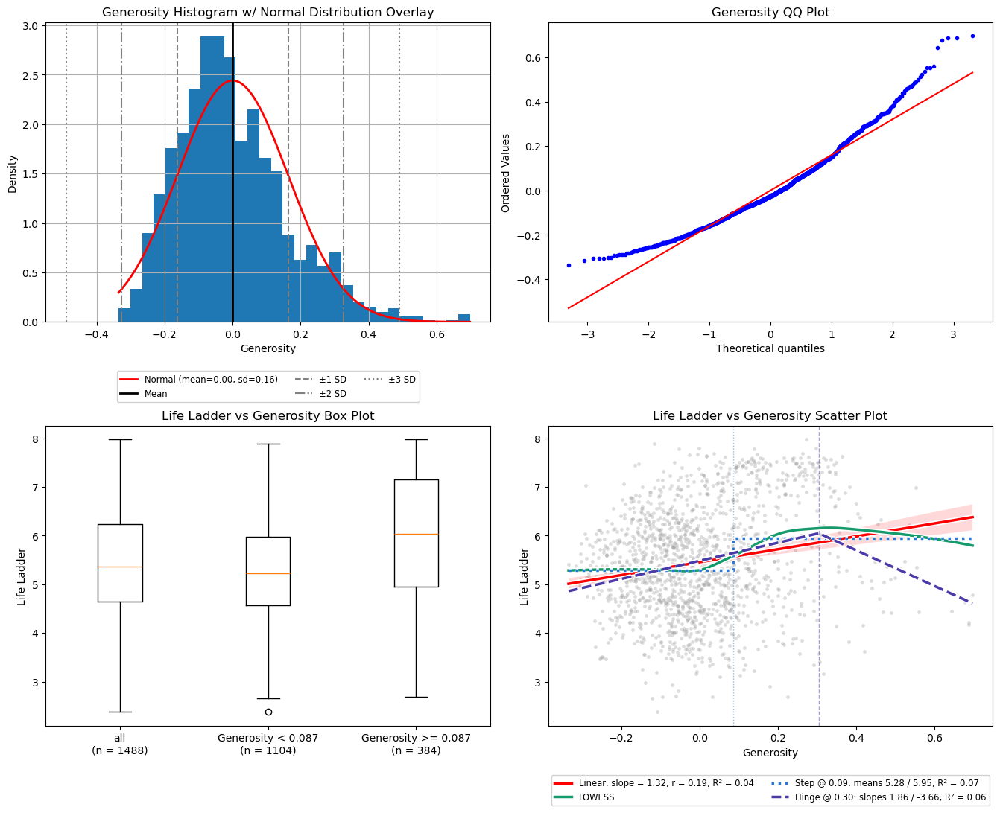

In [51]:
plotting.single_feature_plots(df=gen_df, feature=gen_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [52]:
gen_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=gen_X, y=gen_y, folds=gen_folds,
)
display(scoring.results_df({k: gen_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.089,0.045,0.91,0.039,0.033,0.019,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Flat start (high-side hinge alone)

**What it targets**
In Q1B's scatter plot, LOWESS is flat below about 0.05. The median is -0.025, so more than half the rows sit in that flat part, and the box plot puts 1104 of 1488 rows below 0.087. A LinearRegression on the raw value fits one slope across all of them, so it predicts Life Ladder differences between those rows that LOWESS says are not there.

**What the intervention does**
Replaces the raw value with one new feature, the distance above a threshold `t`:

`h = max(0, x - t)`

| x | h (t = 0.05) |
|---|---|
| 0.60 | 0.55 |
| 0.20 | 0.15 |
| 0.05 | 0 |
| -0.20 | 0 |

No rows are dropped, and the high values keep their order and spacing. The model becomes `Life Ladder = a + b·h`:
- **Above t:** the prediction moves in a straight line with the distance above t.
- **At or below t:** h = 0, so every row gets the same prediction `a`. The bottom of the range is forced flat.

**What it gives up**
Every difference between values below t is erased. That is only safe if those differences carry no information about Life Ladder. Above t the prediction keeps moving in one direction through the right tail, so B cannot follow the downturn above about 0.3.

**Variants**
- **No fixed variant.** Q1B fitted no threshold for this bend: its hinge at 0.30 is the downturn bend, and its step at 0.087 is the jump. The 0.05 is a reading of the LOWESS curve, not a fit, so it is only used for the plot below.
- **B nested:** t is searched from -0.33 to 0.69 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the flat start.

**Hypothesis**
If the bottom of the range is truly flat, forcing it flat removes noise the raw slope was fitting, and B beats A by more than the noise threshold. The single slope above t still runs through the right tail, where Q1B's hinge fit found the slope turning negative (-3.66), so the gain is limited.

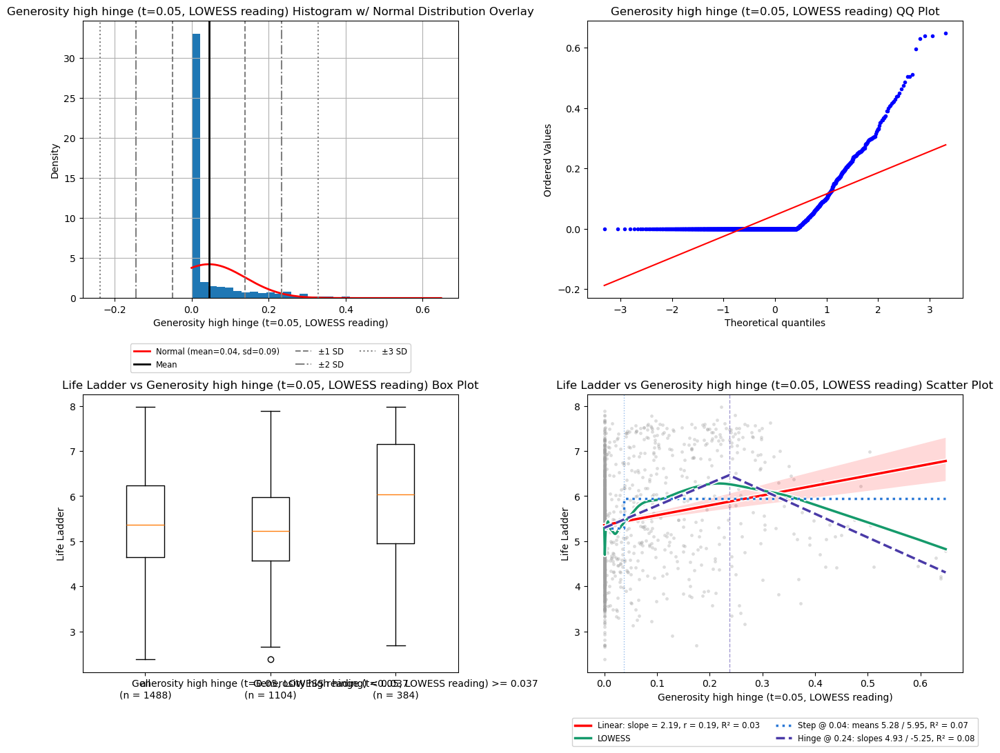

In [53]:
# fit on all gen_df rows, for illustration only (the scores below refit inside each training fold)
# t = 0.05 is Q1B's LOWESS reading, not a fitted threshold
gen_b_df = pd.DataFrame(
	{"Generosity high hinge (t=0.05, LOWESS reading)": np.ravel(features.HighHinge(t=0.05).fit_transform(gen_X)), TARGET: gen_y},
	index=gen_df.index,
)
plotting.single_feature_plots(df=gen_b_df, feature="Generosity high hinge (t=0.05, LOWESS reading)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [54]:
gen_b_pipeline = Pipeline([("features", features.HighHinge()), ("model", LinearRegression())])

gen_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gen_b_pipeline, param="features__t", grid=gen_grid),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B nested,1.087,0.044,0.906,0.038,0.036,0.020,-0.002,0.002,-0.821,0.211,within noise,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20


In [55]:
# threshold picked by the inner search in each of the 20 folds
gen_b_picked = features.picked_thresholds(gen_results["B nested"]["estimator"], param="features__t")
display(pd.Series(gen_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
-0.23,1
-0.07,6
-0.05,5
-0.03,8


### Intervention C | Cap the top (low-side hinge alone)

**What it targets**
The downturn above Q1B's hinge at 0.30, where the hinge fit found a slope of 1.86 below and -3.66 above. Q1B notes that the downturn rests on the few rows in the right tail. A single raw slope is pulled by those tail rows, and C removes that pull by giving every row above t the same prediction.

**What the intervention does**
Replaces the raw value with one new feature, the distance below a threshold `t`:

`h = max(0, t - x)`

| x | h (t = 0.30) | min(x, t) |
|---|---|---|
| 0.60 | 0 | 0.30 |
| 0.30 | 0 | 0.30 |
| 0.10 | 0.20 | 0.10 |
| -0.20 | 0.50 | -0.20 |

`max(0, t - x)` equals `t - min(x, t)`, so the LR fits exactly the same as on x capped at t: the sign flip and the shift by t are absorbed by the coefficient and the intercept. The model becomes `Life Ladder = a + b·h`:
- **At or above t:** h = 0, so every row gets the same prediction `a`. The top of the range is forced flat.
- **Below t:** the prediction moves in a straight line with x.

**What it gives up**
Everything above t is flat, so C cannot bend down: it removes the tail's pull on the slope but cannot follow the downturn, and the tail rows still get the top prediction.

**Variants**
- **C fixed (t = 0.30):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from -0.33 to 0.69 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the cap.

**Hypothesis**
If the downturn only rests on a few tail rows, capping the top stops them from flattening the slope below t, and C beats A by a small margin. The 5% guard keeps t out of the top 5% of rows, so the nested search cannot cap inside the right tail itself.

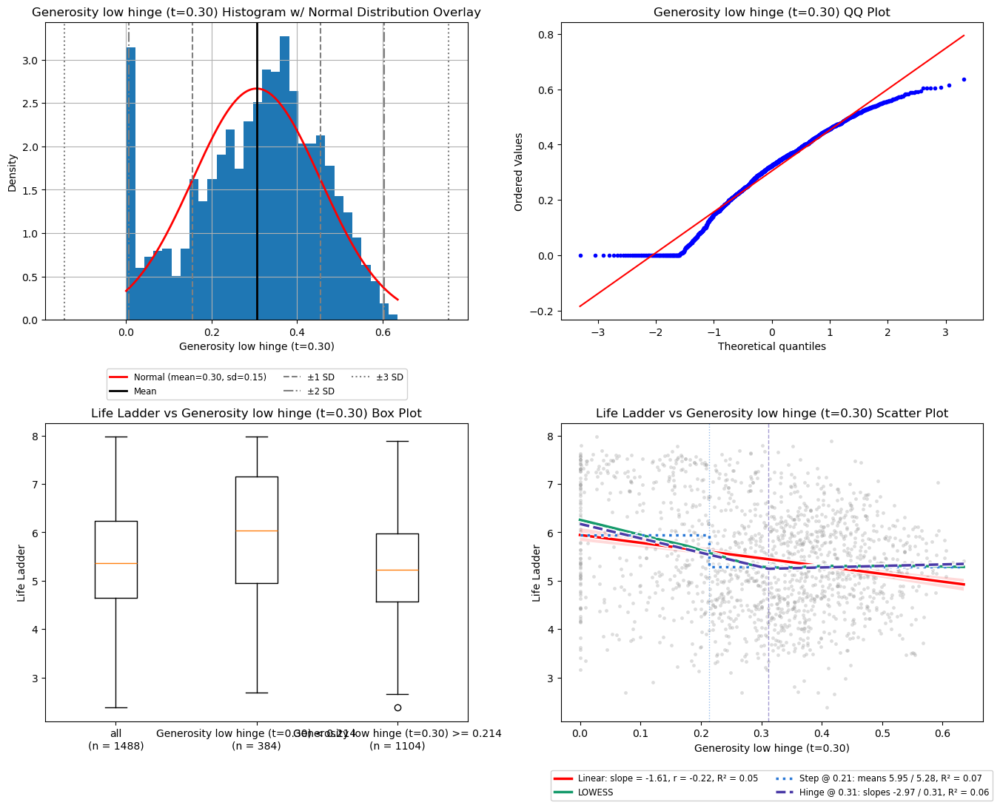

In [56]:
# fit on all gen_df rows, for illustration only (the scores below refit inside each training fold)
gen_c_df = pd.DataFrame(
	{"Generosity low hinge (t=0.30)": np.ravel(features.LowHinge(t=0.30).fit_transform(gen_X)), TARGET: gen_y},
	index=gen_df.index,
)
plotting.single_feature_plots(df=gen_c_df, feature="Generosity low hinge (t=0.30)", target=TARGET, threshold="auto");

#### Intervention C vs Target

In [57]:
gen_c_pipeline = Pipeline([("features", features.LowHinge(t=0.30)), ("model", LinearRegression())])

gen_results["C fixed (t=0.30)"] = pipelines.evaluate_pipeline(
	gen_c_pipeline,
	X=gen_X, y=gen_y, folds=gen_folds,
)
gen_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gen_c_pipeline, param="features__t", grid=gen_grid),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "C fixed (t=0.30)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.30),1.084,0.044,0.907,0.039,0.043,0.019,-0.005,0.001,-3.944,0.000,candidate,20
C nested,1.084,0.044,0.908,0.039,0.042,0.019,-0.005,0.001,-3.558,0.001,candidate,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20


In [58]:
# threshold picked by the inner search in each of the 20 folds
gen_c_picked = features.picked_thresholds(gen_results["C nested"]["estimator"], param="features__t")
display(pd.Series(gen_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.27,4
0.29,16


### Intervention D | Linear spline (raw + hinge)

**What it targets**
Q1B's hinge fit at 0.30: slope 1.86 below and -3.66 above, with R² 0.06 against the linear fit's 0.04. Unlike B and C, D keeps a slope on both sides of t, so it is the only threshold shape here that can turn down above t.

**What the intervention does**
Keeps the raw value and adds the high-side hinge as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 0.30) |
|---|---|
| 0.60 | [0.60, 0.30] |
| 0.40 | [0.40, 0.10] |
| 0.30 | [0.30, 0] |
| -0.10 | [-0.10, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

Using the low-side hinge instead, `[x, max(0, t - x)]`, would give exactly the same predictions: the two hinges differ by `x - t`, which the raw column and the intercept already cover. Only the coefficients change, not the fit.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. The slope above t rests on the few rows in the right tail. If the bend is not real, c ends up near 0 and D reduces to A with an extra parameter.

**Variants**
- **D fixed (t = 0.30):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D nested:** t is searched from -0.33 to 0.69 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
D fixed is expected to beat A, since Q1B's hinge R² (0.06) is above the linear R² (0.04). The 5% guard keeps the nested t out of the top 5% of rows, so the nested picks may move away from 0.30 (ex to the flat-start bend near 0.05). If they do, D nested may not match D fixed.

#### Intervention D vs Target

In [59]:
gen_d_pipeline = Pipeline([("features", features.HighHinge(t=0.30, keep_raw=True)), ("model", LinearRegression())])

gen_results["D fixed (t=0.30)"] = pipelines.evaluate_pipeline(
	gen_d_pipeline,
	X=gen_X, y=gen_y, folds=gen_folds,
)
gen_results["D nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gen_d_pipeline, param="features__t", grid=gen_grid),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "D fixed (t=0.30)", "D nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D fixed (t=0.30),1.079,0.043,0.902,0.037,0.051,0.019,-0.01,0.004,-2.817,0.006,candidate,20
D nested,1.080,0.043,0.902,0.038,0.050,0.019,-0.01,0.004,-2.700,0.007,candidate,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.00,NaN,NaN,NaN,baseline,20


In [60]:
# threshold picked by the inner search in each of the 20 folds
gen_d_picked = features.picked_thresholds(gen_results["D nested"]["estimator"], param="features__t")
display(pd.Series(gen_d_picked).value_counts().sort_index().rename_axis("D nested picked t").to_frame("folds"))

,folds
D nested picked t,
0.29,17
0.31,3


### Intervention E | Indicator alone

**What it targets**
Q1B's step fit at 0.087 (the legend shows 0.09) split the rows into two groups with mean Life Ladder 5.28 below and 5.95 above, with 1104 rows below and 384 at or above in the box plot. Its R² of 0.07 is the best of Q1B's three fits (linear 0.04, hinge 0.06), and Q1B notes that the step beats the hinge. E tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 0.087) |
|---|---|
| 0.50 | 0 |
| 0.087 | 0 |
| 0.05 | 1 |
| -0.20 | 1 |

The model becomes `Life Ladder = a + b·i`, which predicts one mean per side:
- **At or above t:** i = 0, so every row gets `a`, the mean Life Ladder of the training rows above t.
- **Below t:** i = 1, so every row gets `a + b`, the mean Life Ladder of the training rows below t.

No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at -0.20 gets the same prediction as a row at 0.05. The change at t is a hard jump, so two rows just either side of t get predictions that differ by the full b.

**Variants**
- **E fixed (t = 0.087):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **E nested:** t is searched from -0.33 to 0.69 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the split.

**Hypothesis**
Expected to beat A by more than the noise threshold and to be the strongest simple shape, since Q1B's step R² (0.07) is above both the linear (0.04) and the hinge (0.06) R².

#### Intervention E vs Target

In [61]:
gen_e_pipeline = Pipeline([("features", features.Indicator(t=0.087)), ("model", LinearRegression())])

gen_results["E fixed (t=0.087)"] = pipelines.evaluate_pipeline(
	gen_e_pipeline,
	X=gen_X, y=gen_y, folds=gen_folds,
)
gen_results["E nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gen_e_pipeline, param="features__t", grid=gen_grid),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "E fixed (t=0.087)", "E nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E fixed (t=0.087),1.072,0.044,0.892,0.037,0.064,0.022,-0.017,0.003,-5.432,0.00,candidate,20
E nested,1.076,0.046,0.895,0.038,0.056,0.025,-0.013,0.005,-2.562,0.01,candidate,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20


In [62]:
# threshold picked by the inner search in each of the 20 folds
gen_e_picked = features.picked_thresholds(gen_results["E nested"]["estimator"], param="features__t")
display(pd.Series(gen_e_picked).value_counts().sort_index().rename_axis("E nested picked t").to_frame("folds"))

,folds
E nested picked t,
0.09,15
0.11,2
0.13,3


### Intervention F | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range.

**What the intervention does**
Keeps the raw value and adds the indicator from E as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 0.087) |
|---|---|
| 0.50 | [0.50, 0] |
| 0.087 | [0.087, 0] |
| 0.05 | [0.05, 1] |
| -0.20 | [-0.20, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot make it flatter than the high side, and cannot follow the downturn.

**Variants**
- **F fixed (t = 0.087):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **F nested:** t is searched from -0.33 to 0.69 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
Tests a jump at t on top of the trend. Within each side the trend looks nearly flat in Q1B's LOWESS (flat below about 0.05, rising then turning down above), so the raw column adds little, b is expected to end up near 0, and F to tie with E.

#### Intervention F vs Target

In [63]:
gen_f_pipeline = Pipeline([("features", features.Indicator(t=0.087, keep_raw=True)), ("model", LinearRegression())])

gen_results["F fixed (t=0.087)"] = pipelines.evaluate_pipeline(
	gen_f_pipeline,
	X=gen_X, y=gen_y, folds=gen_folds,
)
gen_results["F nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gen_f_pipeline, param="features__t", grid=gen_grid),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "F fixed (t=0.087)", "F nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
F fixed (t=0.087),1.072,0.044,0.891,0.037,0.063,0.022,-0.017,0.004,-4.906,0.000,candidate,20
F nested,1.076,0.046,0.894,0.038,0.057,0.024,-0.013,0.005,-2.500,0.011,candidate,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20


In [64]:
# threshold picked by the inner search in each of the 20 folds
gen_f_picked = features.picked_thresholds(gen_results["F nested"]["estimator"], param="features__t")
display(pd.Series(gen_f_picked).value_counts().sort_index().rename_axis("F nested picked t").to_frame("folds"))

,folds
F nested picked t,
0.09,17
0.13,3


### Intervention G | Ramp (flat, climb, flat)

**What it targets**
The S shape in Q1B's notes: LOWESS is flat below about 0.05, then climbs to about 0.3. G captures the flat start and the climb in one column. It is a softened version of E's step: E jumps at one point, while G climbs in a straight line between lo and hi.

**What the intervention does**
Replaces the raw value with the value clipped to a range `[lo, hi]`:

`r = clip(x, lo, hi)`

| x | r (lo = 0.05, hi = 0.30) |
|---|---|
| -0.20 | 0.05 |
| 0.05 | 0.05 |
| 0.10 | 0.10 |
| 0.20 | 0.20 |
| 0.30 | 0.30 |
| 0.60 | 0.30 |

The model becomes `Life Ladder = a + b·r`:
- **Below lo:** r = lo, so every row gets the same prediction `a + b·lo`. The bottom is flat.
- **Between lo and hi:** the prediction moves in a straight line with x, with slope b.
- **Above hi:** r = hi, so every row gets the same prediction `a + b·hi`. The top is flat.

As lo and hi move closer together, the ramp approaches a step like E's.

**What it gives up**
Everything above hi is flat, so G cannot follow the downturn. It also has two thresholds to pick instead of one, which gives the inner search more room to fit noise in the training folds.

**Variants**
- **G nested only.** Q1B fitted no threshold for the lower corner, so there is no fixed pair. lo and hi are searched together over every pair from the Generosity grid with lo < hi, inside each training fold (inner 4-fold CV), and both lo and hi must leave at least 5% of the training fold's rows on each side. The validation rows never influence the pair, and the pairs it picks show where the data place the flat start and the top of the climb.

**Hypothesis**
If the climb from the flat start is gradual, G beats E. If it is a sharp jump, the search picks lo and hi close together and G ties with E.

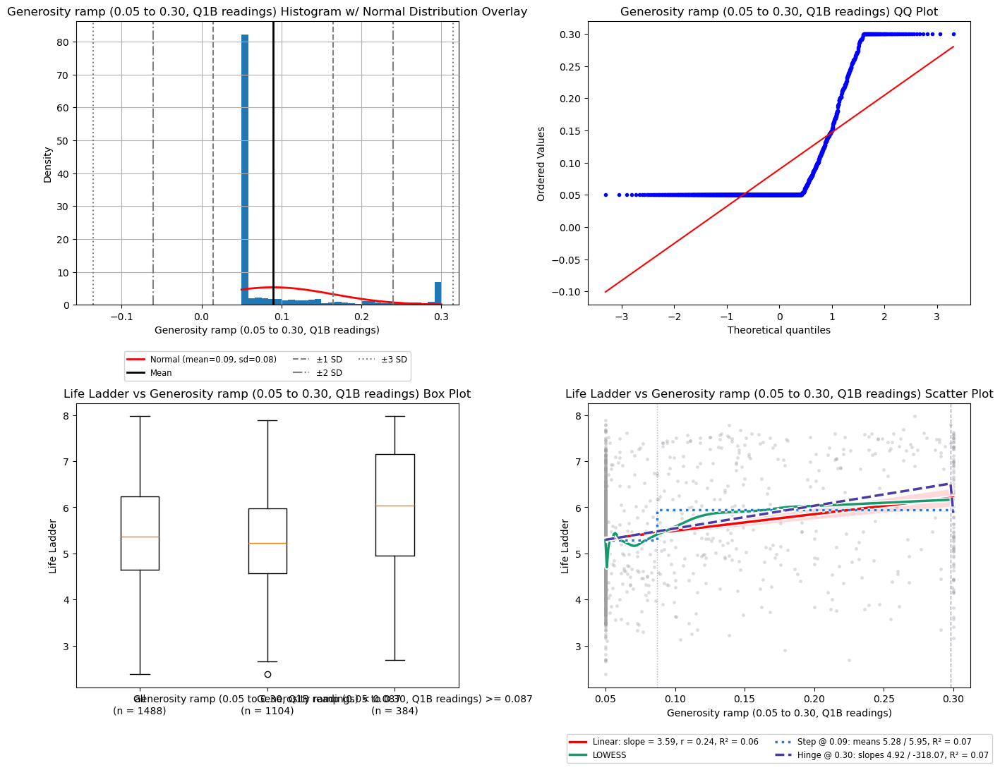

In [65]:
# fit on all gen_df rows, for illustration only (the scores below refit inside each training fold)
# lo = 0.05 is Q1B's LOWESS reading and hi = 0.30 its hinge threshold, for illustration only
gen_g_df = pd.DataFrame(
	{"Generosity ramp (0.05 to 0.30, Q1B readings)": np.ravel(features.Ramp(lo=0.05, hi=0.30).fit_transform(gen_X)), TARGET: gen_y},
	index=gen_df.index,
)
plotting.single_feature_plots(df=gen_g_df, feature="Generosity ramp (0.05 to 0.30, Q1B readings)", target=TARGET, threshold="auto");

#### Intervention G vs Target

In [66]:
gen_g_pipeline = Pipeline([("features", features.Ramp()), ("model", LinearRegression())])

gen_results["G nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gen_g_pipeline, param=("features__lo", "features__hi"), grid=gen_ramp_grid),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "G nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
G nested,1.074,0.046,0.893,0.038,0.060,0.025,-0.015,0.004,-3.786,0.001,candidate,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20


In [67]:
# (lo, hi) pair picked by the inner search in each of the 20 folds, sorted as numbers before formatting
gen_g_picked = sorted(
	features.picked_thresholds(gen_results["G nested"]["estimator"], param=("features__lo", "features__hi")))
gen_g_picked = [f"({lo:.2f}, {hi:.2f})" for lo, hi in gen_g_picked]
display(pd.Series(gen_g_picked).value_counts(sort=False).rename_axis("G nested picked (lo, hi)").to_frame("folds"))

,folds
"G nested picked (lo, hi)",
"(-0.01, 0.15)",1
"(0.07, 0.11)",1
"(0.07, 0.13)",11
"(0.07, 0.15)",1
"(0.09, 0.11)",1
"(0.09, 0.13)",3
"(0.11, 0.13)",2


### Intervention H | Skew fix control (Yeo-Johnson)

**What it targets**
Control. Q1B notes Generosity is moderately right skewed (skew 0.828) and lists Yeo-Johnson only if the skew needs fixing. Log and Box-Cox are not possible here, since the column has negative values (min -0.335).

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a right skewed column it stretches the crowded low end and compresses the right tail. The model becomes `Life Ladder = a + b·YJ(x)`.

**What it gives up**
It stretches exactly the region Q1B's LOWESS shows as flat (below about 0.05), giving the LR more room to fit differences there, and squeezes the upper part of the range, where the climb and the downturn are. In Social support Yeo-Johnson stretched the end where the bend was, so it was a candidate there. Here it stretches the flat end, so it is a control.

**Hypothesis**
Tests whether fixing the skew helps this column. Expected to tie with or lose to A.

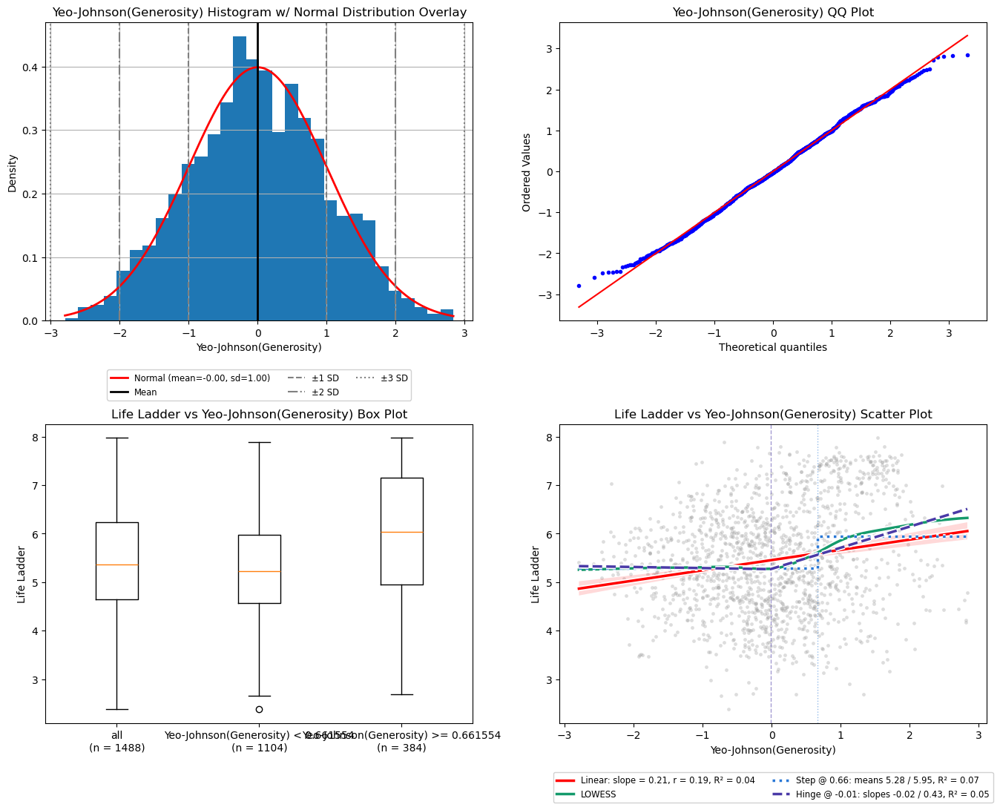

In [68]:
# fit on all gen_df rows, for illustration only (the scores below refit inside each training fold)
gen_h_df = pd.DataFrame(
	{"Yeo-Johnson(Generosity)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(gen_X)), TARGET: gen_y},
	index=gen_df.index,
)
plotting.single_feature_plots(df=gen_h_df, feature="Yeo-Johnson(Generosity)", target=TARGET, threshold="auto");

#### Intervention H vs Target

In [69]:
gen_results["H"] = pipelines.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=gen_X, y=gen_y, folds=gen_folds,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "H"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20
H,1.090,0.045,0.912,0.039,0.031,0.017,0.001,0.001,0.637,0.734,within noise,20


### Intervention I | Top cap (IQR fence clip)

**What it targets**
Candidate, not a control. Q1B flagged 31 high outliers above the upper IQR fence (0.397) and none below, notes that the downturn rests on the few rows in the right tail, and says capping the top tail is worth testing.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. Every value below the lower fence becomes the lower fence value, every value above the upper fence becomes the upper fence value, and every value between the fences is unchanged. Q1B's lower fence (-0.419) is below the column min (-0.335), so only the top is clipped. The model becomes `Life Ladder = a + b·clip(x)`.

| x | clip(x) (Q1B's fences -0.419 / 0.397) |
|---|---|
| 0.698 | 0.397 |
| 0.50 | 0.397 |
| 0.20 | 0.20 |
| -0.335 | -0.335 |

With only the top clipped, I is the same shape as C with t at the upper fence. The 31 rows above the fence sit inside the top 5% of rows that the guard keeps C's nested t out of, so I tests a cap that C nested cannot reach.

**What it gives up**
Capping reduces the tail rows' pull on the slope, but they still get the top prediction, so I cannot follow the downturn.

**Hypothesis**
Expected to beat A by a small margin, from removing the tail's pull on the slope.

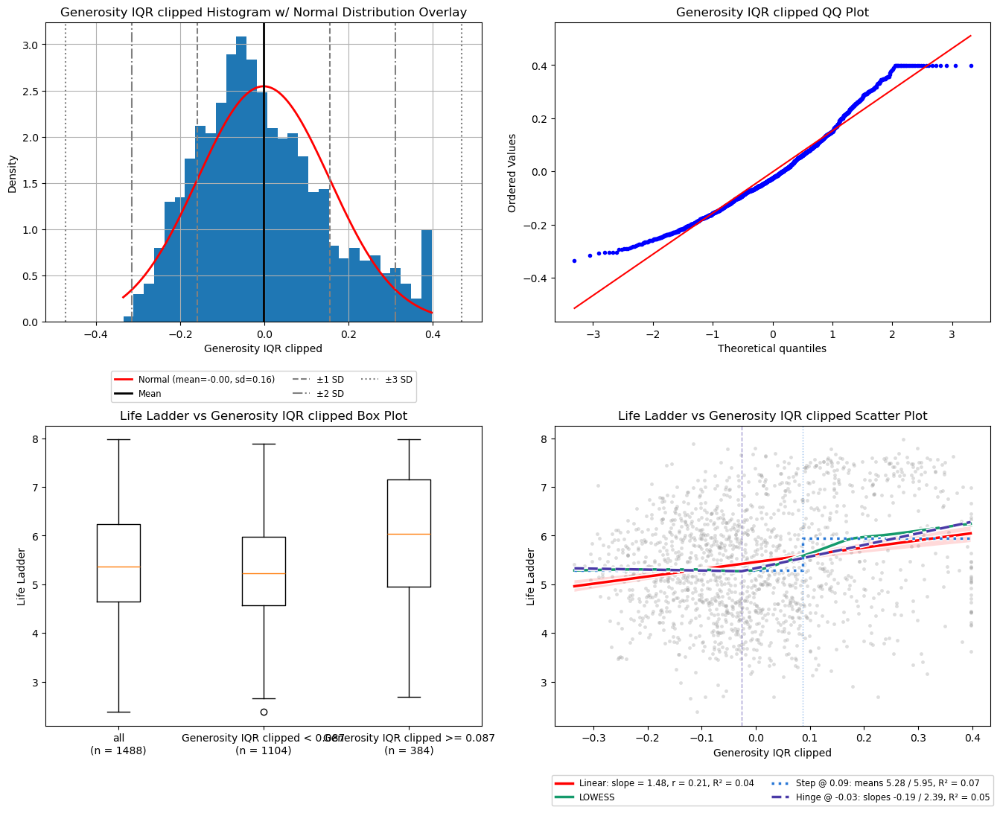

In [70]:
# fit on all gen_df rows, for illustration only (the scores below refit inside each training fold)
gen_i_df = pd.DataFrame(
	{"Generosity IQR clipped": np.ravel(features.IQRClip().fit_transform(gen_X)), TARGET: gen_y},
	index=gen_df.index,
)
plotting.single_feature_plots(df=gen_i_df, feature="Generosity IQR clipped", target=TARGET, threshold="auto");

#### Intervention I vs Target

In [71]:
gen_results["I"] = pipelines.evaluate_pipeline(
	Pipeline([("features", features.IQRClip()), ("model", LinearRegression())]),
	X=gen_X, y=gen_y, folds=gen_folds,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "I"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
I,1.086,0.044,0.908,0.039,0.039,0.018,-0.004,0.001,-3.902,0.0,candidate,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20


### Intervention J | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Generosity can explain. B to I each force one shape (flat start, cap, bend, jump, ramp, power curve, clip). J is the only option that can follow the flat start, the climb and the downturn together, and it tells whether the simpler shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If J scores about the same as the best of B to I:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If J is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention J vs Target

In [72]:
gen_j_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

gen_results["J nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gen_j_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=gen_X, y=gen_y, folds=gen_folds, return_estimator=True,
)
display(scoring.results_df({k: gen_results[k] for k in ["A", "J nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
J nested,1.068,0.043,0.885,0.036,0.071,0.026,-0.021,0.007,-3.033,0.003,candidate,20
A,1.089,0.045,0.910,0.039,0.033,0.019,0.000,NaN,NaN,NaN,baseline,20


In [73]:
# number of knots picked by the inner search in each of the 20 folds
gen_j_picked = features.picked_thresholds(gen_results["J nested"]["estimator"], param="features__n_knots")
display(pd.Series(gen_j_picked).astype(int).value_counts().sort_index().rename_axis("J nested picked n_knots").to_frame("folds"))

,folds
J nested picked n_knots,
4,7
6,8
8,1
10,4


### Comparison

In [74]:
display(scoring.results_df(gen_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
J nested,1.068,0.043,0.885,0.036,0.071,0.026,-0.021,0.007,-3.033,0.003,0.024,significant,20
E fixed (t=0.087),1.072,0.044,0.892,0.037,0.064,0.022,-0.017,0.003,-5.432,0.000,0.000,significant,20
F fixed (t=0.087),1.072,0.044,0.891,0.037,0.063,0.022,-0.017,0.004,-4.906,0.000,0.001,significant,20
G nested,1.074,0.046,0.893,0.038,0.060,0.025,-0.015,0.004,-3.786,0.001,0.006,significant,20
F nested,1.076,0.046,0.894,0.038,0.057,0.024,-0.013,0.005,-2.500,0.011,0.038,significant,20
E nested,1.076,0.046,0.895,0.038,0.056,0.025,-0.013,0.005,-2.562,0.010,0.038,significant,20
D fixed (t=0.30),1.079,0.043,0.902,0.037,0.051,0.019,-0.010,0.004,-2.817,0.006,0.033,significant,20
D nested,1.080,0.043,0.902,0.038,0.050,0.019,-0.010,0.004,-2.700,0.007,0.035,significant,20
C fixed (t=0.30),1.084,0.044,0.907,0.039,0.043,0.019,-0.005,0.001,-3.944,0.000,0.005,significant,20


## Generosity Results

- **A is weak:** rmse 1.089 and r2 0.033, the lowest r2 of the three attributes so far. Every gain below is small against that: the best Δrmse vs A is -0.021 and the best r2 is 0.071.
- **11 of the 13 interventions are significant.** After the Holm adjustment, every one of them has `p (Holm)` of 0.038 or less. Only B nested (Δ -0.002, Δ / SE -0.821) and H (+0.001) are within noise.
- **The step is the best simple shape, as expected.** E fixed at t = 0.087 has Δ -0.017 and the largest Δ / SE (-5.432), so its gain is the most consistent across the folds. E nested picked t between 0.09 and 0.13 in all 20 folds (0.09 in 15). F ties E exactly (fixed -0.017, nested -0.013 for both), so the raw column adds nothing next to the indicator. G (ramp) picked narrow ramps, lo between 0.07 and 0.11 and hi between 0.11 and 0.15 in 19 of 20 folds, and scores between E fixed and E nested (Δ -0.015): the climb behaves like a sharp jump, not a gradual rise.
- **J, the flexible spline ceiling, scores best** (rmse 1.068, r2 0.071), but its edge over E fixed is only 0.004 rmse. It picked more knots than in the earlier sections (4 in 7 folds, 6 in 8, 8 in 1, 10 in 4).
- **The downturn shapes give small gains.** D (raw + hinge) has Δ -0.010 in both variants, C (cap at the hinge) -0.005 and I (IQR clip) -0.004. D nested picked 0.29 or 0.31 in all 20 folds, so the picks stayed at Q1B's 0.30 and did not move to the flat-start bend.
- **Hypotheses that did not hold:** B was expected to beat A and is within noise, with picks between -0.07 and -0.03 in 19 of 20 folds. Forcing the bottom flat does not help on its own. The other hypotheses held, including the H control (Yeo-Johnson), which ties A.

#### Carry forward

- **E (indicator `1[x < t]`)** as the main candidate for the multi-feature model, with t fixed at 0.087 or searched in each fold (the nested picks fell between 0.09 and 0.13). It is a single binary column.
- **J (cubic spline, 4 to 10 knots)** as the flexible option, to check whether its small edge over E holds once the other features are in the model.
- **D (raw + hinge at 0.30)** as a lower priority alternative that also covers the downturn.
- **Generosity as a whole stays a candidate to drop.** Even its best shape only lifts r2 from 0.033 to 0.071, so the multi-feature stage should keep it only if E clears the noise threshold there.
- **Drop:** B, C, F, G, H and I. F and G tie or trail E with an extra column or threshold, and C and I give the smallest gains.

## Health Life Expectancy

Rows missing Healthy life expectancy are dropped. Rows missing other attributes are kept, since only Healthy life expectancy is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported for the same shape (the hinge or the step).
- **nested** variants search t with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**The grid differs from the earlier sections.** Healthy life expectancy is measured in years and runs from 32.3 to 77.1, so the 0.05 to 0.95 grid used for Corruption and Social support lies entirely outside it. Here t is searched from 33 to 77 (step 0.5), and the 5% guard trims it to the range printed below. D searches (t1, t2) pairs with t1 < t2 from 33 to 77 (step 1, to keep the number of pairs small), with the guard applied to both thresholds.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [75]:
hle_col = COLUMNS['HLEAB']['col']
hle_df = train_df[[hle_col, TARGET]].dropna(subset=[hle_col])
hle_X = hle_df[[hle_col]]
hle_y = hle_df[TARGET]

hle_grid = np.round(np.arange(33, 77.01, 0.5), 1)
hle_pair_values = np.round(np.arange(33, 77.01, 1.0), 1)
hle_pair_grid = [(t1, t2) for t1 in hle_pair_values for t2 in hle_pair_values if t1 < t2]

hle_folds = pipelines.make_folds(hle_X, seeds=SEEDS)
hle_results = {}

hle_x = hle_X[hle_col].to_numpy()
hle_guarded = [t for t in hle_grid if min(np.mean(hle_x < t), np.mean(hle_x >= t)) >= features.MIN_GROUP_FRAC]
hle_pair_guarded = [t for t in hle_pair_values if min(np.mean(hle_x < t), np.mean(hle_x >= t)) >= features.MIN_GROUP_FRAC]
print(f"rows used: {len(hle_df)} of {len(train_df)}")
print(f"folds: {len(hle_folds)}")
print(f"threshold grid after the 5% guard (all rows): {hle_guarded[0]} to {hle_guarded[-1]}")
print(f"pair grid after the 5% guard (all rows): {hle_pair_guarded[0]} to {hle_pair_guarded[-1]}")

rows used: 1522 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 49.5 to 72.5
pair grid after the 5% guard (all rows): 50.0 to 72.0


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Healthy life expectancy value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow the gentle rise below about 57 and the steeper rise above it that LOWESS shows in Q1B.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model. Q1B's linear fit had R² 0.56 (slope 0.11), so A's r2 is expected to be near 0.56.

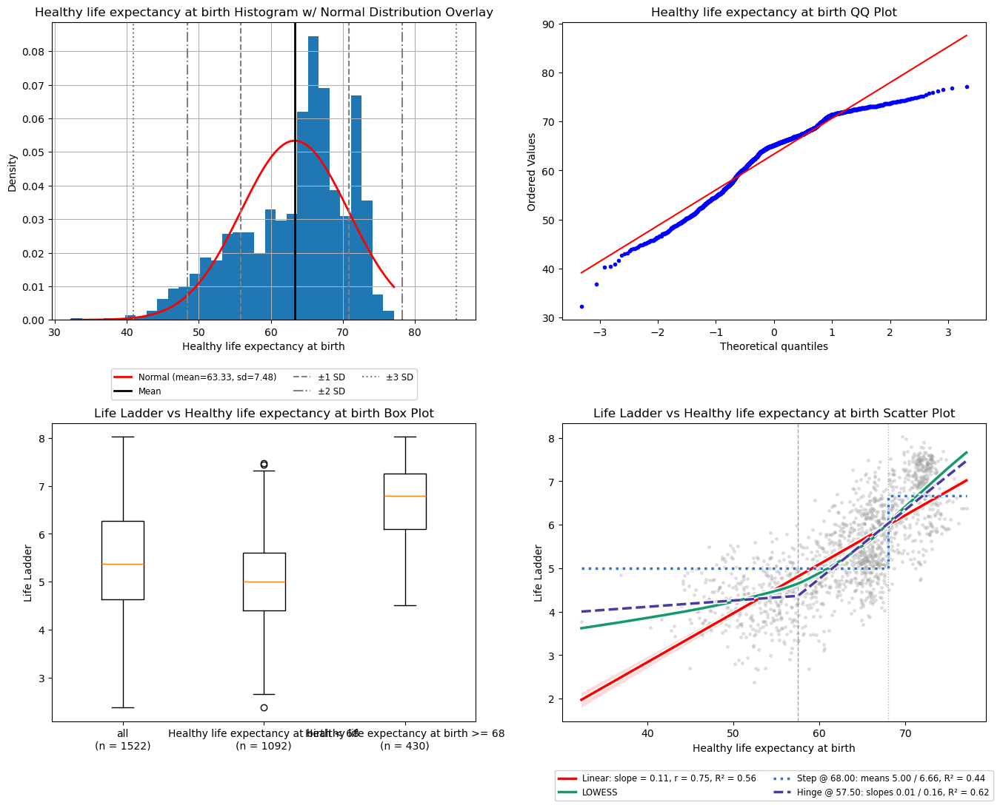

In [76]:
plotting.single_feature_plots(df=hle_df, feature=hle_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [77]:
hle_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=hle_X, y=hle_y, folds=hle_folds,
)
display(scoring.results_df({k: hle_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.741,0.026,0.608,0.019,0.562,0.025,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Flat start (high-side hinge alone)

**What it targets**
In Q1B's scatter plot, LOWESS is nearly flat below about 57 and steep above, and Q1B's hinge fit at 57.5 found a slope of only 0.01 below the hinge. A LinearRegression on the raw value fits one slope across the whole range, so it predicts Life Ladder differences between the low rows that the hinge fit says are not there.

**What the intervention does**
Replaces the raw value with one new feature, the distance above a threshold `t`:

`h = max(0, x - t)`

| x | h (t = 57.5) |
|---|---|
| 75 | 17.5 |
| 65 | 7.5 |
| 57.5 | 0 |
| 45 | 0 |

No rows are dropped, and the high values keep their order and spacing. The model becomes `Life Ladder = a + b·h`:
- **Above t:** the prediction moves in a straight line with the distance above t.
- **At or below t:** h = 0, so every row gets the same prediction `a`. The bottom of the range is forced flat.

**What it gives up**
Every difference between values below t is erased. That is only safe if those differences carry no information about Life Ladder. LOWESS still rises gently below about 57, so if that rise is real, B removes it.

**Variants**
- **B fixed (t = 57.5):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 33 to 77 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the flat start.

**Hypothesis**
If the bottom of the range is truly flat, forcing it flat removes noise the raw slope was fitting. Since Q1B's slope below 57.5 is only 0.01, B is expected to beat A by more than the noise threshold and to tie with C. Because LOWESS still rises gently below 57, the nested picks may move below 57.5.

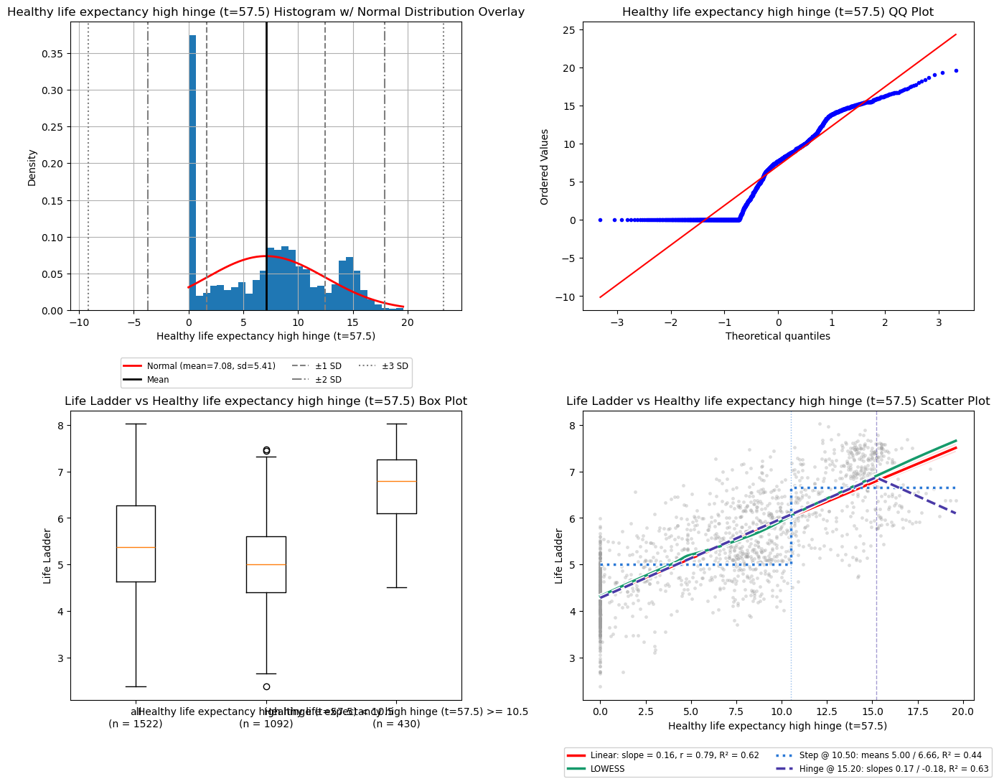

In [78]:
# fit on all hle_df rows, for illustration only (the scores below refit inside each training fold)
hle_b_df = pd.DataFrame(
	{"Healthy life expectancy high hinge (t=57.5)": np.ravel(features.HighHinge(t=57.5).fit_transform(hle_X)), TARGET: hle_y},
	index=hle_df.index,
)
plotting.single_feature_plots(df=hle_b_df, feature="Healthy life expectancy high hinge (t=57.5)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [79]:
hle_b_pipeline = Pipeline([("features", features.HighHinge(t=57.5)), ("model", LinearRegression())])

hle_results["B fixed (t=57.5)"] = pipelines.evaluate_pipeline(
	hle_b_pipeline,
	X=hle_X, y=hle_y, folds=hle_folds,
)
hle_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(hle_b_pipeline, param="features__t", grid=hle_grid),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "B fixed (t=57.5)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B fixed (t=57.5),0.695,0.023,0.565,0.019,0.615,0.022,-0.046,0.010,-4.778,0.0,candidate,20
B nested,0.695,0.022,0.566,0.018,0.614,0.022,-0.046,0.009,-4.949,0.0,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


In [80]:
# threshold picked by the inner search in each of the 20 folds
hle_b_picked = features.picked_thresholds(hle_results["B nested"]["estimator"], param="features__t")
display(pd.Series(hle_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
56.5,6
57.0,11
57.5,3


### Intervention C | Linear spline (raw + hinge)

**What it targets**
Q1B's hinge fit at 57.5: slope 0.01 below and 0.16 above, with R² 0.62 against the linear fit's 0.56. Unlike B, C does not force the bottom flat, so it can keep a slope below t if the data support one.

**What the intervention does**
Keeps the raw value and adds the hinge from B as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 57.5) |
|---|---|
| 75 | [75, 17.5] |
| 65 | [65, 7.5] |
| 57.5 | [57.5, 0] |
| 45 | [45, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

Using the low-side hinge instead, `[x, max(0, t - x)]`, would give exactly the same predictions: the two hinges differ by `x - t`, which the raw column and the intercept already cover. Only the coefficients change, not the fit.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and C reduces to A with an extra parameter.

**Variants**
- **C fixed (t = 57.5):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 33 to 77 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
C is expected to beat A by more than the noise threshold, since Q1B's hinge R² (0.62) is above the linear R² (0.56). LOWESS bends gradually over a range rather than at one sharp corner, so the nested picks may spread out and move away from 57.5.

#### Intervention C vs Target

In [81]:
hle_c_pipeline = Pipeline([("features", features.HighHinge(t=57.5, keep_raw=True)), ("model", LinearRegression())])

hle_results["C fixed (t=57.5)"] = pipelines.evaluate_pipeline(
	hle_c_pipeline,
	X=hle_X, y=hle_y, folds=hle_folds,
)
hle_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(hle_c_pipeline, param="features__t", grid=hle_grid),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "C fixed (t=57.5)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=57.5),0.695,0.022,0.564,0.019,0.615,0.022,-0.047,0.009,-5.303,0.0,candidate,20
C nested,0.695,0.022,0.565,0.018,0.614,0.022,-0.046,0.009,-5.185,0.0,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


In [82]:
# threshold picked by the inner search in each of the 20 folds
hle_c_picked = features.picked_thresholds(hle_results["C nested"]["estimator"], param="features__t")
display(pd.Series(hle_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
56.5,1
57.0,5
57.5,8
58.0,6


### Intervention D | Two-bend linear spline

**What it targets**
Whether the top of the range needs its own slope. Q1B suggests a transform that stretches the top end, while LOWESS looks close to straight above the bend. C has one slope for everything above t, and D lets the top bend again, up or down.

**What the intervention does**
Keeps the raw value and adds two high-side hinges, one at each threshold, with t1 < t2:

`[x, max(0, x - t1), max(0, x - t2)]`

For t1 = 57.5 (Q1B's hinge) and t2 = 70 (an example value, not a fit):

| x | features [x, h1, h2] (t1 = 57.5, t2 = 70) |
|---|---|
| 75 | [75, 17.5, 5] |
| 69 | [69, 11.5, 0] |
| 60 | [60, 2.5, 0] |
| 45 | [45, 0, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t1) + d·max(0, x - t2)`, three straight segments joined at t1 and t2:
- **At or below t1:** both hinges are 0, so the prediction is a line with slope b.
- **Between t1 and t2:** only the first hinge is above 0, so the prediction is a line with slope b + c.
- **Above t2:** both hinges are above 0, so the prediction is a line with slope b + c + d.

The segments meet at t1 and t2, so the prediction has corners there but no jumps. No plot cell, since the feature is three columns.

**What it gives up**
Two extra coefficients and two thresholds to search instead of one, which gives the model and the inner search more room to fit noise in the training folds.

**Variants**
- **D nested only.** Q1B fitted only one hinge, so there is no fixed pair. t1 and t2 are searched together over every pair from 33 to 77 (step 1) with t1 < t2, inside each training fold (inner 4-fold CV), and both t1 and t2 must leave at least 5% of the training fold's rows on each side. The validation rows never influence the pair, and the pairs it picks show where the data place the two bends.

**Hypothesis**
If the slope above the bend is the same all the way up, d ends up near 0 and D ties with C. If the top flattens or steepens, D beats C.

#### Intervention D vs Target

In [83]:
hle_d_pipeline = Pipeline([
	("features", FeatureUnion([("low", features.HighHinge(t=57.5, keep_raw=True)), ("high", features.HighHinge(t=70))])),
	("model", LinearRegression()),
])

hle_results["D nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(hle_d_pipeline, param=("features__low__t", "features__high__t"), grid=hle_pair_grid),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "D nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D nested,0.692,0.026,0.557,0.019,0.618,0.025,-0.049,0.008,-6.107,0.0,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


In [84]:
# (t1, t2) pair picked by the inner search in each of the 20 folds, sorted as numbers before formatting
hle_d_picked = sorted(
	features.picked_thresholds(hle_results["D nested"]["estimator"], param=("features__low__t", "features__high__t")))
hle_d_picked = [f"({t1:.0f}, {t2:.0f})" for t1, t2 in hle_d_picked]
display(pd.Series(hle_d_picked).value_counts(sort=False).rename_axis("D nested picked (t1, t2)").to_frame("folds"))

,folds
"D nested picked (t1, t2)",
"(57, 73)",3
"(58, 72)",4
"(58, 73)",4
"(59, 72)",4
"(59, 73)",1
"(66, 71)",1
"(66, 72)",3


### Intervention E | Indicator alone

**What it targets**
Q1B's step fit at 68 split the rows into two groups with mean Life Ladder 5.00 below and 6.66 above, with 1092 rows below and 430 at or above in the box plot, and R² 0.44. E tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 68) |
|---|---|
| 75 | 0 |
| 68 | 0 |
| 65 | 1 |
| 45 | 1 |

The model becomes `Life Ladder = a + b·i`, which predicts one mean per side:
- **At or above t:** i = 0, so every row gets `a`, the mean Life Ladder of the training rows above t.
- **Below t:** i = 1, so every row gets `a + b`, the mean Life Ladder of the training rows below t.

No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at 45 gets the same prediction as a row at 65. The change at t is a hard jump, so two rows just either side of t get predictions that differ by the full b.

**Variants**
- **E fixed (t = 68):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **E nested:** t is searched from 33 to 77 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the split.

**Hypothesis**
If most of the signal is just "below vs above t", E matches or beats A with a simpler shape. Q1B's step R² (0.44) is below the linear R² (0.56), so E is expected to lose to A.

#### Intervention E vs Target

In [85]:
hle_e_pipeline = Pipeline([("features", features.Indicator(t=68)), ("model", LinearRegression())])

hle_results["E fixed (t=68)"] = pipelines.evaluate_pipeline(
	hle_e_pipeline,
	X=hle_X, y=hle_y, folds=hle_folds,
)
hle_results["E nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(hle_e_pipeline, param="features__t", grid=hle_grid),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "E fixed (t=68)", "E nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20
E fixed (t=68),0.838,0.029,0.681,0.025,0.441,0.031,0.096,0.018,5.241,1.0,worse,20
E nested,0.853,0.025,0.694,0.023,0.420,0.027,0.112,0.015,7.577,1.0,worse,20


In [86]:
# threshold picked by the inner search in each of the 20 folds
hle_e_picked = features.picked_thresholds(hle_results["E nested"]["estimator"], param="features__t")
display(pd.Series(hle_e_picked).value_counts().sort_index().rename_axis("E nested picked t").to_frame("folds"))

,folds
E nested picked t,
61.0,2
61.5,2
65.5,1
68.0,15


### Intervention F | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range.

**What the intervention does**
Keeps the raw value and adds the indicator from E as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 68) |
|---|---|
| 75 | [75, 0] |
| 68 | [68, 0] |
| 65 | [65, 1] |
| 45 | [45, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot bend: it cannot make the top steeper than the low side.

**Variants**
- **F fixed (t = 68):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **F nested:** t is searched from 33 to 77 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
Tests a jump at t on top of the trend. If there is a level shift at t, F beats A by more than the noise threshold. Q1B's LOWESS shows a bend rather than a jump, so F is expected to beat A by less than C.

#### Intervention F vs Target

In [87]:
hle_f_pipeline = Pipeline([("features", features.Indicator(t=68, keep_raw=True)), ("model", LinearRegression())])

hle_results["F fixed (t=68)"] = pipelines.evaluate_pipeline(
	hle_f_pipeline,
	X=hle_X, y=hle_y, folds=hle_folds,
)
hle_results["F nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(hle_f_pipeline, param="features__t", grid=hle_grid),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "F fixed (t=68)", "F nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
F fixed (t=68),0.699,0.025,0.569,0.018,0.610,0.023,-0.042,0.007,-5.888,0.0,candidate,20
F nested,0.703,0.024,0.572,0.017,0.606,0.023,-0.038,0.006,-5.902,0.0,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


In [88]:
# threshold picked by the inner search in each of the 20 folds
hle_f_picked = features.picked_thresholds(hle_results["F nested"]["estimator"], param="features__t")
display(pd.Series(hle_f_picked).value_counts().sort_index().rename_axis("F nested picked t").to_frame("folds"))

,folds
F nested picked t,
50.0,1
68.0,14
68.5,5


### Intervention G | Stretch the top (square)

**What it targets**
Candidate. The same bend as B and C, gentle at the low end and steeper above, but with a smooth curve and no threshold to pick. Q1B's Special Treatment lists a transform that stretches the top end (ex squaring).

**What the intervention does**
Replaces the raw value with its square:

`z = x²`

| x | x² |
|---|---|
| 40 | 1600 |
| 50 | 2500 |
| 60 | 3600 |
| 70 | 4900 |
| 77 | 5929 |

Squaring spreads out the values near the top more than those near the bottom: the gap from 40 to 50 becomes 900, while the same 10 year gap from 60 to 70 becomes 1300. So the top is stretched, but only mildly across 32.3 to 77.1. The model becomes `Life Ladder = a + b·x²`, a straight line in x², which is a curve in x that gets steeper toward the top.

**What it gives up**
It assumes the bend has the fixed shape of x², with no parameter to adjust it. The curve keeps steepening toward the top, while LOWESS looks close to straight above the bend, and its bend is mild compared with the hinge's slopes of 0.01 below and 0.16 above 57.5.

**Hypothesis**
Expected to beat A, since it bends the fit the same way as the hinge. Expected to trail C, since the bend of x² is mild over this range.

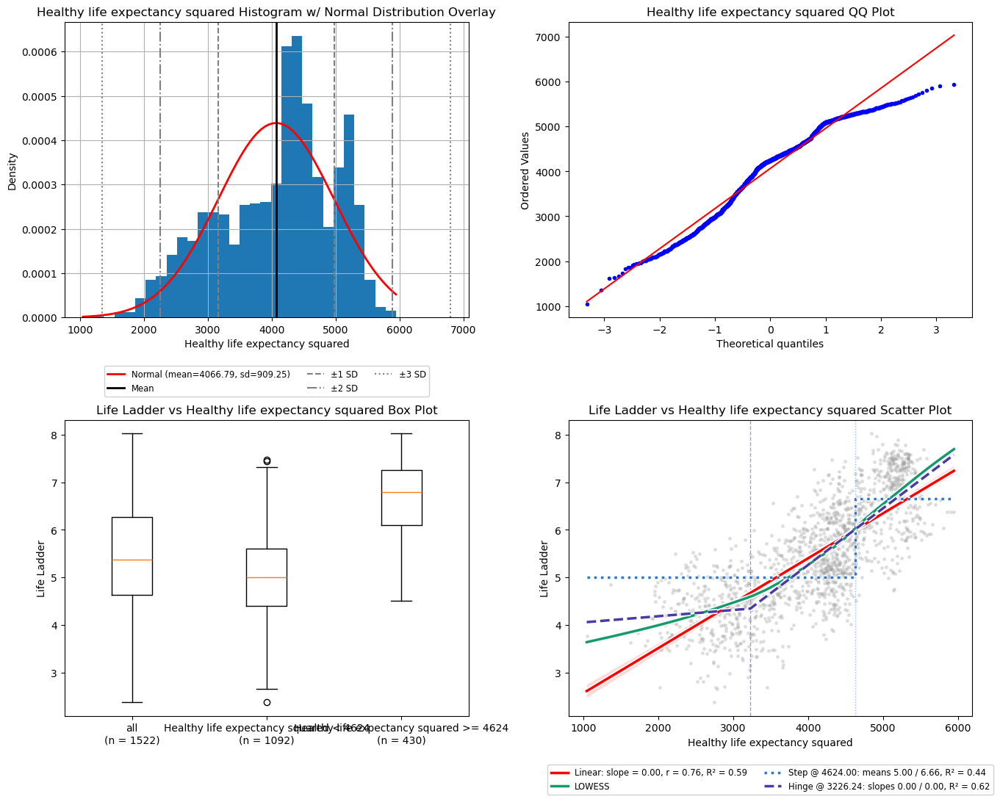

In [89]:
# fit on all hle_df rows, for illustration only (the scores below refit inside each training fold)
hle_g_df = pd.DataFrame(
	{"Healthy life expectancy squared": np.ravel(FunctionTransformer(np.square).fit_transform(hle_X)), TARGET: hle_y},
	index=hle_df.index,
)
plotting.single_feature_plots(df=hle_g_df, feature="Healthy life expectancy squared", target=TARGET, threshold="auto");

#### Intervention G vs Target

In [90]:
hle_results["G"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.square)), ("model", LinearRegression())]),
	X=hle_X, y=hle_y, folds=hle_folds,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "G"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
G,0.723,0.024,0.593,0.019,0.583,0.024,-0.018,0.002,-7.539,0.0,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


### Intervention H | Stretch the top (Yeo-Johnson)

**What it targets**
The same bend as G, with the amount of stretch fit to the data instead of fixed. H is a candidate: Healthy life expectancy is moderately left skewed (skew -0.723), with a broad lower shoulder (about 45 to 62) and a tall peak (about 64 to 74), and Q1B lists Yeo-Johnson as a candidate.

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a left skewed column it stretches the crowded top end and compresses the low tail. That is the same direction as the bend Q1B saw, so it both reduces the skew and bends the fit the right way. The model becomes `Life Ladder = a + b·YJ(x)`.

Box-Cox is not run separately: for positive x, Yeo-Johnson is Box-Cox applied to x + 1, which over 32.3 to 77.1 gives nearly the same shape.

**What it gives up**
The power is chosen to make the histogram symmetric, not to fit Life Ladder, so the amount of stretch at the top may be more or less than the bend needs. A power curve also keeps steepening toward the top, while LOWESS looks close to straight above the bend.

**Hypothesis**
Expected to beat A. It may overshoot at the top and trail C. Compared with G, it shows whether a fitted power beats the fixed square.

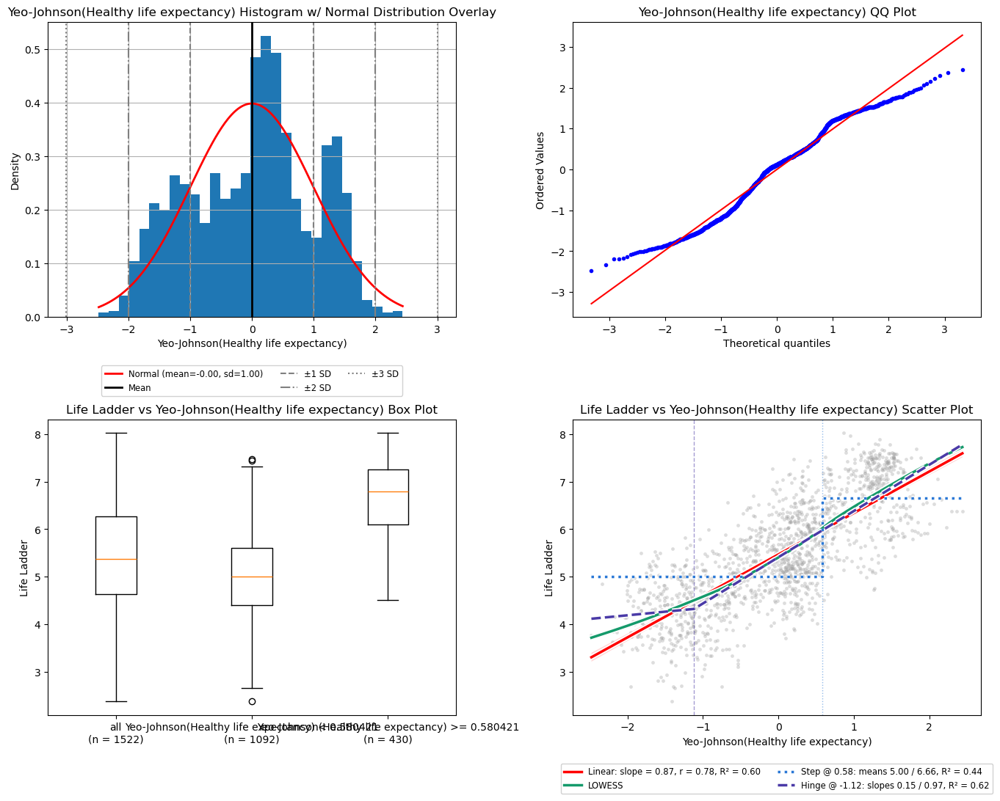

In [91]:
# fit on all hle_df rows, for illustration only (the scores below refit inside each training fold)
hle_h_df = pd.DataFrame(
	{"Yeo-Johnson(Healthy life expectancy)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(hle_X)), TARGET: hle_y},
	index=hle_df.index,
)
plotting.single_feature_plots(df=hle_h_df, feature="Yeo-Johnson(Healthy life expectancy)", target=TARGET, threshold="auto");

#### Intervention H vs Target

In [92]:
hle_results["H"] = pipelines.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "H"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
H,0.706,0.024,0.575,0.019,0.603,0.023,-0.035,0.006,-6.331,0.0,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


In [93]:
# Yeo-Johnson power fitted on each of the 20 training folds
hle_h_lambdas = pd.Series([estimator.named_steps["features"].lambdas_[0] for estimator in hle_results["H"]["estimator"]])
display(hle_h_lambdas.describe()[["min", "50%", "max"]].rename({"50%": "median"}).round(2).rename_axis("H fitted λ").to_frame("value"))

,value
H fitted λ,
min,3.48
median,3.61
max,3.72


### Intervention I | Log control

**What it targets**
Control. Log stretches the low end and squeezes the top, the opposite of the bend Q1B saw. Q1B has no note against it. It is included to confirm which end needs stretching.

**What the intervention does**
Replaces the raw value with its natural log:

`z = log(x)`

| x | log(x) |
|---|---|
| 35 | 3.555 |
| 45 | 3.807 |
| 55 | 4.007 |
| 65 | 4.174 |
| 75 | 4.317 |

The log spreads out the values near the bottom and squeezes those near the top: the gap from 35 to 45 becomes about 0.25, while the same 10 year gap from 65 to 75 becomes about 0.14. The model becomes `Life Ladder = a + b·log(x)`, a straight line in log(x), which is a curve in x that is steep at the low end and flat at the top. The column min is 32.3, so x is always positive and the log is always defined.

**What it gives up**
It bends the fit the wrong way: toward a curve that is steep at the low end and flat at the top, the opposite of the bend Q1B saw.

**Hypothesis**
Tests whether stretching the low end helps. Expected to tie with or lose to A.

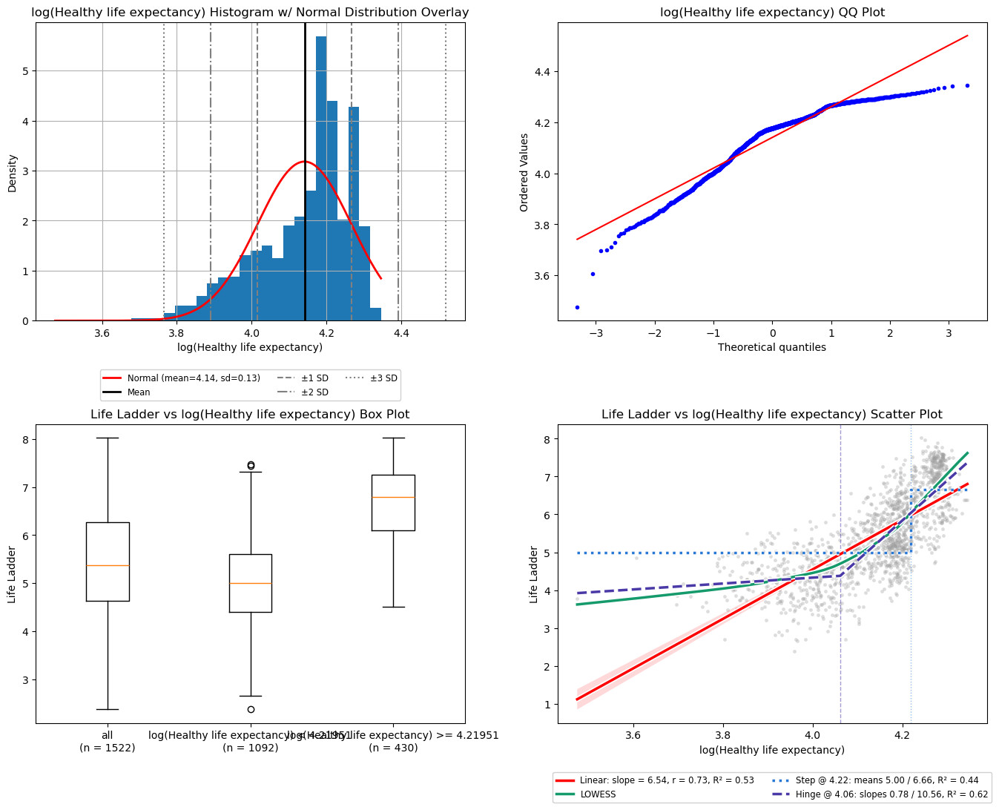

In [94]:
# fit on all hle_df rows, for illustration only (the scores below refit inside each training fold)
hle_i_df = pd.DataFrame(
	{"log(Healthy life expectancy)": np.ravel(FunctionTransformer(np.log).fit_transform(hle_X)), TARGET: hle_y},
	index=hle_df.index,
)
plotting.single_feature_plots(df=hle_i_df, feature="log(Healthy life expectancy)", target=TARGET, threshold="auto");

#### Intervention I vs Target

In [95]:
hle_results["I"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.log)), ("model", LinearRegression())]),
	X=hle_X, y=hle_y, folds=hle_folds,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "I"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20
I,0.766,0.028,0.627,0.020,0.532,0.028,0.025,0.003,7.727,1.0,worse,20


### Intervention J | Low tail clip (IQR fence clip)

**What it targets**
Candidate, not a control. Q1B flagged 7 low outliers below the lower IQR fence (43.048), down to the column min of 32.3, and none above the upper fence, with no note to clip or keep them. They sit in the low, flatter part of the range, where the straight line sits below LOWESS, so they pull the single slope. Clipping pulls them in to the fence.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. Every value below the lower fence becomes the lower fence value, every value above the upper fence becomes the upper fence value, and every value between the fences is unchanged. Q1B's upper fence (83.827) is above the column max (77.1), so only the bottom is clipped. The model becomes `Life Ladder = a + b·clip(x)`.

| x | clip(x) (Q1B's fences 43.048 / 83.827) |
|---|---|
| 32.3 | 43.048 |
| 40.0 | 43.048 |
| 60.0 | 60.0 |
| 77.1 | 77.1 |

Once a hinge flattens the low end (B), clipping changes nothing there, so J only matters for a model that uses the raw slope.

**What it gives up**
The detail in the low tail: the 7 rows below the fence all get the same feature value and so the same prediction. With only 7 rows, any gain is small.

**Hypothesis**
Expected to beat A by a small margin, from reducing the low tail's pull on the slope.

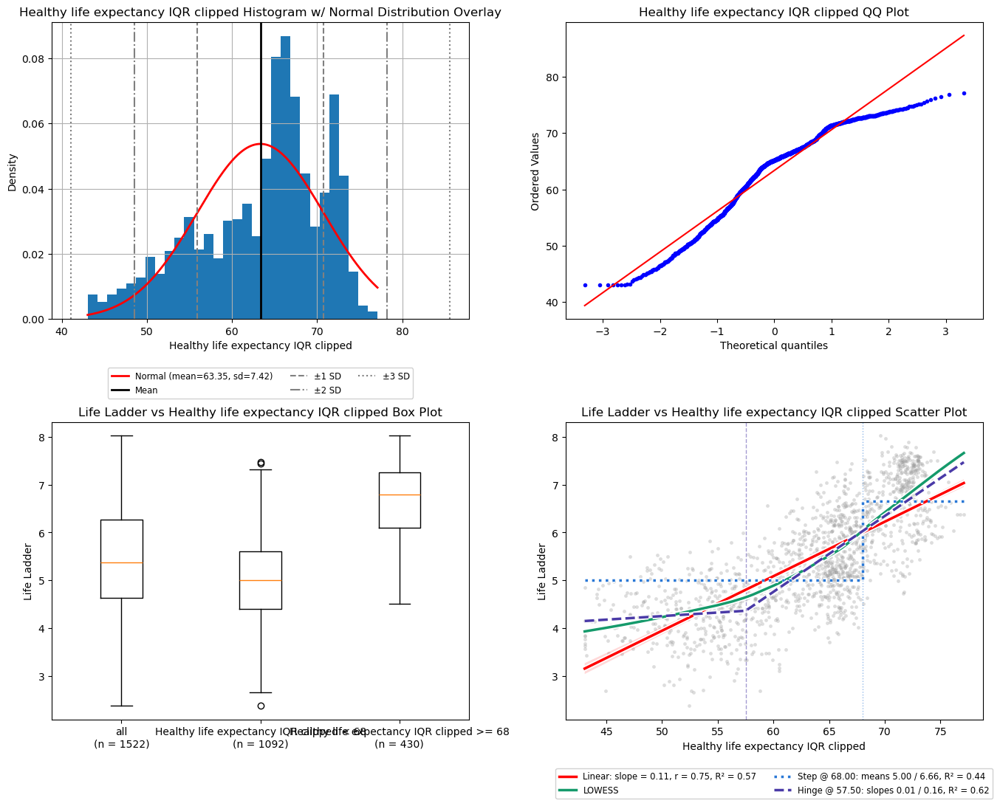

In [96]:
# fit on all hle_df rows, for illustration only (the scores below refit inside each training fold)
hle_j_df = pd.DataFrame(
	{"Healthy life expectancy IQR clipped": np.ravel(features.IQRClip().fit_transform(hle_X)), TARGET: hle_y},
	index=hle_df.index,
)
plotting.single_feature_plots(df=hle_j_df, feature="Healthy life expectancy IQR clipped", target=TARGET, threshold="auto");

#### Intervention J vs Target

In [97]:
hle_results["J"] = pipelines.evaluate_pipeline(
	Pipeline([("features", features.IQRClip()), ("model", LinearRegression())]),
	X=hle_X, y=hle_y, folds=hle_folds,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "J"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
J,0.738,0.024,0.606,0.019,0.566,0.025,-0.004,0.002,-1.48,0.078,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


### Intervention K | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Healthy life expectancy can explain. B to J each force one shape (flat start, bend, two bends, jump, square, power curve, log curve, clip). K tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If K scores about the same as the best of B to J:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If K is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention K vs Target

In [98]:
hle_k_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

hle_results["K nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(hle_k_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=hle_X, y=hle_y, folds=hle_folds, return_estimator=True,
)
display(scoring.results_df({k: hle_results[k] for k in ["A", "K nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
K nested,0.687,0.026,0.548,0.021,0.623,0.025,-0.054,0.01,-5.558,0.0,candidate,20
A,0.741,0.026,0.608,0.019,0.562,0.025,0.000,NaN,NaN,NaN,baseline,20


In [99]:
# number of knots picked by the inner search in each of the 20 folds
hle_k_picked = features.picked_thresholds(hle_results["K nested"]["estimator"], param="features__n_knots")
display(pd.Series(hle_k_picked).astype(int).value_counts().sort_index().rename_axis("K nested picked n_knots").to_frame("folds"))

,folds
K nested picked n_knots,
5,7
6,1
8,4
10,8


### Comparison

In [100]:
display(scoring.results_df(hle_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
K nested,0.687,0.026,0.548,0.021,0.623,0.025,-0.054,0.010,-5.558,0.000,0.00,significant,20
D nested,0.692,0.026,0.557,0.019,0.618,0.025,-0.049,0.008,-6.107,0.000,0.00,significant,20
C fixed (t=57.5),0.695,0.022,0.564,0.019,0.615,0.022,-0.047,0.009,-5.303,0.000,0.00,significant,20
B fixed (t=57.5),0.695,0.023,0.565,0.019,0.615,0.022,-0.046,0.010,-4.778,0.000,0.00,significant,20
B nested,0.695,0.022,0.566,0.018,0.614,0.022,-0.046,0.009,-4.949,0.000,0.00,significant,20
C nested,0.695,0.022,0.565,0.018,0.614,0.022,-0.046,0.009,-5.185,0.000,0.00,significant,20
F fixed (t=68),0.699,0.025,0.569,0.018,0.610,0.023,-0.042,0.007,-5.888,0.000,0.00,significant,20
F nested,0.703,0.024,0.572,0.017,0.606,0.023,-0.038,0.006,-5.902,0.000,0.00,significant,20
H,0.706,0.024,0.575,0.019,0.603,0.023,-0.035,0.006,-6.331,0.000,0.00,significant,20


## Health Life Expectancy Results

- **A is strong:** rmse 0.741 and r2 0.562, in line with Q1B's linear R² of 0.56 and the highest A of the four attributes so far (Social support 0.493, Corruption 0.178, Generosity 0.033). Healthy life expectancy is not a candidate to drop.
- **10 of the 14 interventions are significant,** all with `p (Holm)` 0.00. J (IQR clip) is only a candidate (Δ -0.004, Δ / SE -1.480, `p (Holm)` 0.31), and I (+0.025), E fixed (+0.096) and E nested (+0.112) lose to A.
- **The flat start at about 57 is real and stable.** B (hinge alone) and C (raw + hinge) tie: Δ -0.046 for B fixed, B nested and C nested, -0.047 for C fixed, all with r2 0.614 or 0.615. So the raw slope below the bend adds nothing. B nested picked t between 56.5 and 57.5 in all 20 folds (56.5 or 57.0 in 17), and C nested between 56.5 and 58.0 in all 20.
- **The top needs little extra.** D (two bends) scores rmse 0.692 against C fixed's 0.695. Its first bend stayed at 57 to 59 with a second at 72 or 73 in 16 of 20 folds; the other 4 folds picked (66, 71) or (66, 72). K, the flexible spline ceiling, scores best (rmse 0.687, r2 0.623) and picked more knots than in the earlier sections (5 in 7 folds, 6 in 1, 8 in 4, 10 in 8), but the single hinge (rmse 0.695) captures most of its gain over A (0.741).
- **The top-stretching transforms help but trail the hinge.** H (Yeo-Johnson, fitted λ between 3.48 and 3.72) has Δ -0.035 and G (square) -0.018. The log control I loses to A (+0.025), so stretching the low end is the wrong direction. F (indicator + raw) has Δ -0.042 fixed and -0.038 nested, with picks at 68.0 or 68.5 in 19 of 20 folds, and trails C.
- **Hypotheses that did not hold:** C's nested picks were expected to spread out and move away from 57.5, but they stayed between 56.5 and 58.0. J was expected to beat A by a small margin and does pass the 1 SE rule, but it is not significant after the Holm adjustment. The other hypotheses held, including E losing to A and I tying or losing.

#### Carry forward

- **B (high-side hinge `max(0, x - t)`)** as the main candidate for the multi-feature model, with t fixed at 57.5 or searched in each fold (the nested picks fell between 56.5 and 57.5). It is a single column and ties C.
- **C (raw + hinge `[x, max(0, x - t)]`, t = 57.5)** as the equivalent alternative, in case a slope below the bend matters once the other features are in the model.
- **K (cubic spline, 5 to 10 knots)** as the flexible option, to check whether its edge over B and C holds in the multi-feature model.
- **D (two bends, at 57 to 59 and 72 to 73 in most folds)** and **H (Yeo-Johnson)** as lower priority alternatives: D needs two thresholds, and H needs none but trails the hinge (Δ -0.035 vs -0.046).
- **Drop:** E, F, G, I and J. Keep the 7 low outliers unclipped, since J is not significant and the hinge already flattens the low end.

## Negative Affect

Rows missing Negative affect are dropped. Rows missing other attributes are kept, since only Negative affect is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported for the same shape (the hinge or the step).
- **nested** variants search t with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**The grid differs from the earlier sections.** Negative affect runs from 0.083 to 0.705. The 0.05 to 0.95 grid (step 0.02) used for Corruption and Social support covers it, but the 5% guard leaves only a narrow band of it, and that grid holds only odd hundredths, so Q1B's hinge at 0.20 is not on it. Here t is searched from 0.08 to 0.70 (step 0.01), and the 5% guard trims it to the range printed below.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [101]:
na_col = COLUMNS['NA']['col']
na_df = train_df[[na_col, TARGET]].dropna(subset=[na_col])
na_X = na_df[[na_col]]
na_y = na_df[TARGET]

na_grid = np.round(np.arange(0.08, 0.701, 0.01), 2)

na_folds = pipelines.make_folds(na_X, seeds=SEEDS)
na_results = {}

na_x = na_X[na_col].to_numpy()
na_guarded = [t for t in na_grid if min(np.mean(na_x < t), np.mean(na_x >= t)) >= features.MIN_GROUP_FRAC]
print(f"rows used: {len(na_df)} of {len(train_df)}")
print(f"folds: {len(na_folds)}")
print(f"threshold grid after the 5% guard (all rows): {na_guarded[0]} to {na_guarded[-1]}")

rows used: 1545 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 0.16 to 0.41


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Negative affect value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow the nearly flat stretch below about 0.2 and the fall above it that LOWESS shows in Q1B.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model. Q1B's linear fit had R² 0.09 (slope -3.99), so A's r2 is expected to be near 0.09.

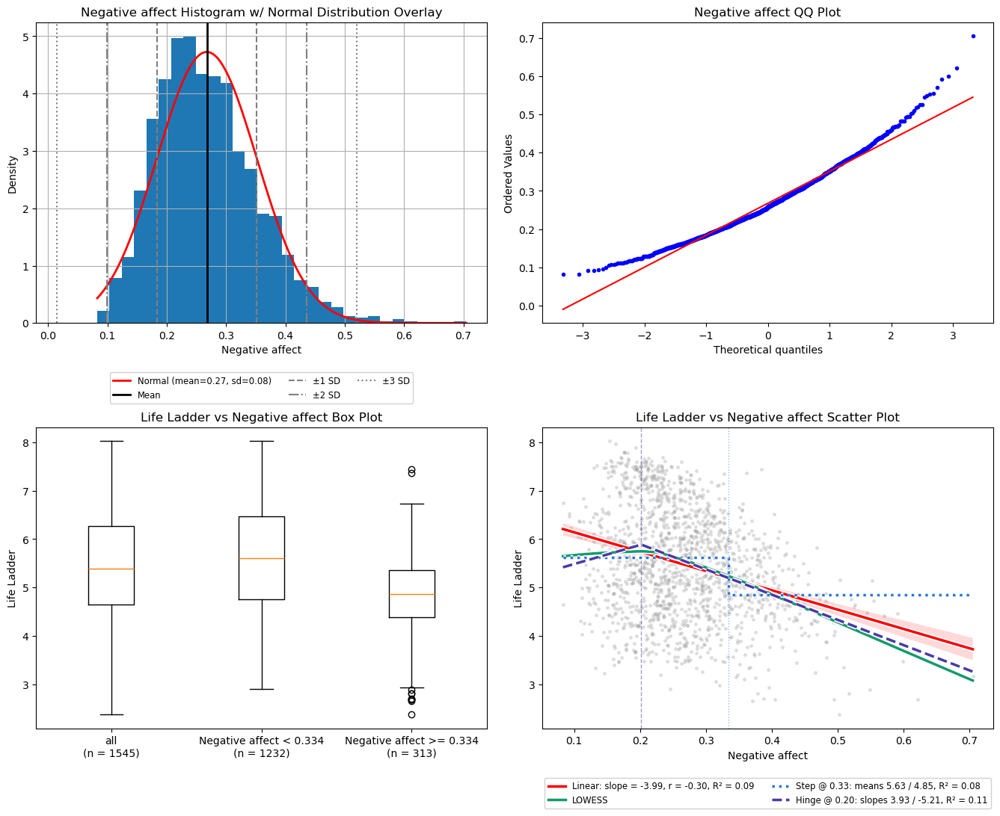

In [102]:
plotting.single_feature_plots(df=na_df, feature=na_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [103]:
na_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=na_X, y=na_y, folds=na_folds,
)
display(scoring.results_df({k: na_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.064,0.025,0.876,0.027,0.088,0.018,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Flat start (high-side hinge alone)

**What it targets**
In Q1B's scatter plot, LOWESS is nearly flat, even slightly rising, below about 0.2 and falls above it. Q1B's hinge fit at 0.20 found a slope of 3.93 below and -5.21 above. A LinearRegression on the raw value fits one falling slope across the whole range, so it predicts Life Ladder differences between the low rows that LOWESS says are mostly not there. Q1B's Special Treatment lists a hinge term `max(0, x - t)` with t near 0.20.

**What the intervention does**
Replaces the raw value with one new feature, the distance above a threshold `t`:

`h = max(0, x - t)`

| x | h (t = 0.20) |
|---|---|
| 0.60 | 0.40 |
| 0.40 | 0.20 |
| 0.20 | 0 |
| 0.10 | 0 |

No rows are dropped, and the high values keep their order and spacing. The model becomes `Life Ladder = a + b·h`:
- **Above t:** the prediction moves in a straight line with the distance above t.
- **At or below t:** h = 0, so every row gets the same prediction `a`. The bottom of the range is forced flat.

**What it gives up**
Every difference between values below t is erased. LOWESS still rises slightly below about 0.2, and Q1B's hinge fit gives the low side a slope of 3.93, so if that rise is real, B removes it.

**Variants**
- **B fixed (t = 0.20):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.08 to 0.70 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the flat start.

**Hypothesis**
If the bottom of the range is truly flat, forcing it flat removes noise the raw slope was fitting, and B beats A by more than the noise threshold. Since LOWESS is nearly flat below about 0.2, B is expected to tie with C. Q1B's 0.20 sits inside the guarded grid, so the nested search can move either side of it, and the picks are expected to stay near 0.20, where LOWESS peaks.

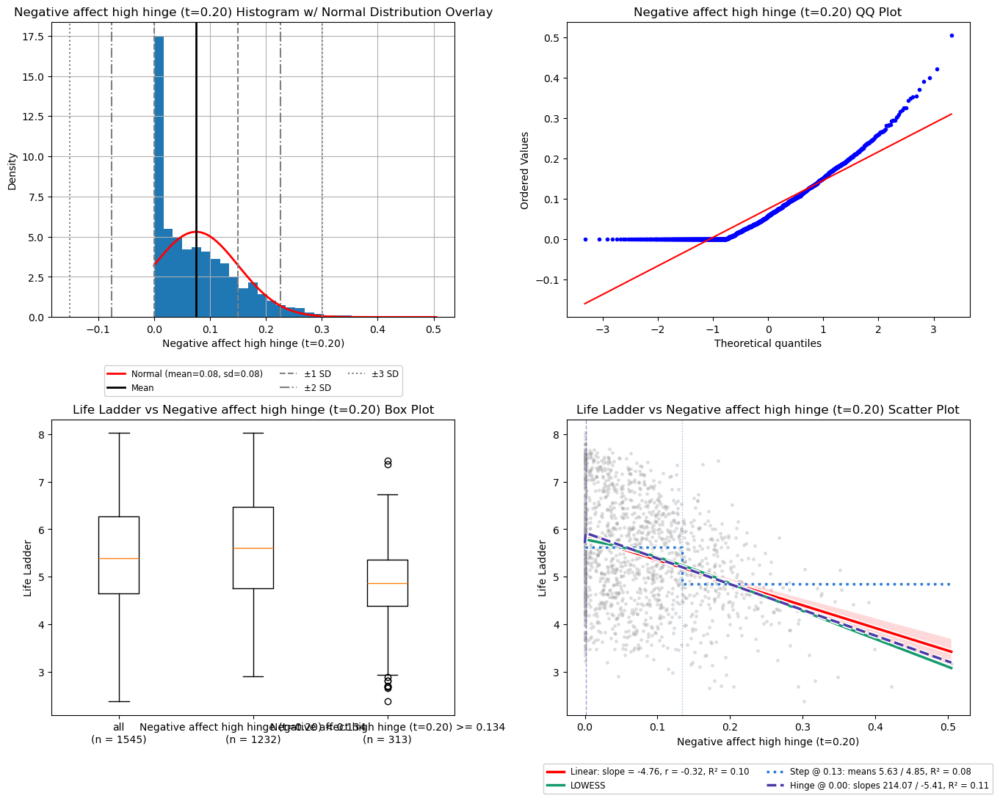

In [104]:
# fit on all na_df rows, for illustration only (the scores below refit inside each training fold)
na_b_df = pd.DataFrame(
	{"Negative affect high hinge (t=0.20)": np.ravel(features.HighHinge(t=0.20).fit_transform(na_X)), TARGET: na_y},
	index=na_df.index,
)
plotting.single_feature_plots(df=na_b_df, feature="Negative affect high hinge (t=0.20)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [105]:
na_b_pipeline = Pipeline([("features", features.HighHinge(t=0.20)), ("model", LinearRegression())])

na_results["B fixed (t=0.20)"] = pipelines.evaluate_pipeline(
	na_b_pipeline,
	X=na_X, y=na_y, folds=na_folds,
)
na_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(na_b_pipeline, param="features__t", grid=na_grid),
	X=na_X, y=na_y, folds=na_folds, return_estimator=True,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "B fixed (t=0.20)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B fixed (t=0.20),1.057,0.025,0.873,0.027,0.100,0.018,-0.007,0.002,-3.875,0.001,candidate,20
B nested,1.057,0.026,0.873,0.027,0.099,0.020,-0.007,0.004,-1.814,0.043,candidate,20
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20


In [106]:
# threshold picked by the inner search in each of the 20 folds
na_b_picked = features.picked_thresholds(na_results["B nested"]["estimator"], param="features__t")
display(pd.Series(na_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.21,4
0.22,3
0.23,11
0.24,1
0.26,1


### Intervention C | Linear spline (raw + hinge)

**What it targets**
Q1B's hinge fit at 0.20: slope 3.93 below and -5.21 above, with R² 0.11 against the linear fit's 0.09. Unlike B, C does not force the bottom flat, so it can keep a slope below t if the data support one.

**What the intervention does**
Keeps the raw value and adds the hinge from B as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 0.20) |
|---|---|
| 0.60 | [0.60, 0.40] |
| 0.40 | [0.40, 0.20] |
| 0.20 | [0.20, 0] |
| 0.10 | [0.10, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

Using the low-side hinge instead, `[x, max(0, t - x)]`, would give exactly the same predictions: the two hinges differ by `x - t`, which the raw column and the intercept already cover. Only the coefficients change, not the fit.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and C reduces to A with an extra parameter.

**Variants**
- **C fixed (t = 0.20):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 0.08 to 0.70 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
C is expected to beat A by more than the noise threshold, since Q1B's hinge R² (0.11) is above the linear R² (0.09). If the low side is as flat as LOWESS shows, C has no edge over B. The nested picks are expected to stay near 0.20, where LOWESS peaks.

#### Intervention C vs Target

In [107]:
na_c_pipeline = Pipeline([("features", features.HighHinge(t=0.20, keep_raw=True)), ("model", LinearRegression())])

na_results["C fixed (t=0.20)"] = pipelines.evaluate_pipeline(
	na_c_pipeline,
	X=na_X, y=na_y, folds=na_folds,
)
na_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(na_c_pipeline, param="features__t", grid=na_grid),
	X=na_X, y=na_y, folds=na_folds, return_estimator=True,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "C fixed (t=0.20)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.20),1.055,0.025,0.873,0.027,0.103,0.018,-0.009,0.003,-2.597,0.009,candidate,20
C nested,1.057,0.026,0.873,0.027,0.101,0.019,-0.008,0.004,-1.918,0.035,candidate,20
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20


In [108]:
# threshold picked by the inner search in each of the 20 folds
na_c_picked = features.picked_thresholds(na_results["C nested"]["estimator"], param="features__t")
display(pd.Series(na_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.18,1
0.20,7
0.21,9
0.22,1
0.23,2


### Intervention D | Indicator alone

**What it targets**
Q1B's step fit at 0.334 (the legend shows 0.33) split the rows into two groups with mean Life Ladder 5.63 below and 4.85 at or above, with 1232 rows below and 313 at or above in the box plot, and R² 0.08. Q1B's notes do not mention the step. D tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 0.334) |
|---|---|
| 0.50 | 0 |
| 0.334 | 0 |
| 0.30 | 1 |
| 0.15 | 1 |

The model becomes `Life Ladder = a + b·i`, which predicts one mean per side:
- **At or above t:** i = 0, so every row gets `a`, the mean Life Ladder of the training rows above t.
- **Below t:** i = 1, so every row gets `a + b`, the mean Life Ladder of the training rows below t.

No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at 0.15 gets the same prediction as a row at 0.30. The change at t is a hard jump, so two rows just either side of t get predictions that differ by the full b.

**Variants**
- **D fixed (t = 0.334):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D nested:** t is searched from 0.08 to 0.70 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the split.

**Hypothesis**
If most of the signal is just "below vs above t", D matches or beats A with a simpler shape. Q1B's step R² (0.08) is below the linear R² (0.09), so D is expected to lose to A.

#### Intervention D vs Target

In [109]:
na_d_pipeline = Pipeline([("features", features.Indicator(t=0.334)), ("model", LinearRegression())])

na_results["D fixed (t=0.334)"] = pipelines.evaluate_pipeline(
	na_d_pipeline,
	X=na_X, y=na_y, folds=na_folds,
)
na_results["D nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(na_d_pipeline, param="features__t", grid=na_grid),
	X=na_X, y=na_y, folds=na_folds, return_estimator=True,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "D fixed (t=0.334)", "D nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20
D fixed (t=0.334),1.072,0.029,0.883,0.029,0.075,0.017,0.008,0.006,1.175,0.873,worse,20
D nested,1.074,0.029,0.887,0.029,0.071,0.017,0.010,0.006,1.709,0.948,worse,20


In [110]:
# threshold picked by the inner search in each of the 20 folds
na_d_picked = features.picked_thresholds(na_results["D nested"]["estimator"], param="features__t")
display(pd.Series(na_d_picked).value_counts().sort_index().rename_axis("D nested picked t").to_frame("folds"))

,folds
D nested picked t,
0.33,9
0.34,11


### Intervention E | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range.

**What the intervention does**
Keeps the raw value and adds the indicator from D as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 0.334) |
|---|---|
| 0.50 | [0.50, 0] |
| 0.334 | [0.334, 0] |
| 0.30 | [0.30, 1] |
| 0.15 | [0.15, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot make it flatter than the high side.

**Variants**
- **E fixed (t = 0.334):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **E nested:** t is searched from 0.08 to 0.70 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
Tests a jump at t on top of the trend. If there is a level shift at t, E beats A by more than the noise threshold. Q1B's LOWESS shows a bend near 0.2 rather than a jump at 0.334, so E is expected to beat A by less than C, if at all.

#### Intervention E vs Target

In [111]:
na_e_pipeline = Pipeline([("features", features.Indicator(t=0.334, keep_raw=True)), ("model", LinearRegression())])

na_results["E fixed (t=0.334)"] = pipelines.evaluate_pipeline(
	na_e_pipeline,
	X=na_X, y=na_y, folds=na_folds,
)
na_results["E nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(na_e_pipeline, param="features__t", grid=na_grid),
	X=na_X, y=na_y, folds=na_folds, return_estimator=True,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "E fixed (t=0.334)", "E nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E nested,1.057,0.030,0.873,0.029,0.101,0.023,-0.008,0.005,-1.440,0.083,candidate,20
E fixed (t=0.334),1.062,0.026,0.875,0.028,0.093,0.017,-0.003,0.002,-1.122,0.138,candidate,20
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20


In [112]:
# threshold picked by the inner search in each of the 20 folds
na_e_picked = features.picked_thresholds(na_results["E nested"]["estimator"], param="features__t")
display(pd.Series(na_e_picked).value_counts().sort_index().rename_axis("E nested picked t").to_frame("folds"))

,folds
E nested picked t,
0.17,18
0.18,1
0.20,1


### Intervention F | Stretch the high tail (square)

**What it targets**
Candidate. The same bend as B and C, nearly flat at the low end and falling faster above, but with a smooth curve and no threshold to pick. Q1B advises against transforms that compress the high tail, since that is where Life Ladder changes. Squaring does the opposite and stretches it.

**What the intervention does**
Replaces the raw value with its square:

`z = x²`

| x | x² |
|---|---|
| 0.10 | 0.01 |
| 0.20 | 0.04 |
| 0.30 | 0.09 |
| 0.50 | 0.25 |
| 0.60 | 0.36 |
| 0.70 | 0.49 |

Squaring spreads out the values near the top more than those near the bottom: the gap from 0.10 to 0.20 becomes 0.03, while the same 0.10 gap from 0.60 to 0.70 becomes 0.13. The model becomes `Life Ladder = a + b·x²`, a straight line in x², which is a curve in x. With a negative b, it is nearly flat at the low end and falls more steeply toward the top.

**What it gives up**
It assumes the bend has the fixed shape of x², with no parameter to adjust it. The curve bends gradually across the whole range and keeps steepening toward the top, while LOWESS is nearly flat below about 0.2 and close to straight above it.

**Hypothesis**
Expected to beat A, since it bends the fit the same way as the hinge. Expected to trail C, since x² bends gradually across the whole range while LOWESS bends near 0.2.

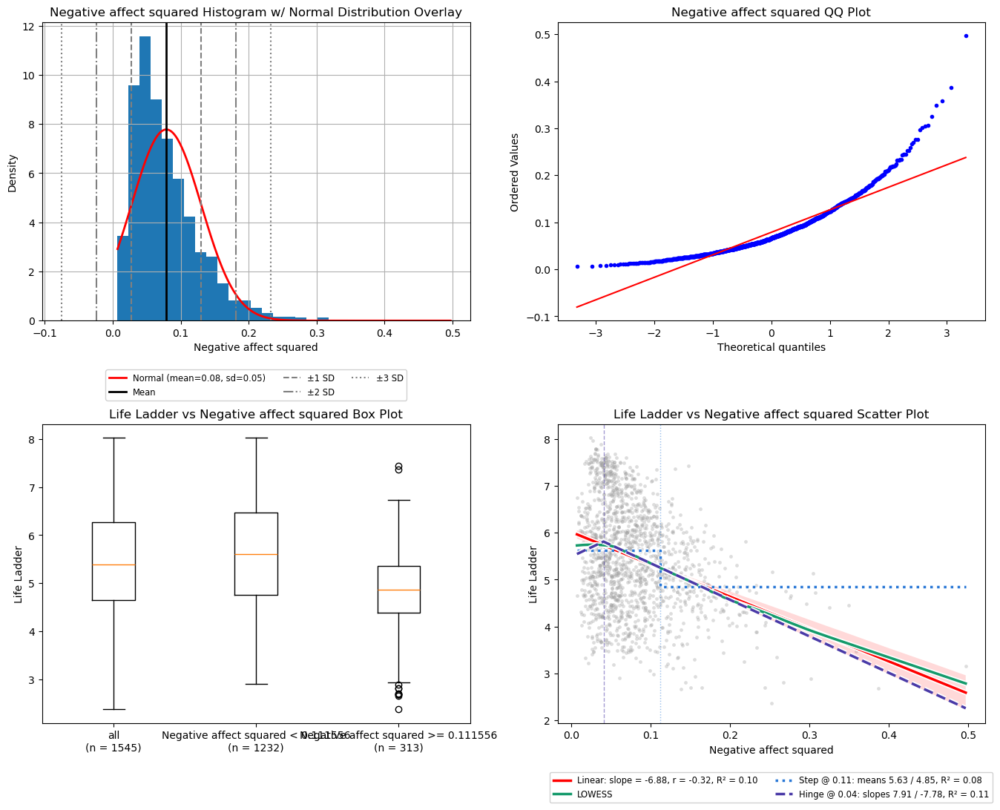

In [113]:
# fit on all na_df rows, for illustration only (the scores below refit inside each training fold)
na_f_df = pd.DataFrame(
	{"Negative affect squared": np.ravel(FunctionTransformer(np.square).fit_transform(na_X)), TARGET: na_y},
	index=na_df.index,
)
plotting.single_feature_plots(df=na_f_df, feature="Negative affect squared", target=TARGET, threshold="auto");

#### Intervention F vs Target

In [114]:
na_results["F"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.square)), ("model", LinearRegression())]),
	X=na_X, y=na_y, folds=na_folds,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "F"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
F,1.059,0.026,0.872,0.027,0.097,0.017,-0.005,0.002,-2.938,0.004,candidate,20
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20


### Intervention G | Skew fix control (Yeo-Johnson)

**What it targets**
Control. Negative affect is moderately right skewed (skew 0.696), with values bunched at the low end and a long right tail up to 0.705. Q1B's Special Treatment says to avoid log or similar skew fixing transforms, since they compress the high tail, which is where Life Ladder changes.

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a right skewed column it stretches the crowded low end and compresses the right tail. The model becomes `Life Ladder = a + b·YJ(x)`.

Box-Cox is not run separately: for positive x, Yeo-Johnson is Box-Cox applied to x + 1, which here gives nearly the same shape.

**What it gives up**
It stretches the low end, where LOWESS is nearly flat, giving the LR more room to fit differences there, and compresses the high tail, where LOWESS falls. In Social support and Health Life Expectancy Yeo-Johnson stretched the end where the bend was, so it was a candidate there. Here, as in Corruption and Generosity, it stretches the flat end, so it is a control.

**Hypothesis**
Tests Q1B's note to avoid skew fixing transforms. Expected to tie with or lose to A.

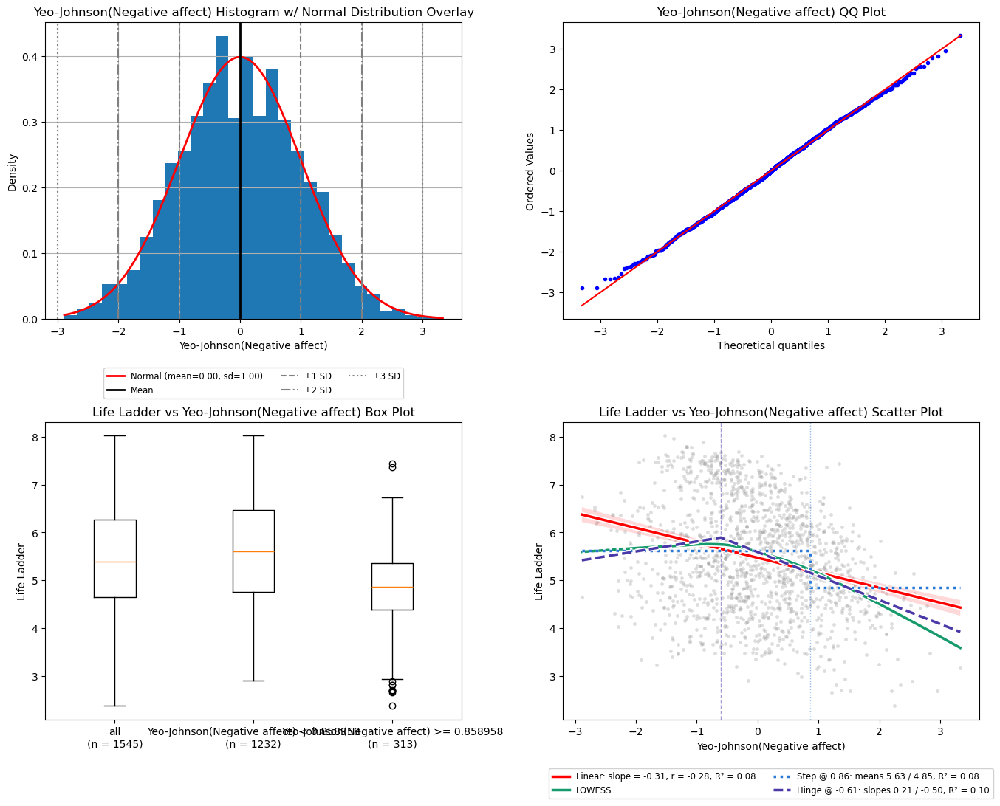

In [115]:
# fit on all na_df rows, for illustration only (the scores below refit inside each training fold)
na_g_df = pd.DataFrame(
	{"Yeo-Johnson(Negative affect)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(na_X)), TARGET: na_y},
	index=na_df.index,
)
plotting.single_feature_plots(df=na_g_df, feature="Yeo-Johnson(Negative affect)", target=TARGET, threshold="auto");

#### Intervention G vs Target

In [116]:
na_results["G"] = pipelines.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=na_X, y=na_y, folds=na_folds, return_estimator=True,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "G"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20
G,1.072,0.024,0.882,0.027,0.075,0.018,0.008,0.001,5.839,1.0,worse,20


In [117]:
# Yeo-Johnson power fitted on each of the 20 training folds
na_g_lambdas = pd.Series([estimator.named_steps["features"].lambdas_[0] for estimator in na_results["G"]["estimator"]])
display(na_g_lambdas.describe()[["min", "50%", "max"]].rename({"50%": "median"}).round(2).rename_axis("G fitted λ").to_frame("value"))

,value
G fitted λ,
min,-2.85
median,-2.58
max,-2.22


### Intervention H | Log control

**What it targets**
Control. Log is the transform Q1B's Special Treatment names: it stretches the low end and squeezes the high tail, where Life Ladder changes. G fits the amount of squeeze to the data; H uses the fixed log shape.

**What the intervention does**
Replaces the raw value with its natural log:

`z = log(x)`

| x | log(x) |
|---|---|
| 0.10 | -2.303 |
| 0.20 | -1.609 |
| 0.30 | -1.204 |
| 0.50 | -0.693 |
| 0.60 | -0.511 |
| 0.70 | -0.357 |

The log spreads out the values near the bottom and squeezes those near the top: the gap from 0.10 to 0.20 becomes about 0.69, while the same 0.10 gap from 0.60 to 0.70 becomes about 0.15. The model becomes `Life Ladder = a + b·log(x)`, a straight line in log(x), which is a curve in x that is steep at the low end and flat at the top. The column min is 0.083, so x is always positive and the log is always defined.

**What it gives up**
It bends the fit the wrong way: toward a curve that is steep at the low end, where LOWESS is nearly flat, and flat at the top, where LOWESS falls.

**Hypothesis**
Tests Q1B's note to avoid log. Expected to lose to A.

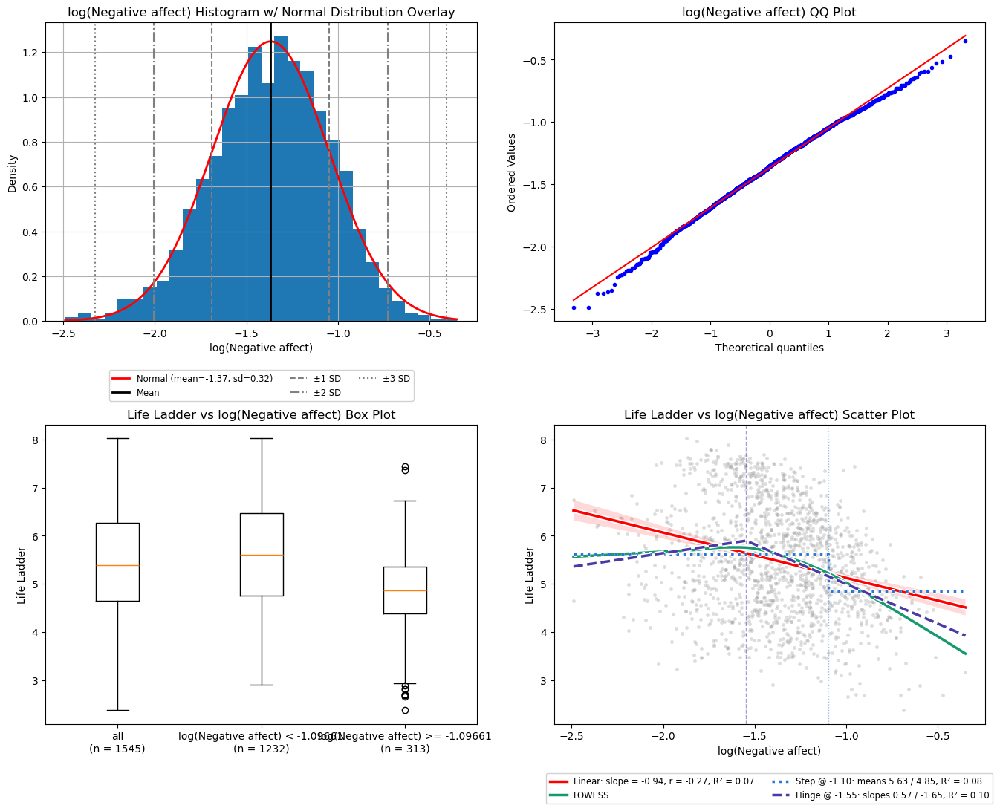

In [118]:
# fit on all na_df rows, for illustration only (the scores below refit inside each training fold)
na_h_df = pd.DataFrame(
	{"log(Negative affect)": np.ravel(FunctionTransformer(np.log).fit_transform(na_X)), TARGET: na_y},
	index=na_df.index,
)
plotting.single_feature_plots(df=na_h_df, feature="log(Negative affect)", target=TARGET, threshold="auto");

#### Intervention H vs Target

In [119]:
na_results["H"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.log)), ("model", LinearRegression())]),
	X=na_X, y=na_y, folds=na_folds,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "H"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20
H,1.075,0.025,0.885,0.027,0.069,0.017,0.011,0.002,6.273,1.0,worse,20


### Intervention I | Keep-outliers control (IQR fence clip)

**What it targets**
Control. Q1B flagged 20 high outliers above the upper IQR fence (0.489) and none below, and says to keep them, since they sit in the part of the range that carries the signal.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. Every value below the lower fence becomes the lower fence value, every value above the upper fence becomes the upper fence value, and every value between the fences is unchanged. Q1B's lower fence (0.036) is below the column min (0.083), so only the top is clipped. The model becomes `Life Ladder = a + b·clip(x)`.

| x | clip(x) (Q1B's fences 0.036 / 0.489) |
|---|---|
| 0.705 | 0.489 |
| 0.55 | 0.489 |
| 0.30 | 0.30 |
| 0.083 | 0.083 |

**What it gives up**
The detail in the high tail: the 20 rows above the fence all get the same feature value and so the same prediction, in the part of the range where LOWESS falls.

**Hypothesis**
Tests Q1B's note to keep the high outliers. Expected to tie with or lose to A. With only 20 rows above the fence, any difference is small.

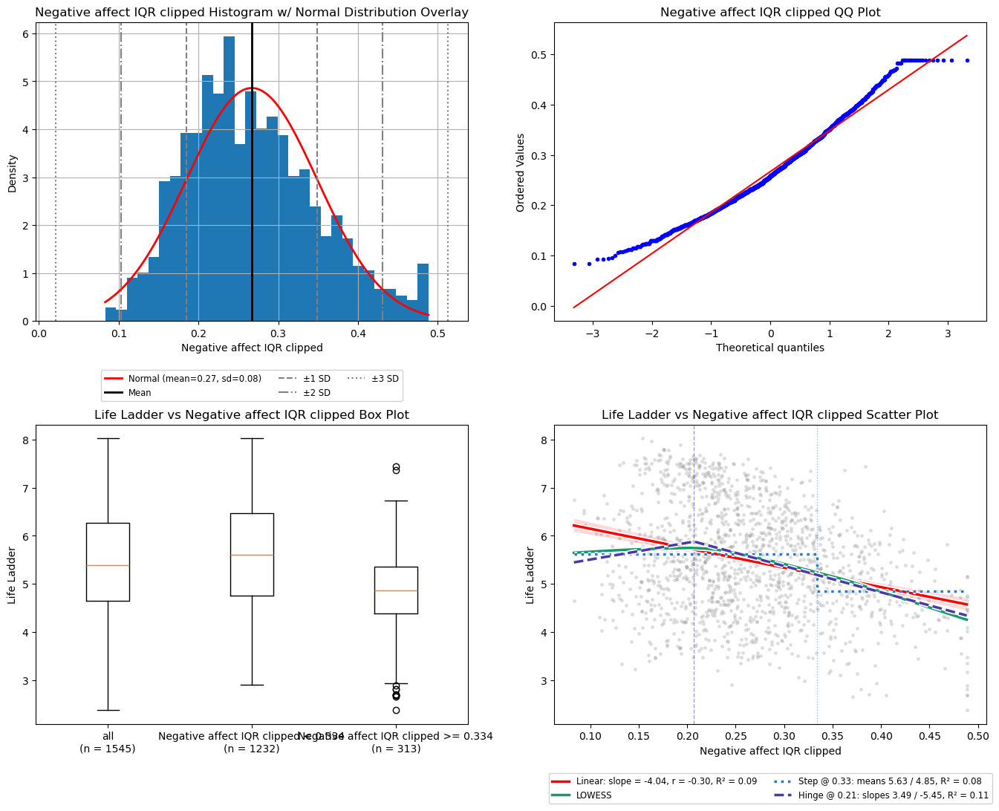

In [120]:
# fit on all na_df rows, for illustration only (the scores below refit inside each training fold)
na_i_df = pd.DataFrame(
	{"Negative affect IQR clipped": np.ravel(features.IQRClip().fit_transform(na_X)), TARGET: na_y},
	index=na_df.index,
)
plotting.single_feature_plots(df=na_i_df, feature="Negative affect IQR clipped", target=TARGET, threshold="auto");

#### Intervention I vs Target

In [121]:
na_results["I"] = pipelines.evaluate_pipeline(
	Pipeline([("features", features.IQRClip()), ("model", LinearRegression())]),
	X=na_X, y=na_y, folds=na_folds,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "I"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20
I,1.066,0.025,0.877,0.027,0.085,0.018,0.002,0.001,1.774,0.954,worse,20


### Intervention J | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Negative affect can explain. B to I each force one shape (flat start, bend, jump, square, power curve, log curve, clip). J tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If J scores about the same as the best of B to I:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If J is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention J vs Target

In [122]:
na_j_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

na_results["J nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(na_j_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=na_X, y=na_y, folds=na_folds, return_estimator=True,
)
display(scoring.results_df({k: na_results[k] for k in ["A", "J nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
J nested,1.059,0.025,0.875,0.026,0.096,0.018,-0.005,0.004,-1.394,0.09,candidate,20
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,baseline,20


In [123]:
# number of knots picked by the inner search in each of the 20 folds
na_j_picked = features.picked_thresholds(na_results["J nested"]["estimator"], param="features__n_knots")
display(pd.Series(na_j_picked).astype(int).value_counts().sort_index().rename_axis("J nested picked n_knots").to_frame("folds"))

,folds
J nested picked n_knots,
3,9
4,7
5,1
6,2
8,1


### Comparison

In [124]:
display(scoring.results_df(na_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
C fixed (t=0.20),1.055,0.025,0.873,0.027,0.103,0.018,-0.009,0.003,-2.597,0.009,0.097,candidate,20
E nested,1.057,0.030,0.873,0.029,0.101,0.023,-0.008,0.005,-1.440,0.083,0.665,candidate,20
C nested,1.057,0.026,0.873,0.027,0.101,0.019,-0.008,0.004,-1.918,0.035,0.352,candidate,20
B fixed (t=0.20),1.057,0.025,0.873,0.027,0.100,0.018,-0.007,0.002,-3.875,0.001,0.007,significant,20
B nested,1.057,0.026,0.873,0.027,0.099,0.020,-0.007,0.004,-1.814,0.043,0.385,candidate,20
F,1.059,0.026,0.872,0.027,0.097,0.017,-0.005,0.002,-2.938,0.004,0.051,candidate,20
J nested,1.059,0.025,0.875,0.026,0.096,0.018,-0.005,0.004,-1.394,0.090,0.665,candidate,20
E fixed (t=0.334),1.062,0.026,0.875,0.028,0.093,0.017,-0.003,0.002,-1.122,0.138,0.828,candidate,20
A,1.064,0.025,0.876,0.027,0.088,0.018,0.000,NaN,NaN,NaN,NaN,baseline,20


## Negative Affect Results

- **A is weak:** rmse 1.064 and r2 0.088, in line with Q1B's linear R² of 0.09 and the second lowest A of the five attributes so far (Generosity 0.033, Corruption 0.178). The best intervention only lifts r2 to 0.103 (C fixed).
- **Only B fixed is significant** (Δ -0.007, Δ / SE -3.875, `p (Holm)` 0.007). Seven more interventions are candidates but not significant after the Holm adjustment, the closest being F (`p (Holm)` 0.051) and C fixed (0.097).
- **The bend at about 0.2 carries the signal, and the low side is flat enough to drop.** B and C tie: rmse 1.057 for B fixed, B nested and C nested, and 1.055 for C fixed. B fixed has the most consistent gain of all (Δ / SE -3.875 vs C fixed's -2.597). C nested picked t between 0.18 and 0.23 (0.20 or 0.21 in 16 of 20 folds), while B nested picked between 0.21 and 0.26 (0.23 in 11).
- **Nothing beats the single hinge.** J, the flexible spline ceiling, scores rmse 1.059 against C fixed's 1.055 and picked 3 or 4 knots in 16 of 20 folds. F (square) also scores 1.059 and trails C, as expected. E fixed at 0.334 barely beats A (Δ -0.003). E nested (rmse 1.057) moved the jump from 0.334 down to 0.17 in 18 of 20 folds, next to the bottom of the guarded grid (0.16), and has the highest rmse sd in the table (0.030).
- **What loses to or ties A:** D in both variants (Δ +0.008 fixed, +0.010 nested), so the step at 0.334 carries nothing on its own. The controls behave as Q1B expected: G (Yeo-Johnson, fitted λ between -2.85 and -2.22) loses (+0.008), H (log) loses (+0.011), and I (IQR clip) loses by a small margin (+0.002).
- **Hypotheses that did not hold:** B nested's picks were expected to stay near 0.20 but all landed above it (0.21 to 0.26). E was expected to trail C, and E nested ties C nested instead (Δ -0.008 for both), though only by moving its jump from 0.334 to 0.17. The other hypotheses held, including all three controls.

#### Carry forward

- **B (high-side hinge `max(0, x - t)`)** as the main candidate for the multi-feature model, with t fixed at 0.20 (B nested picked 0.21 to 0.26 and is only a candidate). It is the only significant intervention, a single column, and ties C (rmse 1.057 vs 1.055).
- **C (raw + hinge `[x, max(0, x - t)]`, t = 0.20)** as the equivalent alternative, in case a slope below the bend matters once the other features are in the model.
- **F (square)** as the no-threshold alternative (`p (Holm)` 0.051).
- **Negative affect as a whole stays a candidate to drop.** Even its best shape only lifts r2 from 0.088 to 0.103, so the multi-feature stage should keep it only if B clears the noise threshold there.
- **Drop:** D, E, G, H, I and J. J and E nested do not beat the hinge, and E nested's picks sit at the edge of the guarded grid. Keep the 20 high outliers unclipped.

## Freedom to Make Life Choices

Rows missing Freedom to make life choices are dropped. Rows missing other attributes are kept, since only Freedom to make life choices is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported for the same shape (the hinge or the step).
- **nested** variants search t with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**The grid differs from the earlier sections.** Freedom to make life choices runs from 0.26 to 0.985. The 0.05 to 0.95 grid (step 0.02) used for Corruption and Social support covers most of it, but that grid holds only odd hundredths, so Q1B's hinge at 0.80 is not on it. Here t is searched from 0.26 to 0.98 (step 0.01), and the 5% guard trims it to the range printed below. The setup cell also defines the `-log(1 - x)` transform used by Intervention G.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [125]:
free_col = COLUMNS['FTMLC']['col']
free_df = train_df[[free_col, TARGET]].dropna(subset=[free_col])
free_X = free_df[[free_col]]
free_y = free_df[TARGET]

free_grid = np.round(np.arange(0.26, 0.981, 0.01), 2)


def free_neg_log_one_minus(x):
	"""-log(1 - x), used by Intervention G."""
	return -np.log1p(-x)


free_folds = pipelines.make_folds(free_X, seeds=SEEDS)
free_results = {}

free_x = free_X[free_col].to_numpy()
free_guarded = [t for t in free_grid if min(np.mean(free_x < t), np.mean(free_x >= t)) >= features.MIN_GROUP_FRAC]
print(f"rows used: {len(free_df)} of {len(train_df)}")
print(f"folds: {len(free_folds)}")
print(f"threshold grid after the 5% guard (all rows): {free_guarded[0]} to {free_guarded[-1]}")

rows used: 1537 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 0.48 to 0.93


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Freedom to make life choices value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow both the shallow rise below about 0.8 and the steep rise above it that LOWESS shows in Q1B.

**Hypothesis**
A sets the bar. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model. Q1B's linear fit had R² 0.28 (slope 4.16), so A's r2 is expected to be near 0.28.

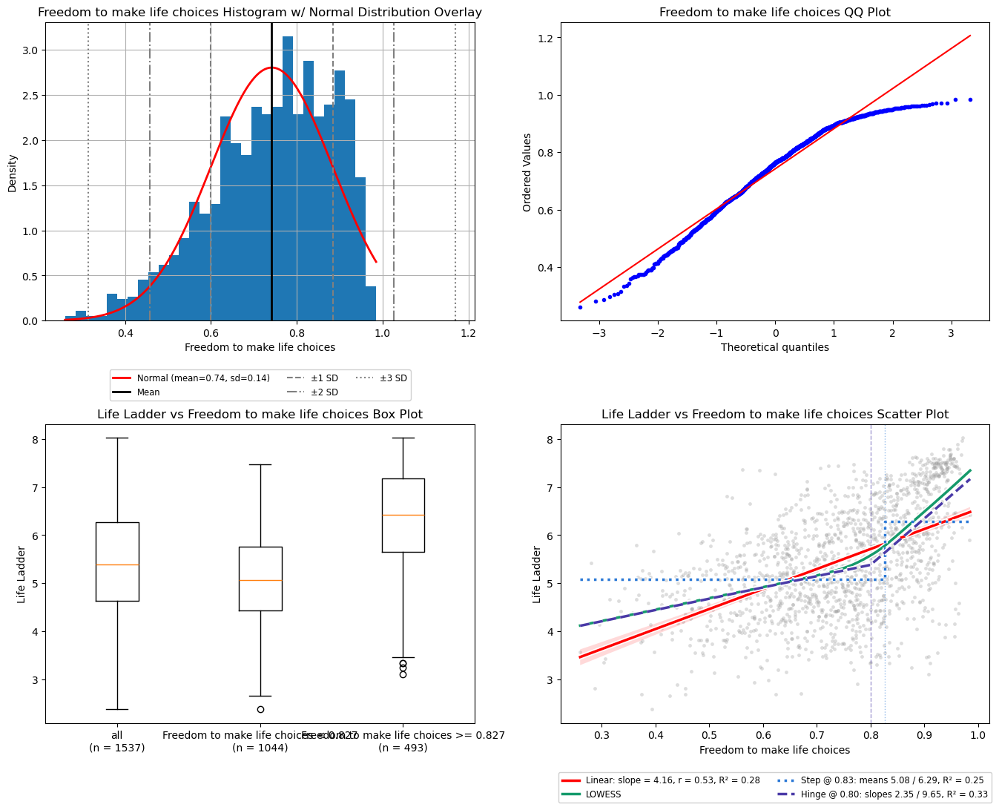

In [126]:
plotting.single_feature_plots(df=free_df, feature=free_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [127]:
free_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(scoring.results_df({k: free_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.949,0.027,0.778,0.023,0.276,0.045,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | High-side hinge alone

**What it targets**
In Q1B's scatter plot, Life Ladder vs Freedom to make life choices is not a straight line. LOWESS is shallow below about 0.8 and steep above, and Q1B's hinge fit at 0.80 found a slope of 2.35 below and 9.65 above. A LinearRegression on the raw value can only fit one slope for the whole range, so it has to compromise: in Q1B's plot the line sits below LOWESS in the low tail and at the top, and above it in the middle of the range.

**What the intervention does**
Replaces the raw value with one new feature, the distance above a threshold `t`:

`h = max(0, x - t)`

| x | h (t = 0.80) |
|---|---|
| 0.95 | 0.15 |
| 0.90 | 0.10 |
| 0.80 | 0 |
| 0.50 | 0 |

No rows are dropped, and the high values keep their order and spacing. The model becomes `Life Ladder = a + b·h`:
- **Above t:** the prediction moves in a straight line with the distance above t.
- **At or below t:** h = 0, so every row gets the same prediction `a`. The bottom of the range is forced flat.

**What it gives up**
Every difference between values below t is erased. That is only safe if those differences carry no information about Life Ladder. Q1B's hinge fit found a low-side slope of 2.35, which is shallower than the top but not flat, and in Q1B's plot LOWESS keeps a steady slope below about 0.7, so B may remove real signal and score worse than A.

**Variants**
- **B fixed (t = 0.80):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.26 to 0.98 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the bend.

**Hypothesis**
If Life Ladder only responds to Freedom to make life choices above t, forcing the bottom flat removes noise the raw slope was fitting, and B beats A by more than the noise threshold. Since Q1B's low-side slope is 2.35, B fixed is expected to tie with or lose to A. A lower t leaves fewer rows on the flat side, so the nested picks may move below 0.80, as they did in Social support.

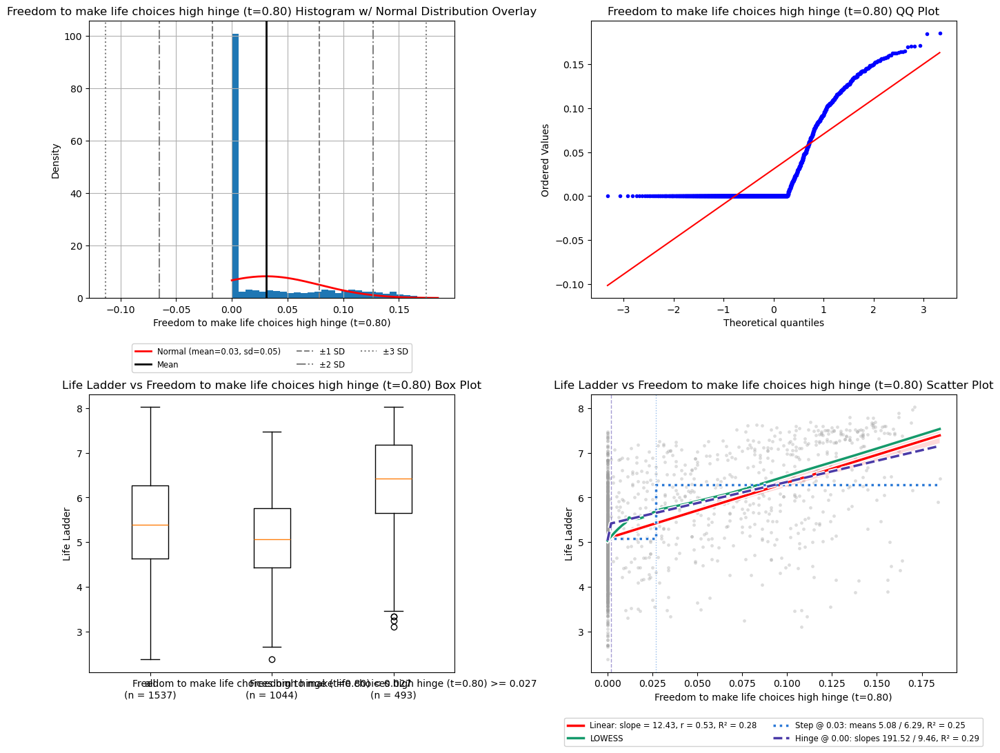

In [128]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_b_df = pd.DataFrame(
	{"Freedom to make life choices high hinge (t=0.80)": np.ravel(features.HighHinge(t=0.80).fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
plotting.single_feature_plots(df=free_b_df, feature="Freedom to make life choices high hinge (t=0.80)", target=TARGET, threshold="auto");

#### Intervention B vs Target

In [129]:
free_b_pipeline = Pipeline([("features", features.HighHinge(t=0.80)), ("model", LinearRegression())])

free_results["B fixed (t=0.80)"] = pipelines.evaluate_pipeline(
	free_b_pipeline,
	X=free_X, y=free_y, folds=free_folds,
)
free_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(free_b_pipeline, param="features__t", grid=free_grid),
	X=free_X, y=free_y, folds=free_folds, return_estimator=True,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "B fixed (t=0.80)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B nested,0.940,0.026,0.760,0.020,0.289,0.051,-0.009,0.010,-0.848,0.203,within noise,20
B fixed (t=0.80),0.946,0.028,0.761,0.024,0.279,0.051,-0.003,0.019,-0.137,0.446,within noise,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


In [130]:
# threshold picked by the inner search in each of the 20 folds
free_b_picked = features.picked_thresholds(free_results["B nested"]["estimator"], param="features__t")
display(pd.Series(free_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.59,1
0.60,1
0.68,1
0.71,4
0.72,1
0.73,7
0.74,1
0.75,2
0.76,2


### Intervention C | Linear spline (raw + hinge)

**What it targets**
Q1B's hinge fit at 0.80: slope 2.35 below and 9.65 above, with R² 0.33 against the linear fit's 0.28. Unlike B, C does not force the bottom flat, so it can keep the slope below t.

**What the intervention does**
Keeps the raw value and adds the hinge from B as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 0.80) |
|---|---|
| 0.95 | [0.95, 0.15] |
| 0.90 | [0.90, 0.10] |
| 0.80 | [0.80, 0] |
| 0.50 | [0.50, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

Using the low-side hinge instead, `[x, max(0, t - x)]`, would give exactly the same predictions: the two hinges differ by `x - t`, which the raw column and the intercept already cover. Only the coefficients change, not the fit.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and C reduces to A with an extra parameter.

**Variants**
- **C fixed (t = 0.80):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **C nested:** t is searched from 0.26 to 0.98 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
C is expected to beat A by more than the noise threshold, since Q1B's hinge R² (0.33) is above the linear R² (0.28), and to beat B, because it keeps the slope below t that B erases. In Q1B's plot LOWESS turns upward gradually between about 0.7 and 0.85 rather than at one sharp corner, so the nested picks may spread around 0.80.

#### Intervention C vs Target

In [131]:
free_c_pipeline = Pipeline([("features", features.HighHinge(t=0.80, keep_raw=True)), ("model", LinearRegression())])

free_results["C fixed (t=0.80)"] = pipelines.evaluate_pipeline(
	free_c_pipeline,
	X=free_X, y=free_y, folds=free_folds,
)
free_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(free_c_pipeline, param="features__t", grid=free_grid),
	X=free_X, y=free_y, folds=free_folds, return_estimator=True,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "C fixed (t=0.80)", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C fixed (t=0.80),0.921,0.026,0.747,0.020,0.318,0.048,-0.028,0.011,-2.670,0.008,candidate,20
C nested,0.923,0.026,0.748,0.021,0.315,0.049,-0.026,0.010,-2.531,0.010,candidate,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


In [132]:
# threshold picked by the inner search in each of the 20 folds
free_c_picked = features.picked_thresholds(free_results["C nested"]["estimator"], param="features__t")
display(pd.Series(free_c_picked).value_counts().sort_index().rename_axis("C nested picked t").to_frame("folds"))

,folds
C nested picked t,
0.77,2
0.78,5
0.79,1
0.80,4
0.81,4
0.82,4


### Intervention D | Indicator alone

**What it targets**
Q1B's step fit at 0.827 (the legend shows 0.83) split the rows into two groups with mean Life Ladder 5.08 below and 6.29 at or above, with 1044 rows below and 493 at or above in the box plot, and R² 0.25. D tests whether that split alone carries the signal.

**What the intervention does**
Replaces the raw value with one binary feature:

`i = 1 if x < t else 0`

| x | i (t = 0.827) |
|---|---|
| 0.95 | 0 |
| 0.827 | 0 |
| 0.80 | 1 |
| 0.50 | 1 |

The model becomes `Life Ladder = a + b·i`, which predicts one mean per side:
- **At or above t:** i = 0, so every row gets `a`, the mean Life Ladder of the training rows above t.
- **Below t:** i = 1, so every row gets `a + b`, the mean Life Ladder of the training rows below t.

No plot cell, since the feature is binary.

**What it gives up**
All variation within each side is erased: a row at 0.50 gets the same prediction as a row at 0.80. The change at t is a hard jump, so two rows just either side of t get predictions that differ by the full b.

**Variants**
- **D fixed (t = 0.827):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D nested:** t is searched from 0.26 to 0.98 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the split.

**Hypothesis**
If most of the signal is just "below vs above t", D matches or beats A with a simpler shape. Q1B's step R² (0.25) is below the linear R² (0.28), so D is expected to lose to A.

#### Intervention D vs Target

In [133]:
free_d_pipeline = Pipeline([("features", features.Indicator(t=0.827)), ("model", LinearRegression())])

free_results["D fixed (t=0.827)"] = pipelines.evaluate_pipeline(
	free_d_pipeline,
	X=free_X, y=free_y, folds=free_folds,
)
free_results["D nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(free_d_pipeline, param="features__t", grid=free_grid),
	X=free_X, y=free_y, folds=free_folds, return_estimator=True,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "D fixed (t=0.827)", "D nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20
D fixed (t=0.827),0.968,0.021,0.786,0.020,0.247,0.037,0.019,0.015,1.221,0.881,worse,20
D nested,0.975,0.018,0.791,0.019,0.236,0.040,0.025,0.016,1.631,0.940,worse,20


In [134]:
# threshold picked by the inner search in each of the 20 folds
free_d_picked = features.picked_thresholds(free_results["D nested"]["estimator"], param="features__t")
display(pd.Series(free_d_picked).value_counts().sort_index().rename_axis("D nested picked t").to_frame("folds"))

,folds
D nested picked t,
0.82,3
0.83,15
0.84,2


### Intervention E | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range.

**What the intervention does**
Keeps the raw value and adds the indicator from D as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 0.827) |
|---|---|
| 0.95 | [0.95, 0] |
| 0.827 | [0.827, 0] |
| 0.80 | [0.80, 1] |
| 0.50 | [0.50, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot make the top steeper than the low side.

**Variants**
- **E fixed (t = 0.827):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **E nested:** t is searched from 0.26 to 0.98 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
Tests a jump at t on top of the trend. If there is a level shift at t, E beats A by more than the noise threshold. Q1B's LOWESS shows a bend rather than a jump, so E is expected to beat A by less than C, if at all. The nested picks may drift away from 0.827, as they did in Social support and Negative affect.

#### Intervention E vs Target

In [135]:
free_e_pipeline = Pipeline([("features", features.Indicator(t=0.827, keep_raw=True)), ("model", LinearRegression())])

free_results["E fixed (t=0.827)"] = pipelines.evaluate_pipeline(
	free_e_pipeline,
	X=free_X, y=free_y, folds=free_folds,
)
free_results["E nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(free_e_pipeline, param="features__t", grid=free_grid),
	X=free_X, y=free_y, folds=free_folds, return_estimator=True,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "E fixed (t=0.827)", "E nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E fixed (t=0.827),0.931,0.023,0.760,0.019,0.303,0.043,-0.018,0.006,-2.866,0.005,candidate,20
E nested,0.934,0.027,0.762,0.021,0.299,0.048,-0.015,0.008,-2.000,0.030,candidate,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


In [136]:
# threshold picked by the inner search in each of the 20 folds
free_e_picked = features.picked_thresholds(free_results["E nested"]["estimator"], param="features__t")
display(pd.Series(free_e_picked).value_counts().sort_index().rename_axis("E nested picked t").to_frame("folds"))

,folds
E nested picked t,
0.86,11
0.87,1
0.88,4
0.91,3
0.92,1


### Intervention F | Stretch the top (logit)

**What it targets**
Candidate. The same bend as B and C, shallow below about 0.8 and steep above, but with a smooth curve and no threshold to pick. Q1B's Special Treatment lists a transform that stretches the top end, naming logit.

**What the intervention does**
Replaces the raw value with its logit:

`z = logit(x) = log(x / (1 - x))`

| x | logit(x) |
|---|---|
| 0.30 | -0.847 |
| 0.50 | 0.000 |
| 0.70 | 0.847 |
| 0.80 | 1.386 |
| 0.90 | 2.197 |
| 0.95 | 2.944 |
| 0.985 | 4.185 |

The logit spreads out the values near the top: the gap from 0.30 to 0.50 becomes 0.847, while the same 0.20 gap from 0.70 to 0.90 becomes 1.350. The model becomes `Life Ladder = a + b·logit(x)`, a straight line in logit(x), which is a curve in x that is shallow across the low and middle range and steep near the top. The column max is 0.985, so `1 - x` is never 0 in these rows and the logit is always defined.

**What it gives up**
It assumes the bend has the specific logit shape, with no parameter to adjust it. The logit is `-log(1 - x) + log(x)`: on top of stretching the top, it also stretches the low tail, where LOWESS keeps a steady slope in Q1B's plot. The stretch is largest for the few rows nearest the max of 0.985, so they get the most pull on the slope.

**Hypothesis**
Expected to beat A, since it bends the fit the same way as the hinge. Expected to trail C, since it also stretches the low tail and keeps steepening toward the top, while in Q1B's plot LOWESS looks close to straight above about 0.85.

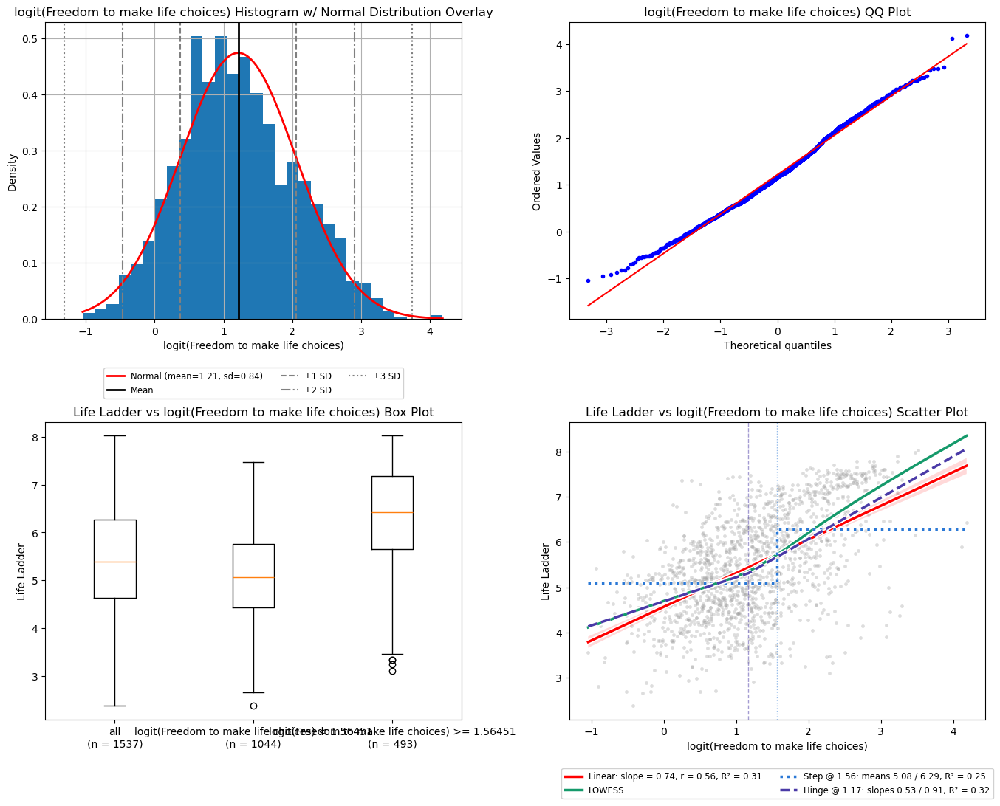

In [137]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_f_df = pd.DataFrame(
	{"logit(Freedom to make life choices)": np.ravel(FunctionTransformer(logit).fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
plotting.single_feature_plots(df=free_f_df, feature="logit(Freedom to make life choices)", target=TARGET, threshold="auto");

#### Intervention F vs Target

In [138]:
free_results["F"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(logit)), ("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "F"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
F,0.927,0.027,0.755,0.021,0.309,0.048,-0.022,0.006,-3.526,0.001,candidate,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


### Intervention G | Stretch the top only (-log(1 - x))

**What it targets**
Candidate. The same bend as F. Q1B's Special Treatment names `-log(1 - x)` next to logit. Unlike the logit, it stretches only the top: since `logit(x) = -log(1 - x) + log(x)`, G is F without the log stretch of the low end.

**What the intervention does**
Replaces the raw value with `-log(1 - x)`:

`z = -log(1 - x)`

| x | -log(1 - x) |
|---|---|
| 0.30 | 0.357 |
| 0.50 | 0.693 |
| 0.70 | 1.204 |
| 0.80 | 1.609 |
| 0.90 | 2.303 |
| 0.95 | 2.996 |
| 0.985 | 4.200 |

It spreads the low end only a little and stretches the top much more: the gap from 0.30 to 0.50 becomes 0.336, while the same 0.20 gap from 0.70 to 0.90 becomes 1.099. The model becomes `Life Ladder = a + b·(-log(1 - x))`, a curve in x that gets steeper and steeper toward the top. The column max is 0.985, so `1 - x` is never 0 in these rows and the transform is always defined. It is computed as `-np.log1p(-x)` by `free_neg_log_one_minus`, defined in the setup cell.

**What it gives up**
It assumes the bend has this fixed shape, with no parameter to adjust it. Its slope keeps rising all the way to the max, while in Q1B's plot LOWESS looks close to straight above about 0.85, so it may overshoot at the top, where the few rows nearest the max get the most pull on the slope.

**Hypothesis**
Expected to beat A. Compared with F, it shows whether the logit's extra stretch of the low tail helps or hurts: since LOWESS keeps a steady slope in the low tail, G is expected to match or beat F.

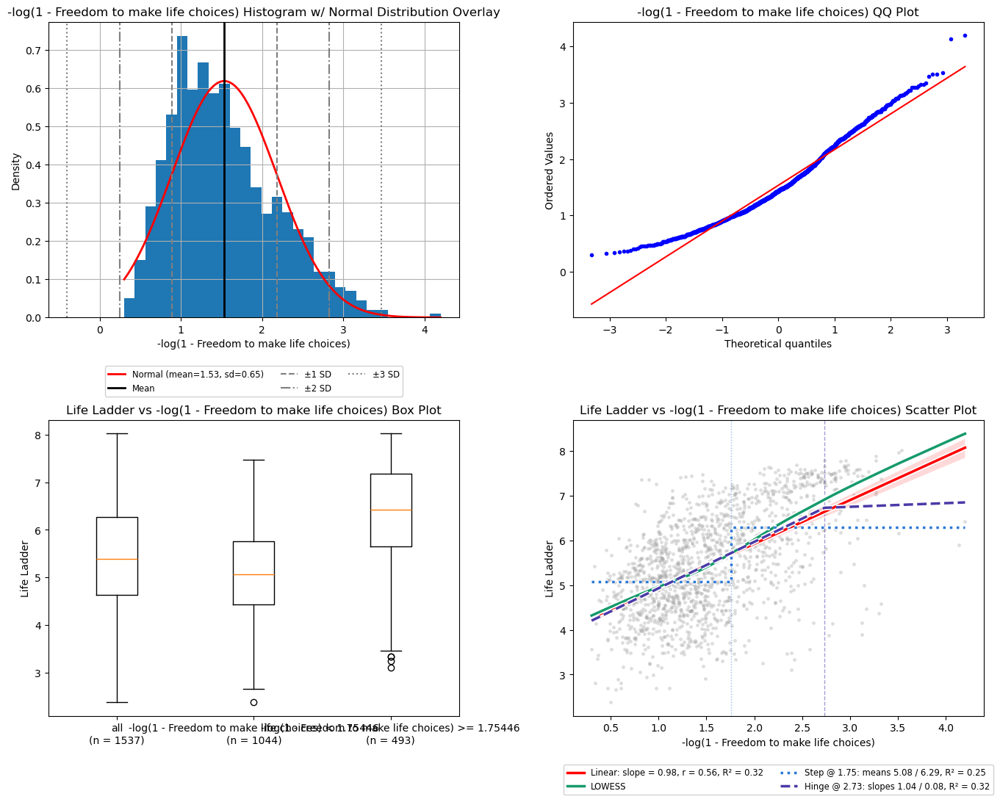

In [139]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_g_df = pd.DataFrame(
	{"-log(1 - Freedom to make life choices)": np.ravel(FunctionTransformer(free_neg_log_one_minus).fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
plotting.single_feature_plots(df=free_g_df, feature="-log(1 - Freedom to make life choices)", target=TARGET, threshold="auto");

#### Intervention G vs Target

In [140]:
free_results["G"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(free_neg_log_one_minus)), ("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "G"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
G,0.924,0.027,0.748,0.020,0.313,0.049,-0.025,0.009,-2.876,0.005,candidate,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


### Intervention H | Stretch the top (square)

**What it targets**
Candidate. The same bend as B and C, shallow at the low end and steeper above, but with a smooth curve and no threshold to pick. Squaring stretches the top end, as Q1B's Special Treatment asks, but more gently than F and G.

**What the intervention does**
Replaces the raw value with its square:

`z = x²`

| x | x² |
|---|---|
| 0.30 | 0.090 |
| 0.50 | 0.250 |
| 0.70 | 0.490 |
| 0.80 | 0.640 |
| 0.90 | 0.810 |
| 0.95 | 0.9025 |
| 0.985 | 0.970 |

Squaring spreads out the values near the top more than those near the bottom: the gap from 0.30 to 0.50 becomes 0.160, while the same 0.20 gap from 0.70 to 0.90 becomes 0.320. So the top is stretched, but only mildly across 0.26 to 0.985. The model becomes `Life Ladder = a + b·x²`, a straight line in x², which is a curve in x that gets steeper toward the top.

**What it gives up**
It assumes the bend has the fixed shape of x², with no parameter to adjust it. Its bend is mild compared with the hinge's slopes of 2.35 below and 9.65 above 0.80.

**Hypothesis**
Expected to beat A, since it bends the fit the same way as the hinge. Expected to trail C, since the bend of x² is mild over this range.

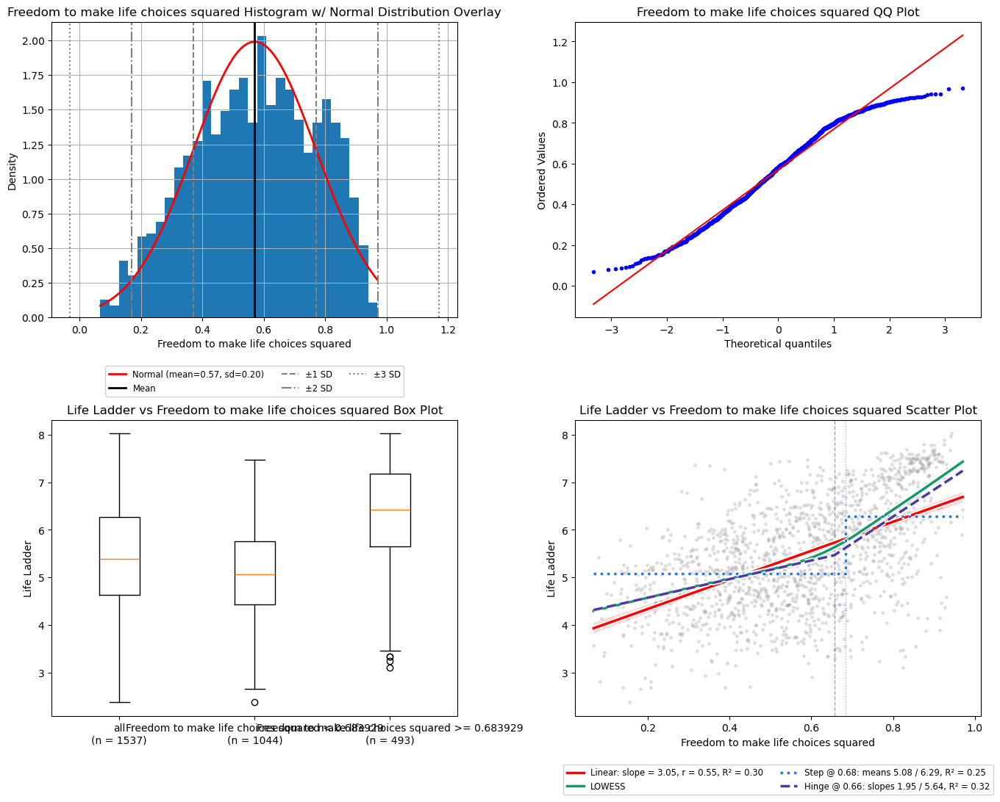

In [141]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_h_df = pd.DataFrame(
	{"Freedom to make life choices squared": np.ravel(FunctionTransformer(np.square).fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
plotting.single_feature_plots(df=free_h_df, feature="Freedom to make life choices squared", target=TARGET, threshold="auto");

#### Intervention H vs Target

In [142]:
free_results["H"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.square)), ("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "H"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
H,0.936,0.027,0.766,0.021,0.295,0.047,-0.013,0.003,-4.701,0.0,candidate,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


### Intervention I | Stretch the top (Yeo-Johnson)

**What it targets**
The same bend as H, with the amount of stretch fit to the data instead of fixed. I is a candidate: Freedom to make life choices is moderately left skewed (skew -0.606), with values crowding from about 0.85 up to the max of 0.985, and for a left skewed column Yeo-Johnson stretches the crowded top end, where Q1B saw the steep part of the bend. Q1B does not name it, but its Special Treatment asks for a transform that stretches the top end.

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a left skewed column it stretches the crowded top end and compresses the low tail. That is the same direction as the bend Q1B saw, so it both reduces the skew and bends the fit the right way. The model becomes `Life Ladder = a + b·YJ(x)`.

Box-Cox is not run separately: for positive x, Yeo-Johnson is Box-Cox applied to x + 1, and over 0.26 to 0.985 both give a similar mild stretch of the top.

**What it gives up**
The power is chosen to make the histogram symmetric, not to fit Life Ladder, so the amount of stretch at the top may be more or less than the bend needs. It also compresses the low tail, where in Q1B's plot the line sits below LOWESS.

**Hypothesis**
Expected to beat A and trail C. Compared with H, it shows whether a fitted power beats the fixed square.

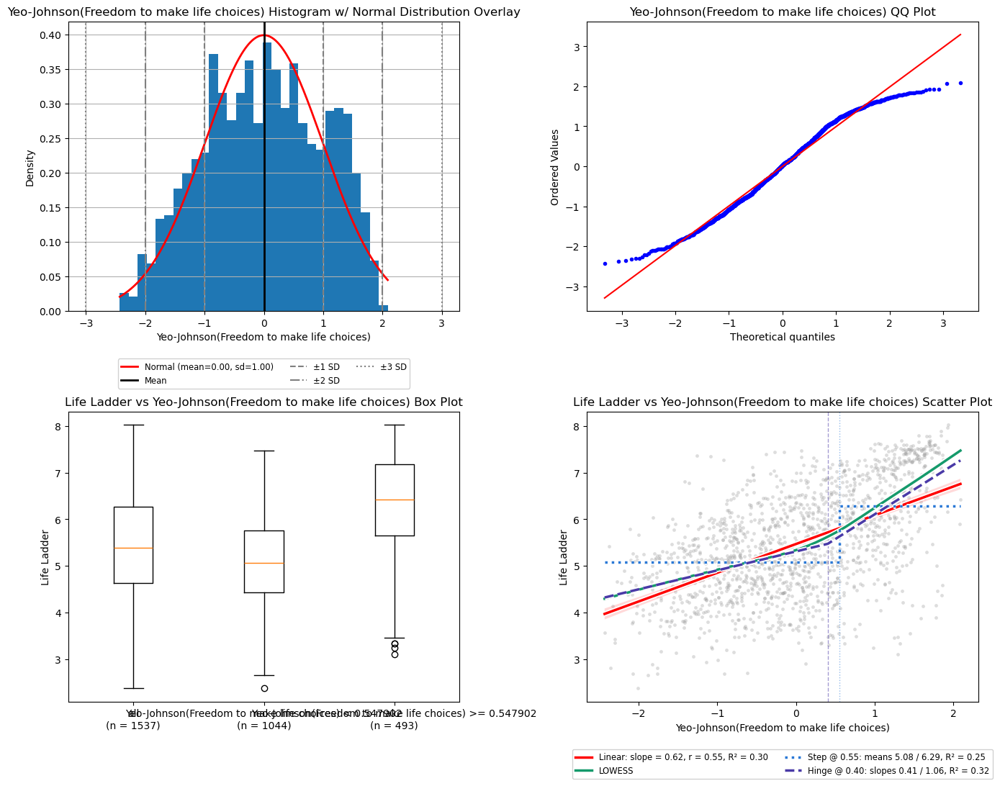

In [143]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_i_df = pd.DataFrame(
	{"Yeo-Johnson(Freedom to make life choices)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
plotting.single_feature_plots(df=free_i_df, feature="Yeo-Johnson(Freedom to make life choices)", target=TARGET, threshold="auto");

#### Intervention I vs Target

In [144]:
free_results["I"] = pipelines.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds, return_estimator=True,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "I"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
I,0.934,0.027,0.763,0.021,0.299,0.047,-0.016,0.004,-4.377,0.0,candidate,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


In [145]:
# Yeo-Johnson power fitted on each of the 20 training folds
free_i_lambdas = pd.Series([estimator.named_steps["features"].lambdas_[0] for estimator in free_results["I"]["estimator"]])
display(free_i_lambdas.describe()[["min", "50%", "max"]].rename({"50%": "median"}).round(2).rename_axis("I fitted λ").to_frame("value"))

,value
I fitted λ,
min,3.85
median,4.05
max,4.37


### Intervention J | Log control

**What it targets**
Control. Log stretches the low end and squeezes the top, the opposite of the bend Q1B saw. Q1B has no note against it. It is included to confirm which end needs stretching.

**What the intervention does**
Replaces the raw value with its natural log:

`z = log(x)`

| x | log(x) |
|---|---|
| 0.30 | -1.204 |
| 0.50 | -0.693 |
| 0.70 | -0.357 |
| 0.80 | -0.223 |
| 0.90 | -0.105 |
| 0.95 | -0.051 |
| 0.985 | -0.015 |

The log spreads out the values near the bottom and squeezes those near the top: the gap from 0.30 to 0.50 becomes 0.511, while the same 0.20 gap from 0.70 to 0.90 becomes 0.252. The model becomes `Life Ladder = a + b·log(x)`, a straight line in log(x), which is a curve in x that is steep at the low end and flat at the top. The column min is 0.26, so x is always positive and the log is always defined.

**What it gives up**
It bends the fit the wrong way: toward a curve that is steep at the low end and flat at the top, the opposite of the bend Q1B saw.

**Hypothesis**
Tests whether stretching the low end helps. Expected to tie with or lose to A.

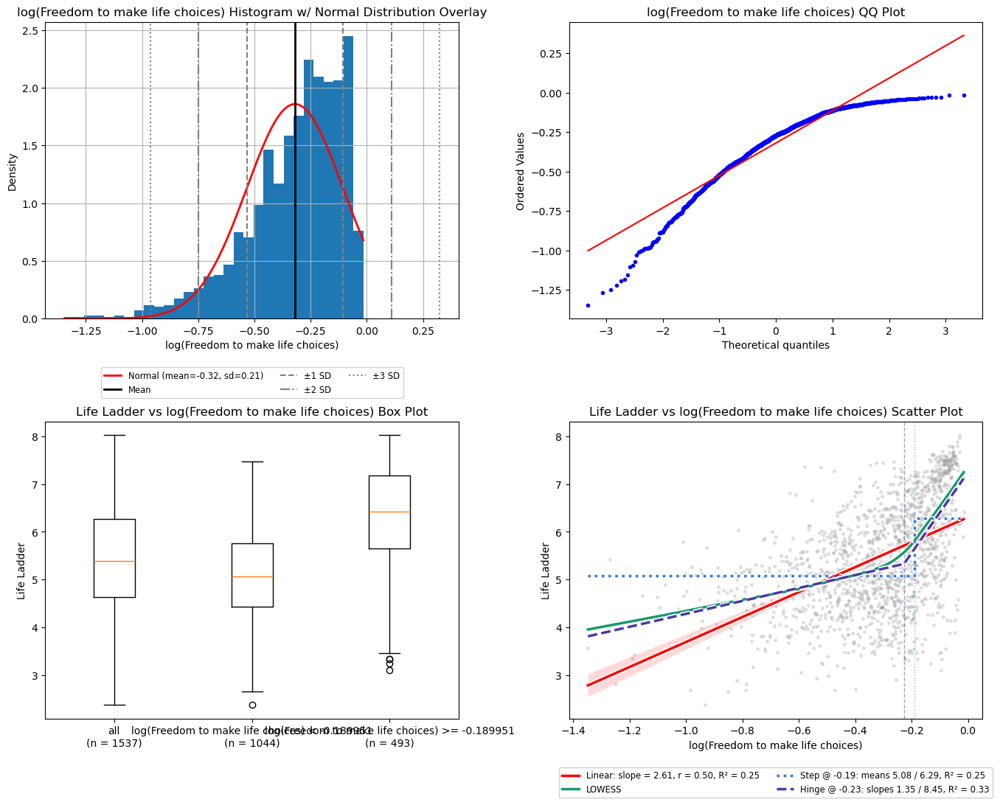

In [146]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_j_df = pd.DataFrame(
	{"log(Freedom to make life choices)": np.ravel(FunctionTransformer(np.log).fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
plotting.single_feature_plots(df=free_j_df, feature="log(Freedom to make life choices)", target=TARGET, threshold="auto");

#### Intervention J vs Target

In [147]:
free_results["J"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.log)), ("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "J"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20
J,0.968,0.027,0.795,0.024,0.247,0.041,0.019,0.003,5.539,1.0,worse,20


### Intervention K | Low tail clip (IQR fence clip)

**What it targets**
Candidate, not a control. Q1B flagged 8 low outliers below the lower IQR fence (0.333), down to the column min of 0.26, and none above the upper fence, with no note to clip or keep them. In Q1B's plot the straight line sits below LOWESS across the low tail, so the low rows pull the single slope. Clipping moves them in to the fence, which reduces that pull.

**What the intervention does**
Clips the raw value to the fences Q1 - 1.5·IQR and Q3 + 1.5·IQR, learned on each training fold. Every value below the lower fence becomes the lower fence value, every value above the upper fence becomes the upper fence value, and every value between the fences is unchanged. Q1B's upper fence (1.168) is above the column max (0.985), so only the bottom is clipped. The model becomes `Life Ladder = a + b·clip(x)`.

| x | clip(x) (Q1B's fences 0.333 / 1.168) |
|---|---|
| 0.26 | 0.333 |
| 0.30 | 0.333 |
| 0.60 | 0.60 |
| 0.985 | 0.985 |

**What it gives up**
The detail in the low tail: the 8 rows below the fence all get the same feature value and so the same prediction. With only 8 rows, any gain is small.

**Hypothesis**
Expected to beat A by a small margin, from reducing the low tail's pull on the slope.

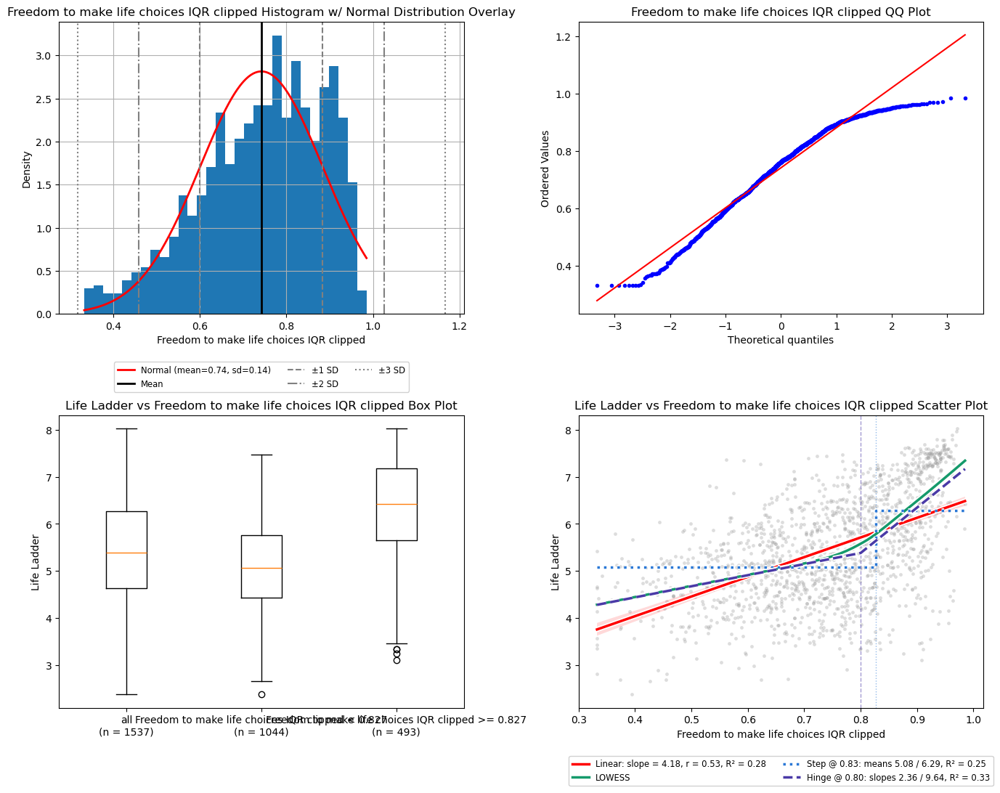

In [148]:
# fit on all free_df rows, for illustration only (the scores below refit inside each training fold)
free_k_df = pd.DataFrame(
	{"Freedom to make life choices IQR clipped": np.ravel(features.IQRClip().fit_transform(free_X)), TARGET: free_y},
	index=free_df.index,
)
plotting.single_feature_plots(df=free_k_df, feature="Freedom to make life choices IQR clipped", target=TARGET, threshold="auto");

#### Intervention K vs Target

In [149]:
free_results["K"] = pipelines.evaluate_pipeline(
	Pipeline([("features", features.IQRClip()), ("model", LinearRegression())]),
	X=free_X, y=free_y, folds=free_folds,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "K"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
K,0.949,0.027,0.778,0.023,0.276,0.046,-0.0,0.0,-0.44,0.332,within noise,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.0,NaN,NaN,NaN,baseline,20


### Intervention L | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Freedom to make life choices can explain. B to K each force one shape (bend, jump, logit curve, top-only log curve, square, power curve, log curve, clip). L tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If L scores about the same as the best of B to K:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If L is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention L vs Target

In [150]:
free_l_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

free_results["L nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(free_l_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=free_X, y=free_y, folds=free_folds, return_estimator=True,
)
display(scoring.results_df({k: free_results[k] for k in ["A", "L nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
L nested,0.925,0.027,0.749,0.020,0.312,0.049,-0.024,0.01,-2.375,0.014,candidate,20
A,0.949,0.027,0.778,0.023,0.276,0.045,0.000,NaN,NaN,NaN,baseline,20


In [151]:
# number of knots picked by the inner search in each of the 20 folds
free_l_picked = features.picked_thresholds(free_results["L nested"]["estimator"], param="features__n_knots")
display(pd.Series(free_l_picked).astype(int).value_counts().sort_index().rename_axis("L nested picked n_knots").to_frame("folds"))

,folds
L nested picked n_knots,
3,10
4,1
5,7
6,1
8,1


### Comparison

In [152]:
display(scoring.results_df(free_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
C fixed (t=0.80),0.921,0.026,0.747,0.020,0.318,0.048,-0.028,0.011,-2.670,0.008,0.076,candidate,20
C nested,0.923,0.026,0.748,0.021,0.315,0.049,-0.026,0.010,-2.531,0.010,0.092,candidate,20
G,0.924,0.027,0.748,0.020,0.313,0.049,-0.025,0.009,-2.876,0.005,0.058,candidate,20
L nested,0.925,0.027,0.749,0.020,0.312,0.049,-0.024,0.010,-2.375,0.014,0.113,candidate,20
F,0.927,0.027,0.755,0.021,0.309,0.048,-0.022,0.006,-3.526,0.001,0.015,significant,20
E fixed (t=0.827),0.931,0.023,0.760,0.019,0.303,0.043,-0.018,0.006,-2.866,0.005,0.058,candidate,20
I,0.934,0.027,0.763,0.021,0.299,0.047,-0.016,0.004,-4.377,0.000,0.002,significant,20
E nested,0.934,0.027,0.762,0.021,0.299,0.048,-0.015,0.008,-2.000,0.030,0.210,candidate,20
H,0.936,0.027,0.766,0.021,0.295,0.047,-0.013,0.003,-4.701,0.000,0.001,significant,20


## Freedom to Make Life Choices Results

- **A is moderate:** rmse 0.949 and r2 0.276, in line with Q1B's linear R² of 0.28 and between Corruption (0.178) and Social support (0.493). Freedom to make life choices is not a candidate to drop. The best intervention lifts r2 to 0.318 (C fixed).
- **Three interventions are significant, and none of them has the lowest rmse.** After the Holm adjustment, H (square, `p (Holm)` 0.001), I (Yeo-Johnson, 0.002) and F (logit, 0.015) are significant, since their gains are the most consistent across the folds (Δ / SE -4.701, -4.377 and -3.526). C fixed has the lowest rmse (0.921, Δ -0.028) but a larger Δrmse SE (0.011), so it is only a candidate (`p (Holm)` 0.076), as are C nested, G, L nested, E fixed and E nested.
- **The bend at about 0.80 is real, and the low side keeps its slope.** C nested picked t between 0.77 and 0.82 in all 20 folds and scores close to C fixed (rmse 0.923 vs 0.921). B (hinge alone) is within noise in both variants (Δ -0.003 fixed, -0.009 nested), so forcing the low side flat loses the slope that C keeps. B nested picked t between 0.59 and 0.76, all below Q1B's 0.80 (0.71 to 0.76 in 17 of 20 folds).
- **The top stretches come close to the hinge without a threshold.** G (`-log(1 - x)`) scores rmse 0.924 and F (logit) 0.927, against C fixed's 0.921, so leaving out the logit's low-end stretch helps a little, as expected. I (Yeo-Johnson, fitted λ between 3.85 and 4.37) scores 0.934 and H (square) 0.936. L, the flexible spline ceiling, scores 0.925 and does not beat C fixed (0.921). It picked 3 knots in 10 folds and 5 in 7, so the single hinge already captures the signal.
- **What loses to or ties A:** D (indicator alone) in both variants (Δ +0.019 fixed, +0.025 nested), as expected from Q1B's step R² (0.25) being below the linear R² (0.28), and J, the log control (+0.019). E (indicator + raw) beats A but trails C (rmse 0.931 for E fixed vs 0.921 for C fixed), and E nested moved the jump up from 0.827 to between 0.86 and 0.92 in all 20 folds.
- **Hypotheses that did not hold:** K (IQR clip) was expected to beat A by a small margin, but it matches A (rmse 0.949 for both, Δ / SE -0.440). The other hypotheses held, although C beats A only as a candidate, not significantly.

#### Carry forward

- **C (raw + hinge `[x, max(0, x - t)]`)** as the main candidate for the multi-feature model, with t fixed at 0.80 or searched in each fold (the nested picks fell between 0.77 and 0.82). It has the lowest rmse (0.921) but is not significant (`p (Holm)` 0.076), so it must clear the noise threshold again there.
- **G (`-log(1 - x)`) and F (logit)** as the no-threshold alternatives, single columns close to C fixed (rmse 0.924 and 0.927 vs 0.921). F is significant (`p (Holm)` 0.015) and G is not (0.058).
- **I (Yeo-Johnson) and H (square)** as lower priority alternatives: significant, with the most consistent gains, but smaller ones (Δ -0.016 and -0.013 vs C fixed's -0.028).
- **Drop:** B, D, E, J, K and L. B and E trail C, L does not beat C, and K ties A, so keep the 8 low outliers unclipped.

## Positive Affect

Rows missing Positive affect are dropped. Rows missing other attributes are kept, since only Positive affect is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported for the same shape (the hinge or the step).
- **nested** variants search t with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**The grid differs from the earlier sections.** Positive affect runs from 0.322 to 0.944. The 0.05 to 0.95 grid (step 0.02) used for Corruption and Social support covers it, but the 5% guard leaves only a narrow band of it, and that grid holds only odd hundredths. Here t is searched from 0.32 to 0.94 (step 0.01), and the 5% guard trims it to the range printed below. C searches (t1, t2) pairs with t1 < t2 from 0.32 to 0.94 (step 0.02, to keep the number of pairs small), with the guard applied to both thresholds. The setup cell also defines the `-log(1 - x)` transform used by Intervention G.

**Shapes not run.** Q1B's Special Treatment recommends no treatment ("None needed"), so A is Q1B's recommendation and B to I test that note. Four shapes run for earlier attributes are left out here:
- **Hinge alone:** Q1B's hinge fit keeps a slope of 3.59 below 0.71, and LOWESS keeps a steady slope below about 0.7, so forcing the low side flat would remove real signal.
- **Indicator alone:** Q1B's step R² (0.26) is already below the linear R² (0.29).
- **IQR clip:** Q1B flagged only 2 low outliers below the 0.36 fence and none above the 1.061 fence, too few to move the slope.
- **Logit:** it equals `-log(1 - x) + log(x)`, so on top of G's stretch of the top it only adds a stretch of the low tail, where LOWESS keeps a steady slope in Q1B's plot.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [153]:
pa_col = COLUMNS['PA']['col']
pa_df = train_df[[pa_col, TARGET]].dropna(subset=[pa_col])
pa_X = pa_df[[pa_col]]
pa_y = pa_df[TARGET]

pa_grid = np.round(np.arange(0.32, 0.941, 0.01), 2)
pa_pair_values = np.round(np.arange(0.32, 0.941, 0.02), 2)
pa_pair_grid = [(t1, t2) for t1 in pa_pair_values for t2 in pa_pair_values if t1 < t2]


def pa_neg_log_one_minus(x):
	"""-log(1 - x), used by Intervention G."""
	return -np.log1p(-x)


pa_folds = pipelines.make_folds(pa_X, seeds=SEEDS)
pa_results = {}

pa_x = pa_X[pa_col].to_numpy()
pa_guarded = [t for t in pa_grid if min(np.mean(pa_x < t), np.mean(pa_x >= t)) >= features.MIN_GROUP_FRAC]
pa_pair_guarded = [t for t in pa_pair_values if min(np.mean(pa_x < t), np.mean(pa_x >= t)) >= features.MIN_GROUP_FRAC]
print(f"rows used: {len(pa_df)} of {len(train_df)}")
print(f"folds: {len(pa_folds)}")
print(f"threshold grid after the 5% guard (all rows): {pa_guarded[0]} to {pa_guarded[-1]}")
print(f"pair grid after the 5% guard (all rows): {pa_pair_guarded[0]} to {pa_pair_guarded[-1]}")

rows used: 1542 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 0.53 to 0.86
pair grid after the 5% guard (all rows): 0.54 to 0.86


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Positive affect value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow the steeper rise above about 0.71 that LOWESS shows in Q1B.

**Hypothesis**
A sets the bar, and it is also Q1B's recommendation: Q1B's Special Treatment says no treatment is needed, since the relationship is close to linear. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model. Q1B's linear fit had R² 0.29 (slope 5.52), so A's r2 is expected to be near 0.29.

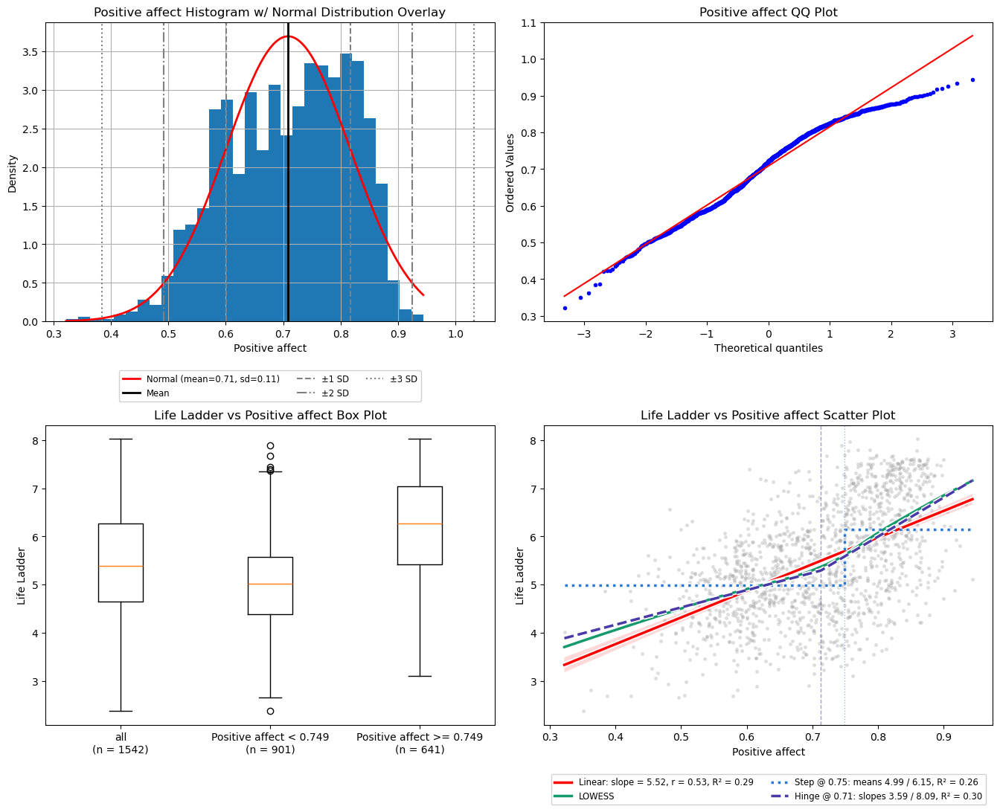

In [154]:
plotting.single_feature_plots(df=pa_df, feature=pa_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [155]:
pa_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=pa_X, y=pa_y, folds=pa_folds,
)
display(scoring.results_df({k: pa_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.944,0.02,0.768,0.017,0.282,0.031,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Linear spline (raw + hinge)

**What it targets**
In Q1B's scatter plot, LOWESS steepens above about 0.71, and Q1B's hinge fit at 0.71 found a slope of 3.59 below and 8.09 above. A LinearRegression on the raw value can only fit one slope for the whole range, so it has to compromise: in Q1B's plot the line sits below LOWESS in the low tail and at the top, and above it in the middle of the range. B keeps the raw value, so it keeps the slope below t.

**What the intervention does**
Keeps the raw value and adds a high-side hinge, the distance above a threshold `t`, as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 0.71) |
|---|---|
| 0.90 | [0.90, 0.19] |
| 0.80 | [0.80, 0.09] |
| 0.71 | [0.71, 0] |
| 0.50 | [0.50, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

Using the low-side hinge instead, `[x, max(0, t - x)]`, would give exactly the same predictions: the two hinges differ by `x - t`, which the raw column and the intercept already cover. Only the coefficients change, not the fit.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and B reduces to A with an extra parameter.

**Variants**
- **B fixed (t = 0.71):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 0.32 to 0.94 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
Q1B's hinge fit only lifts R² from 0.29 to 0.30, so B is expected to beat A by a small margin at most, much less than C did for Freedom to make life choices (rmse 0.921 vs A's 0.949). If B stays within noise, that supports Q1B's note that no treatment is needed. In Q1B's plot LOWESS turns upward gradually between about 0.65 and 0.8 rather than at one sharp corner, so the nested picks may spread around 0.71.

#### Intervention B vs Target

In [156]:
pa_b_pipeline = Pipeline([("features", features.HighHinge(t=0.71, keep_raw=True)), ("model", LinearRegression())])

pa_results["B fixed (t=0.71)"] = pipelines.evaluate_pipeline(
	pa_b_pipeline,
	X=pa_X, y=pa_y, folds=pa_folds,
)
pa_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(pa_b_pipeline, param="features__t", grid=pa_grid),
	X=pa_X, y=pa_y, folds=pa_folds, return_estimator=True,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "B fixed (t=0.71)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B fixed (t=0.71),0.936,0.021,0.760,0.018,0.294,0.030,-0.008,0.003,-2.822,0.005,candidate,20
B nested,0.936,0.021,0.760,0.018,0.294,0.030,-0.008,0.003,-2.667,0.008,candidate,20
A,0.944,0.020,0.768,0.017,0.282,0.031,0.000,NaN,NaN,NaN,baseline,20


In [157]:
# threshold picked by the inner search in each of the 20 folds
pa_b_picked = features.picked_thresholds(pa_results["B nested"]["estimator"], param="features__t")
display(pd.Series(pa_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
0.70,1
0.71,13
0.72,5
0.73,1


### Intervention C | Two-bend linear spline

**What it targets**
Whether the top of the range needs its own slope. In Q1B's scatter the few rows above about 0.9 sit mostly below LOWESS, and Q1B's QQ plot shows a short high tail. B has one slope for everything above t, and C lets the top bend again, up or down.

**What the intervention does**
Keeps the raw value and adds two high-side hinges, one at each threshold, with t1 < t2:

`[x, max(0, x - t1), max(0, x - t2)]`

For t1 = 0.71 (Q1B's hinge) and t2 = 0.85 (an example value, not a fit):

| x | features [x, h1, h2] (t1 = 0.71, t2 = 0.85) |
|---|---|
| 0.92 | [0.92, 0.21, 0.07] |
| 0.80 | [0.80, 0.09, 0] |
| 0.60 | [0.60, 0, 0] |
| 0.40 | [0.40, 0, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t1) + d·max(0, x - t2)`, three straight segments joined at t1 and t2:
- **At or below t1:** both hinges are 0, so the prediction is a line with slope b.
- **Between t1 and t2:** only the first hinge is above 0, so the prediction is a line with slope b + c.
- **Above t2:** both hinges are above 0, so the prediction is a line with slope b + c + d.

The segments meet at t1 and t2, so the prediction has corners there but no jumps. No plot cell, since the feature is three columns.

**What it gives up**
Two extra coefficients and two thresholds to search instead of one, which gives the model and the inner search more room to fit noise in the training folds.

**Variants**
- **C nested only.** Q1B fitted only one hinge, so there is no fixed pair. t1 and t2 are searched together over every pair from 0.32 to 0.94 (step 0.02) with t1 < t2, inside each training fold (inner 4-fold CV), and both t1 and t2 must leave at least 5% of the training fold's rows on each side. The validation rows never influence the pair, and the pairs it picks show where the data place the two bends.

**Hypothesis**
If the slope above the first bend holds all the way up, the second hinge's coefficient ends up near 0 and C ties with B. If the top flattens, as the few rows above about 0.9 suggest, C beats B. The 5% guard keeps t2 out of the top 5% of rows (see the pair grid range printed by the setup cell), so the second bend cannot start inside the top tail itself.

#### Intervention C vs Target

In [158]:
pa_c_pipeline = Pipeline([
	("features", FeatureUnion([("low", features.HighHinge(t=0.71, keep_raw=True)), ("high", features.HighHinge(t=0.85))])),
	("model", LinearRegression()),
])

pa_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(pa_c_pipeline, param=("features__low__t", "features__high__t"), grid=pa_pair_grid),
	X=pa_X, y=pa_y, folds=pa_folds, return_estimator=True,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C nested,0.934,0.022,0.758,0.020,0.298,0.030,-0.01,0.004,-2.528,0.01,candidate,20
A,0.944,0.020,0.768,0.017,0.282,0.031,0.00,NaN,NaN,NaN,baseline,20


In [159]:
# (t1, t2) pair picked by the inner search in each of the 20 folds, sorted as numbers before formatting
pa_c_picked = sorted(
	features.picked_thresholds(pa_results["C nested"]["estimator"], param=("features__low__t", "features__high__t")))
pa_c_picked = [f"({t1:.2f}, {t2:.2f})" for t1, t2 in pa_c_picked]
display(pd.Series(pa_c_picked).value_counts(sort=False).rename_axis("C nested picked (t1, t2)").to_frame("folds"))

,folds
"C nested picked (t1, t2)",
"(0.66, 0.68)",1
"(0.72, 0.84)",1
"(0.72, 0.86)",8
"(0.74, 0.76)",1
"(0.74, 0.84)",7
"(0.74, 0.86)",2


### Intervention D | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range. Q1B's step fit at 0.749 (the legend shows 0.75) split the rows into two groups with mean Life Ladder 4.99 below and 6.15 at or above, with 901 rows below and 641 at or above in the box plot. The step alone (R² 0.26) is below the linear fit (R² 0.29), so D keeps the raw trend and adds the jump on top.

**What the intervention does**
Keeps the raw value and adds a binary indicator, 1 below a threshold `t` and 0 at or above it, as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 0.749) |
|---|---|
| 0.90 | [0.90, 0] |
| 0.749 | [0.749, 0] |
| 0.70 | [0.70, 1] |
| 0.50 | [0.50, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot make the top steeper than the low side.

**Variants**
- **D fixed (t = 0.749):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D nested:** t is searched from 0.32 to 0.94 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
Tests a jump at t on top of the trend. Q1B's LOWESS shows a bend near 0.71 rather than a jump. LOWESS averages over a wide window, though, so a jump in the rows near 0.749 would also show up as a gradual bend. If the rise near 0.75 is a jump, D matches or beats B. If it is a bend, D trails B, as E trailed C in Freedom to make life choices (rmse 0.931 vs 0.921).

#### Intervention D vs Target

In [160]:
pa_d_pipeline = Pipeline([("features", features.Indicator(t=0.749, keep_raw=True)), ("model", LinearRegression())])

pa_results["D fixed (t=0.749)"] = pipelines.evaluate_pipeline(
	pa_d_pipeline,
	X=pa_X, y=pa_y, folds=pa_folds,
)
pa_results["D nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(pa_d_pipeline, param="features__t", grid=pa_grid),
	X=pa_X, y=pa_y, folds=pa_folds, return_estimator=True,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "D fixed (t=0.749)", "D nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D fixed (t=0.749),0.933,0.020,0.757,0.017,0.298,0.029,-0.011,0.004,-3.013,0.004,candidate,20
D nested,0.936,0.019,0.759,0.017,0.294,0.030,-0.008,0.004,-2.012,0.029,candidate,20
A,0.944,0.020,0.768,0.017,0.282,0.031,0.000,NaN,NaN,NaN,baseline,20


In [161]:
# threshold picked by the inner search in each of the 20 folds
pa_d_picked = features.picked_thresholds(pa_results["D nested"]["estimator"], param="features__t")
display(pd.Series(pa_d_picked).value_counts().sort_index().rename_axis("D nested picked t").to_frame("folds"))

,folds
D nested picked t,
0.67,1
0.75,17
0.78,2


### Intervention E | Stretch the top (square)

**What it targets**
Candidate. The same bend as B, with a smooth curve and no threshold to pick. Squaring stretches the top end, where LOWESS steepens in Q1B's plot.

**What the intervention does**
Replaces the raw value with its square:

`z = x²`

| x | x² |
|---|---|
| 0.322 | 0.104 |
| 0.40 | 0.160 |
| 0.50 | 0.250 |
| 0.60 | 0.360 |
| 0.70 | 0.490 |
| 0.80 | 0.640 |
| 0.90 | 0.810 |
| 0.944 | 0.891 |

Squaring spreads out the values near the top more than those near the bottom: the gap from 0.40 to 0.60 becomes 0.200, while the same 0.20 gap from 0.70 to 0.90 becomes 0.320. So the top is stretched, but only mildly across 0.322 to 0.944. The model becomes `Life Ladder = a + b·x²`, a straight line in x², which is a curve in x that gets steeper toward the top.

**What it gives up**
It assumes the bend has the fixed shape of x², with no parameter to adjust it. Its bend is mild compared with the hinge's slopes of 3.59 below and 8.09 above 0.71.

**Hypothesis**
Expected to beat A by a small margin, since it bends the fit the same way as the hinge, and to trail B, since the bend of x² is mild over this range.

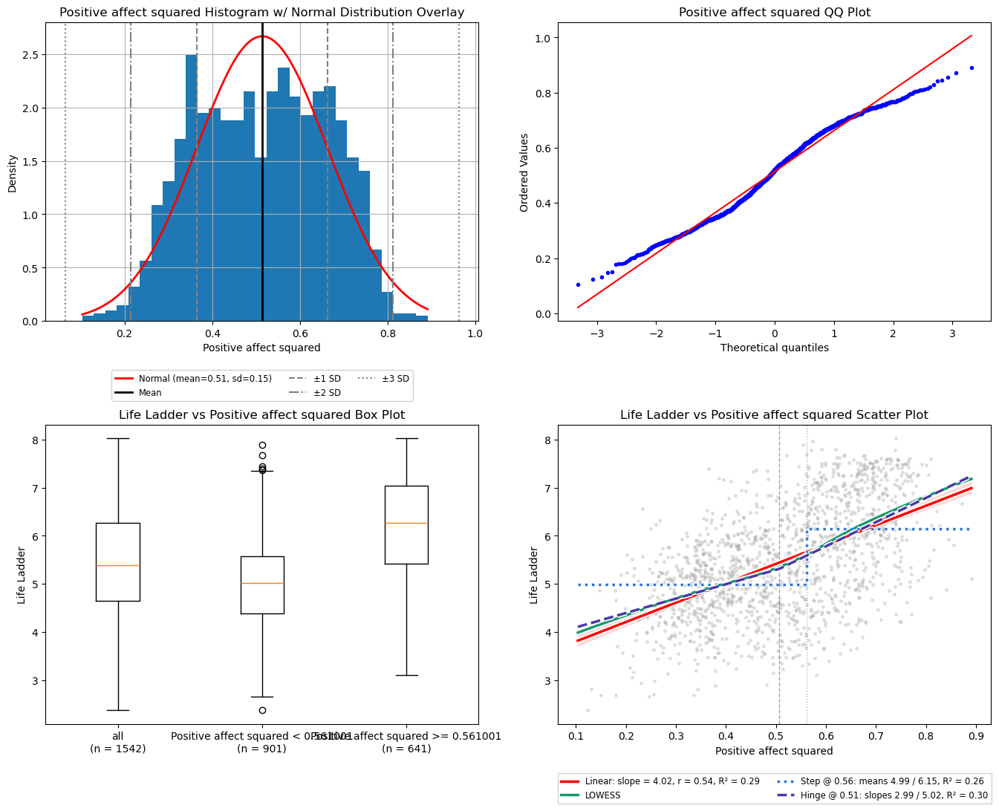

In [162]:
# fit on all pa_df rows, for illustration only (the scores below refit inside each training fold)
pa_e_df = pd.DataFrame(
	{"Positive affect squared": np.ravel(FunctionTransformer(np.square).fit_transform(pa_X)), TARGET: pa_y},
	index=pa_df.index,
)
plotting.single_feature_plots(df=pa_e_df, feature="Positive affect squared", target=TARGET, threshold="auto");

#### Intervention E vs Target

In [163]:
pa_results["E"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.square)), ("model", LinearRegression())]),
	X=pa_X, y=pa_y, folds=pa_folds,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "E"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E,0.941,0.021,0.764,0.017,0.287,0.030,-0.003,0.001,-2.523,0.01,candidate,20
A,0.944,0.020,0.768,0.017,0.282,0.031,0.000,NaN,NaN,NaN,baseline,20


### Intervention F | Stretch the top (Yeo-Johnson)

**What it targets**
The same bend as E, with the amount of stretch fit to the data instead of fixed. F is a candidate: Positive affect is mildly left skewed (skew -0.348), and Q1B's QQ plot shows a short high tail. For a left skewed column Yeo-Johnson stretches the top end, where LOWESS steepens. Q1B does not name it, since it recommends no treatment.

**What the intervention does**
Replaces the raw value with its Yeo-Johnson transform, with the power parameter fit on each training fold. Yeo-Johnson reshapes the column toward a symmetric histogram, so for a left skewed column it stretches the top end and compresses the low tail. That is the same direction as the bend Q1B saw, so it both reduces the skew and bends the fit the right way. The model becomes `Life Ladder = a + b·YJ(x)`.

Box-Cox is not run separately: for positive x, Yeo-Johnson is Box-Cox applied to x + 1, and over 0.322 to 0.944 both give a similar mild stretch of the top.

**What it gives up**
The power is chosen to make the histogram symmetric, not to fit Life Ladder, so the amount of stretch at the top may be more or less than the bend needs. It also compresses the low tail, where in Q1B's plot the line sits below LOWESS.

**Hypothesis**
Expected to beat A by a small margin and to trail B. Compared with E, it shows whether a fitted power beats the fixed square.

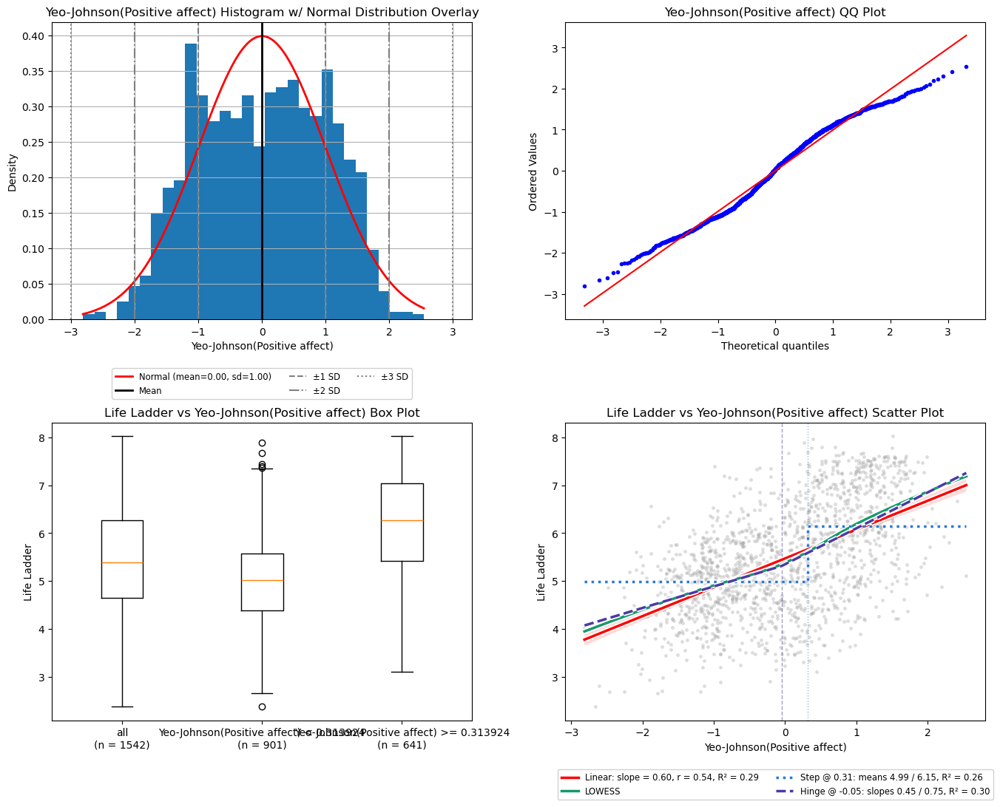

In [164]:
# fit on all pa_df rows, for illustration only (the scores below refit inside each training fold)
pa_f_df = pd.DataFrame(
	{"Yeo-Johnson(Positive affect)": np.ravel(PowerTransformer(method="yeo-johnson").fit_transform(pa_X)), TARGET: pa_y},
	index=pa_df.index,
)
plotting.single_feature_plots(df=pa_f_df, feature="Yeo-Johnson(Positive affect)", target=TARGET, threshold="auto");

#### Intervention F vs Target

In [165]:
pa_results["F"] = pipelines.evaluate_pipeline(
	Pipeline([("features", PowerTransformer(method="yeo-johnson")), ("model", LinearRegression())]),
	X=pa_X, y=pa_y, folds=pa_folds, return_estimator=True,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "F"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
F,0.941,0.021,0.765,0.017,0.287,0.030,-0.003,0.001,-2.457,0.012,candidate,20
A,0.944,0.020,0.768,0.017,0.282,0.031,0.000,NaN,NaN,NaN,baseline,20


In [166]:
# Yeo-Johnson power fitted on each of the 20 training folds
pa_f_lambdas = pd.Series([estimator.named_steps["features"].lambdas_[0] for estimator in pa_results["F"]["estimator"]])
display(pa_f_lambdas.describe()[["min", "50%", "max"]].rename({"50%": "median"}).round(2).rename_axis("F fitted λ").to_frame("value"))

,value
F fitted λ,
min,3.10
median,3.45
max,3.83


### Intervention G | Stretch the top only (-log(1 - x))

**What it targets**
Candidate. The same bend as E and F, with a much stronger stretch of the top. Unlike the logit, it stretches only the top (see the setup notes).

**What the intervention does**
Replaces the raw value with `-log(1 - x)`:

`z = -log(1 - x)`

| x | -log(1 - x) |
|---|---|
| 0.322 | 0.389 |
| 0.40 | 0.511 |
| 0.50 | 0.693 |
| 0.60 | 0.916 |
| 0.70 | 1.204 |
| 0.80 | 1.609 |
| 0.90 | 2.303 |
| 0.944 | 2.882 |

It spreads the low end only a little and stretches the top much more: the gap from 0.40 to 0.60 becomes 0.405, while the same 0.20 gap from 0.70 to 0.90 becomes 1.099, and the last 0.044 from 0.90 to the max of 0.944 becomes about 0.58. The model becomes `Life Ladder = a + b·(-log(1 - x))`, a curve in x that gets steeper and steeper toward the top. The column max is 0.944, so `1 - x` is never 0 in these rows and the transform is always defined. It is computed as `-np.log1p(-x)` by `pa_neg_log_one_minus`, defined in the setup cell.

**What it gives up**
It assumes the bend has this fixed shape, with no parameter to adjust it. Its slope keeps rising all the way to the max, so the few rows nearest the max get the most pull on the slope, and in Q1B's scatter the rows above about 0.9 sit mostly below LOWESS.

**Hypothesis**
Expected to beat A by less than E and F, and it may tie A, since the strongest stretch goes to the rows above about 0.9, which sit below LOWESS. This is the opposite of Freedom to make life choices, where `-log(1 - x)` beat the square (rmse 0.924 vs 0.936).

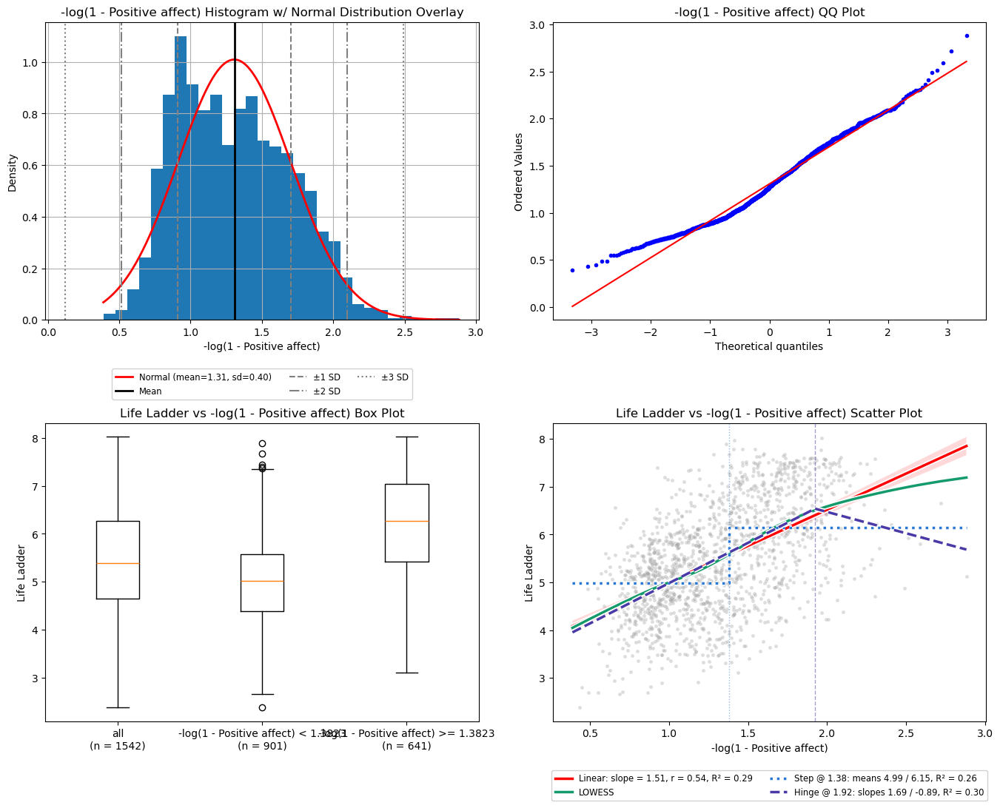

In [167]:
# fit on all pa_df rows, for illustration only (the scores below refit inside each training fold)
pa_g_df = pd.DataFrame(
	{"-log(1 - Positive affect)": np.ravel(FunctionTransformer(pa_neg_log_one_minus).fit_transform(pa_X)), TARGET: pa_y},
	index=pa_df.index,
)
plotting.single_feature_plots(df=pa_g_df, feature="-log(1 - Positive affect)", target=TARGET, threshold="auto");

#### Intervention G vs Target

In [168]:
pa_results["G"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(pa_neg_log_one_minus)), ("model", LinearRegression())]),
	X=pa_X, y=pa_y, folds=pa_folds,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "G"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
G,0.944,0.022,0.766,0.019,0.283,0.030,-0.0,0.003,-0.097,0.462,within noise,20
A,0.944,0.020,0.768,0.017,0.282,0.031,0.0,NaN,NaN,NaN,baseline,20


### Intervention H | Log control

**What it targets**
Control. Log stretches the low end and squeezes the top, the opposite of the bend Q1B saw. Q1B has no note on it. It is included to confirm which end needs stretching.

**What the intervention does**
Replaces the raw value with its natural log:

`z = log(x)`

| x | log(x) |
|---|---|
| 0.322 | -1.133 |
| 0.40 | -0.916 |
| 0.50 | -0.693 |
| 0.60 | -0.511 |
| 0.70 | -0.357 |
| 0.80 | -0.223 |
| 0.90 | -0.105 |
| 0.944 | -0.058 |

The log spreads out the values near the bottom and squeezes those near the top: the gap from 0.40 to 0.60 becomes 0.405, while the same 0.20 gap from 0.70 to 0.90 becomes about 0.25. The model becomes `Life Ladder = a + b·log(x)`, a straight line in log(x), which is a curve in x that is steep at the low end and flat at the top. The column min is 0.322, so x is always positive and the log is always defined.

**What it gives up**
It bends the fit the wrong way: toward a curve that is steep at the low end and flat at the top, the opposite of the bend Q1B saw.

**Hypothesis**
Tests whether stretching the low end helps. Expected to tie with or lose to A.

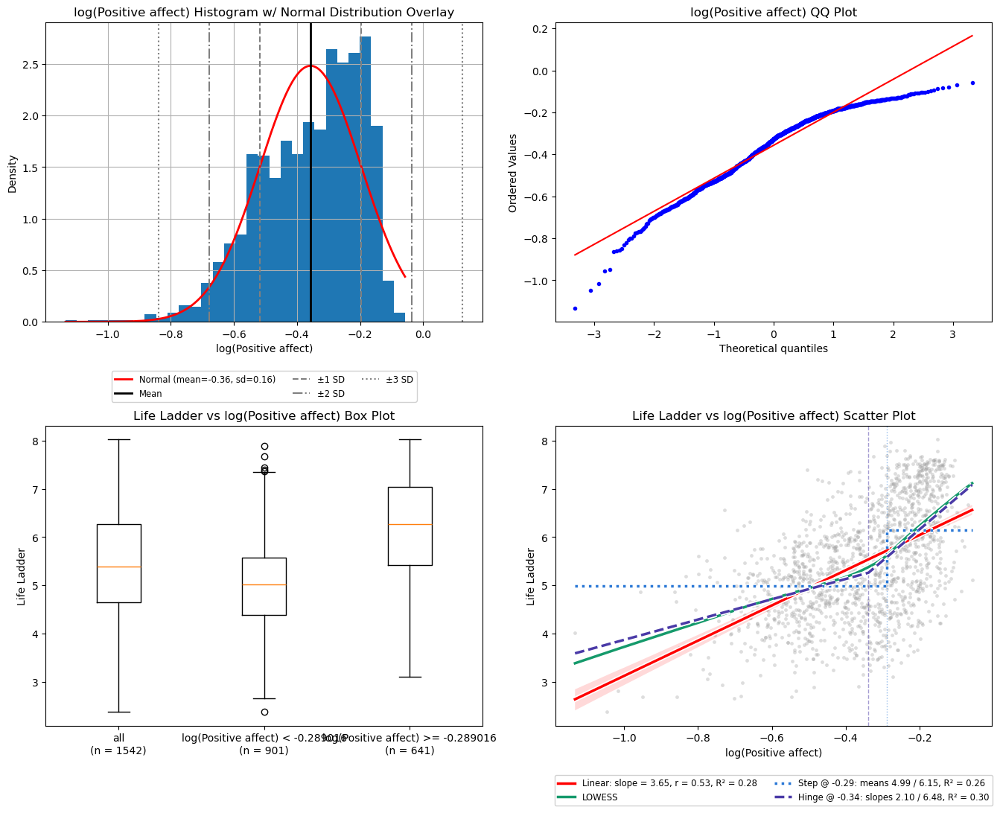

In [169]:
# fit on all pa_df rows, for illustration only (the scores below refit inside each training fold)
pa_h_df = pd.DataFrame(
	{"log(Positive affect)": np.ravel(FunctionTransformer(np.log).fit_transform(pa_X)), TARGET: pa_y},
	index=pa_df.index,
)
plotting.single_feature_plots(df=pa_h_df, feature="log(Positive affect)", target=TARGET, threshold="auto");

#### Intervention H vs Target

In [170]:
pa_results["H"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.log)), ("model", LinearRegression())]),
	X=pa_X, y=pa_y, folds=pa_folds,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "H"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.944,0.02,0.768,0.017,0.282,0.031,0.000,NaN,NaN,NaN,baseline,20
H,0.951,0.02,0.773,0.017,0.272,0.031,0.007,0.002,4.385,1.0,worse,20


### Intervention I | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Positive affect can explain. B to H each force one shape (bend, two bends, jump, square, power curve, top-only log curve, log curve). I tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If I scores about the same as the best of B to H:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If I is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention I vs Target

In [171]:
pa_i_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

pa_results["I nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(pa_i_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=pa_X, y=pa_y, folds=pa_folds, return_estimator=True,
)
display(scoring.results_df({k: pa_results[k] for k in ["A", "I nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
I nested,0.937,0.028,0.760,0.022,0.293,0.036,-0.007,0.009,-0.799,0.217,within noise,20
A,0.944,0.020,0.768,0.017,0.282,0.031,0.000,NaN,NaN,NaN,baseline,20


In [172]:
# number of knots picked by the inner search in each of the 20 folds
pa_i_picked = features.picked_thresholds(pa_results["I nested"]["estimator"], param="features__n_knots")
display(pd.Series(pa_i_picked).astype(int).value_counts().sort_index().rename_axis("I nested picked n_knots").to_frame("folds"))

,folds
I nested picked n_knots,
3,1
4,12
6,5
8,2


### Comparison

In [173]:
display(scoring.results_df(pa_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
D fixed (t=0.749),0.933,0.020,0.757,0.017,0.298,0.029,-0.011,0.004,-3.013,0.004,0.036,significant,20
C nested,0.934,0.022,0.758,0.020,0.298,0.030,-0.010,0.004,-2.528,0.010,0.072,candidate,20
B fixed (t=0.71),0.936,0.021,0.760,0.018,0.294,0.030,-0.008,0.003,-2.822,0.005,0.049,significant,20
D nested,0.936,0.019,0.759,0.017,0.294,0.030,-0.008,0.004,-2.012,0.029,0.117,candidate,20
B nested,0.936,0.021,0.760,0.018,0.294,0.030,-0.008,0.003,-2.667,0.008,0.061,candidate,20
I nested,0.937,0.028,0.760,0.022,0.293,0.036,-0.007,0.009,-0.799,0.217,0.651,within noise,20
F,0.941,0.021,0.765,0.017,0.287,0.030,-0.003,0.001,-2.457,0.012,0.072,candidate,20
E,0.941,0.021,0.764,0.017,0.287,0.030,-0.003,0.001,-2.523,0.010,0.072,candidate,20
G,0.944,0.022,0.766,0.019,0.283,0.030,-0.000,0.003,-0.097,0.462,0.924,within noise,20


## Positive Affect Results

- **A is moderate:** rmse 0.944 and r2 0.282, in line with Q1B's linear R² of 0.29 and close to Freedom to make life choices (0.276). Positive affect is not a candidate to drop. The best intervention only lifts r2 to 0.298 (D fixed and C nested).
- **Two interventions are significant, so Q1B's "None needed" holds only loosely.** After the Holm adjustment, D fixed (`p (Holm)` 0.036) and B fixed (0.049) are significant, but their gains are small: Δ -0.011 and -0.008 on an A rmse of 0.944, against -0.028 for Freedom to make life choices' C fixed. C nested, D nested, B nested, E and F are candidates.
- **The rise near 0.75 behaves like a jump.** D fixed (indicator + raw at 0.749) has the lowest rmse (0.933 vs B fixed's 0.936) and the most consistent gain (Δ / SE -3.013), and D nested picked 0.75 in 17 of 20 folds. B (raw + hinge) scores rmse 0.936 in both variants, and B nested picked t between 0.70 and 0.73 (0.71 in 13 folds). C (two bends) scores 0.934, so the second bend adds little over B: its picks were (0.72 or 0.74, 0.84 or 0.86) in 18 of 20 folds, with the second bend at or near the top of the guarded range (0.86).
- **The smooth stretches gain little.** E (square) and F (Yeo-Johnson, fitted λ between 3.10 and 3.83) both score rmse 0.941 (Δ -0.003), so the fitted power does no better than the square. G (`-log(1 - x)`) ties A (rmse 0.944 for both, Δ / SE -0.097), the opposite of Freedom to make life choices, and H, the log control, loses to A (+0.007). I, the flexible spline ceiling, scores 0.937 and does not beat D fixed (0.933). Its Δrmse SE (0.009) is the largest in the table, so it is within noise. It picked 4 knots in 12 of 20 folds.
- **Hypotheses that did not hold:** B nested's picks were expected to spread around 0.71, but they stayed between 0.70 and 0.73. C was expected to beat B if the top flattens, and its edge is small (rmse 0.934 vs 0.936). The other hypotheses held: B beats A by a small margin, D's jump branch (D matches or beats B), E and F trail B, G ties A, and H loses.

#### Carry forward

- **D (raw + indicator `[x, 1[x < t]]`)** as the main candidate for the multi-feature model, with t fixed at 0.749 (D nested picked 0.75 in 17 of 20 folds). It has the lowest rmse (0.933) and is significant (`p (Holm)` 0.036).
- **B (raw + hinge `[x, max(0, x - t)]`, t = 0.71)** as the alternative, also significant (`p (Holm)` 0.049), with nested picks between 0.70 and 0.73.
- **E (square) or F (Yeo-Johnson)** as lower priority no-threshold alternatives: candidates with the smallest gains (Δ -0.003 each, `p (Holm)` 0.072).
- **The raw column stays a close fallback.** Every gain is small (best r2 0.298 vs A's 0.282), so D and B must clear the noise threshold again in the multi-feature stage. If they do not, keep the raw column, as Q1B recommends.
- **Drop:** C, G, H and I. C adds a second threshold for rmse 0.934 vs B's 0.936, with its second bend at the edge of the guarded range. G ties A, H loses, and I does not beat D fixed. Keep the 2 low outliers unclipped.

## Log GDP Per Capita

Rows missing Log GDP per capita are dropped. Rows missing other attributes are kept, since only Log GDP per capita is used here.

Every intervention is scored on the same 20 folds: 4-fold cross validation repeated over 5 seeds (`SEEDS`). Every intervention is a `Pipeline` of a transform then `LinearRegression`, fit inside each training fold.

- **fixed** variants use the threshold t that Q1B reported for the same shape (the hinge or the step).
- **nested** variants search t with an inner 4-fold CV inside each training fold, keeping only thresholds that leave at least 5% of the training fold's rows on each side (the same guard as Q1B), so the picked t never sees the validation fold.

**The grid differs from the earlier sections.** Log GDP per capita is in log units and runs from 6.635 to 11.648, so the 0.05 to 0.95 grid used for Corruption and Social support lies entirely outside it. Here t is searched from 6.60 to 11.65 (step 0.01), which holds Q1B's hinge (10.13) and step (9.63), and the 5% guard trims it to the range printed below. C searches (t1, t2) pairs with t1 < t2 from 6.6 to 11.6 (step 0.1, to keep the number of pairs small), with the guard applied to both thresholds.

**Shapes not run.** Q1B's Special Treatment recommends no treatment ("None needed, and do not log it again. A mild hinge near 10 is optional if it improves the model."), so A is Q1B's recommendation and B to G test that note. Six shapes are left out here:
- **Hinge alone:** Q1B's hinge fit keeps a slope of 0.62 below 10.13, and LOWESS keeps rising below about 10, so forcing the low side flat would remove real signal.
- **Indicator alone:** Q1B's step R² (0.45) is well below the linear R² (0.62).
- **IQR clip:** Q1B found no outliers. Both fences (5.652 / 13.14) lie outside the column's range (6.635 to 11.648), so a clip would change nothing.
- **exp(x):** it undoes the log and stretches the top hardest, but in Q1B's scatter the rows above about 11.3 sit mostly below LOWESS. In Positive affect the strongest top stretch (`-log(1 - x)`) tied A for the same reason (rmse 0.944 for both).
- **Yeo-Johnson (and Box-Cox):** in the earlier sections the fitted power landed with the square (rmse 0.941 for both in Positive affect, and 0.936 vs 0.934 in Freedom to make life choices), so E covers it.
- **Logit and `-log(1 - x)`:** both need values between 0 and 1, and Log GDP per capita is not on that scale.

**Noise threshold (Δrmse vs A)**

- Every intervention is compared with A on the same 20 folds, using the per-fold rmse differences d (intervention minus A). A negative Δ means lower error than A.
- The folds share most of their training rows, so their scores are not independent. The SE of the mean difference is corrected with the Nadeau and Bengio factor: `SE = sqrt(var(d) · (1/20 + n_test/n_train))`.
- `Δ / SE` is the corrected t statistic and `p` is its one-sided p-value for "lower rmse than A".
- `verdict` follows the one-standard-error rule:
  - **within noise:** Δ is between -1 SE and +1 SE, so A is kept as the simpler model.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE, so the intervention is clearly worse than A.
  - **significant** (Comparison table only): the Holm-adjusted p is below 0.05 across all interventions, which guards against picking a lucky winner out of many.
- Only **candidate** or **significant** interventions carry forward to the multi-feature stage.

In [174]:
gdp_col = COLUMNS['LGDP']['col']
gdp_df = train_df[[gdp_col, TARGET]].dropna(subset=[gdp_col])
gdp_X = gdp_df[[gdp_col]]
gdp_y = gdp_df[TARGET]

gdp_grid = np.round(np.arange(6.60, 11.651, 0.01), 2)
gdp_pair_values = np.round(np.arange(6.6, 11.651, 0.1), 1)
gdp_pair_grid = [(t1, t2) for t1 in gdp_pair_values for t2 in gdp_pair_values if t1 < t2]

gdp_folds = pipelines.make_folds(gdp_X, seeds=SEEDS)
gdp_results = {}

gdp_x = gdp_X[gdp_col].to_numpy()
gdp_guarded = [t for t in gdp_grid if min(np.mean(gdp_x < t), np.mean(gdp_x >= t)) >= features.MIN_GROUP_FRAC]
gdp_pair_guarded = [t for t in gdp_pair_values if min(np.mean(gdp_x < t), np.mean(gdp_x >= t)) >= features.MIN_GROUP_FRAC]
print(f"rows used: {len(gdp_df)} of {len(train_df)}")
print(f"folds: {len(gdp_folds)}")
print(f"threshold grid after the 5% guard (all rows): {gdp_guarded[0]} to {gdp_guarded[-1]}")
print(f"pair grid after the 5% guard (all rows): {gdp_pair_guarded[0]} to {gdp_pair_guarded[-1]}")

rows used: 1533 of 1559
folds: 20
threshold grid after the 5% guard (all rows): 7.37 to 10.94
pair grid after the 5% guard (all rows): 7.4 to 10.9


### Intervention A | Baseline (raw)

**What it targets**
Nothing. A is the reference that every other intervention is measured against.

**What the intervention does**
The LR gets the raw Log GDP per capita value `x` with no transform and fits one straight line:

`Life Ladder = a + b·x`

The plot below is Q1B's view of the raw column, kept here for side-by-side reference with the transformed features further down.

**What it gives up**
Nothing in the column is changed, but the line cannot bend. It has one slope for the whole range, so it cannot follow the steeper rise above about 10 that LOWESS shows in Q1B. In Q1B's scatter the line sits below LOWESS at the low end and at the top, and above it between about 8.5 and 10.3.

**Hypothesis**
A sets the bar, and it is also Q1B's recommendation: Q1B's Special Treatment says no treatment is needed and not to log the column again. Every other intervention must beat A by more than the noise threshold to be worth carrying forward. Otherwise A is kept as the simpler model. Q1B's linear fit had R² 0.62 (slope 0.75), so A's r2 is expected to be near 0.62, the highest A so far (Healthy life expectancy 0.562).

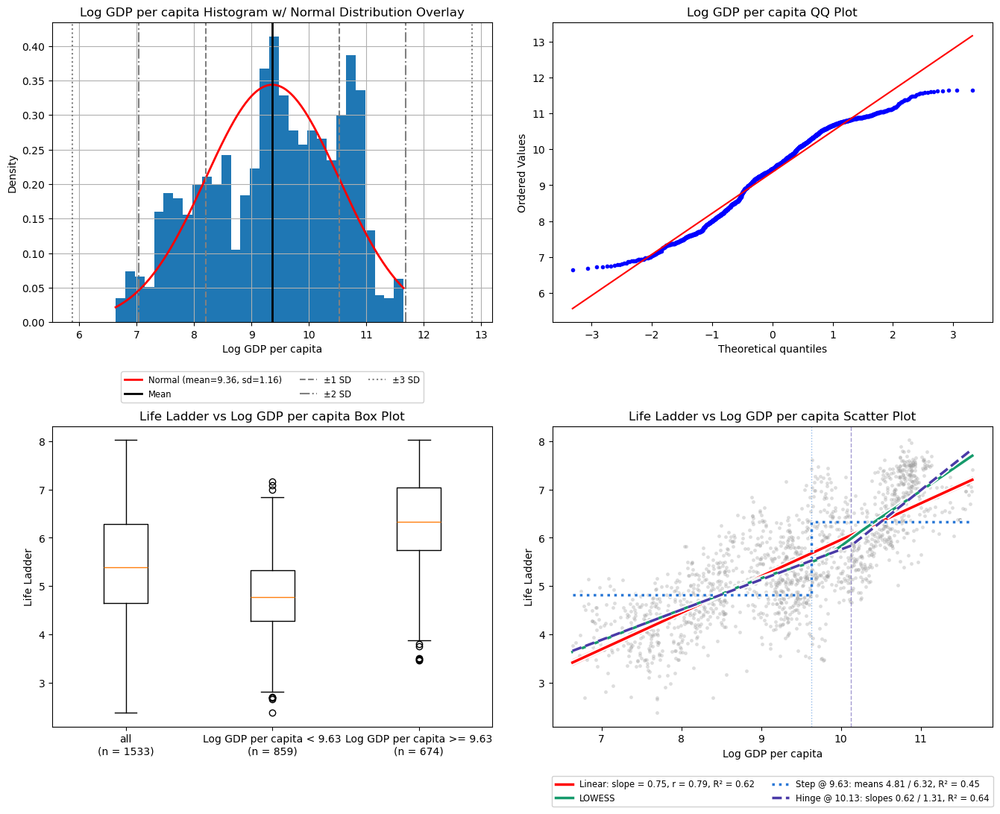

In [175]:
plotting.single_feature_plots(df=gdp_df, feature=gdp_col, target=TARGET, threshold="auto");

#### Intervention A vs Target

In [176]:
gdp_results["A"] = pipelines.evaluate_pipeline(
	Pipeline([("model", LinearRegression())]),
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
display(scoring.results_df({k: gdp_results[k] for k in ["A"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.687,0.011,0.557,0.009,0.617,0.015,0.0,NaN,NaN,NaN,baseline,20


### Intervention B | Linear spline (raw + hinge)

**What it targets**
Q1B's note says LOWESS steepens slightly above about 10, and Q1B's hinge fit at 10.13 found a slope of 0.62 below and 1.31 above. A LinearRegression on the raw value can only fit one slope for the whole range, so it has to compromise: in Q1B's plot the line sits below LOWESS at the low end and at the top, and above it between about 8.5 and 10.3. B keeps the raw value, so it keeps the slope below t. Q1B's Special Treatment names this shape as optional ("A mild hinge near 10 is optional if it improves the model").

**What the intervention does**
Keeps the raw value and adds a high-side hinge, the distance above a threshold `t`, as a second feature:

`[x, max(0, x - t)]`

| x | features [x, h] (t = 10.13) |
|---|---|
| 11.50 | [11.50, 1.37] |
| 10.50 | [10.50, 0.37] |
| 10.13 | [10.13, 0] |
| 8.00 | [8.00, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t)`, two straight segments joined at t:
- **At or below t:** h = 0, so the prediction is `a + b·x`, a line with slope b.
- **Above t:** h = x - t, so the prediction is `(a - c·t) + (b + c)·x`, a line with slope b + c.

The two segments meet at t, so the prediction has a corner there but no jump. No plot cell, since the feature is two columns.

Using the low-side hinge instead, `[x, max(0, t - x)]`, would give exactly the same predictions: the two hinges differ by `x - t`, which the raw column and the intercept already cover. Only the coefficients change, not the fit.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. If the bend is not real, c ends up near 0 and B reduces to A with an extra parameter.

**Variants**
- **B fixed (t = 10.13):** Q1B's hinge threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **B nested:** t is searched from 6.60 to 11.65 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the corner.

**Hypothesis**
Q1B's hinge fit only lifts R² from 0.62 to 0.64, so B is expected to beat A by a small margin. The slope above 10.13 (1.31) is much steeper than below (0.62), so even a small gain may be consistent across the folds, which `Δ / SE` shows. In Q1B's plot LOWESS turns upward gradually rather than at one sharp corner, so the nested picks may spread around 10.13.

#### Intervention B vs Target

In [177]:
gdp_b_pipeline = Pipeline([("features", features.HighHinge(t=10.13, keep_raw=True)), ("model", LinearRegression())])

gdp_results["B fixed (t=10.13)"] = pipelines.evaluate_pipeline(
	gdp_b_pipeline,
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
gdp_results["B nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gdp_b_pipeline, param="features__t", grid=gdp_grid),
	X=gdp_X, y=gdp_y, folds=gdp_folds, return_estimator=True,
)
display(scoring.results_df({k: gdp_results[k] for k in ["A", "B fixed (t=10.13)", "B nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
B fixed (t=10.13),0.670,0.013,0.539,0.010,0.636,0.018,-0.017,0.004,-4.486,0.0,candidate,20
B nested,0.670,0.013,0.539,0.010,0.636,0.018,-0.017,0.004,-4.379,0.0,candidate,20
A,0.687,0.011,0.557,0.009,0.617,0.015,0.000,NaN,NaN,NaN,baseline,20


In [178]:
# threshold picked by the inner search in each of the 20 folds
gdp_b_picked = features.picked_thresholds(gdp_results["B nested"]["estimator"], param="features__t")
display(pd.Series(gdp_b_picked).value_counts().sort_index().rename_axis("B nested picked t").to_frame("folds"))

,folds
B nested picked t,
10.03,1
10.10,1
10.11,1
10.12,6
10.13,5
10.14,4
10.15,1
10.17,1


### Intervention C | Two-bend linear spline

**What it targets**
Whether the top of the range needs its own slope. In Q1B's scatter the rows above about 11.3 sit mostly below LOWESS, and Q1B's QQ plot shows short tails. B has one slope for everything above t, and C lets the top bend again, up or down.

**What the intervention does**
Keeps the raw value and adds two high-side hinges, one at each threshold, with t1 < t2:

`[x, max(0, x - t1), max(0, x - t2)]`

For t1 = 10.13 (Q1B's hinge) and t2 = 10.9 (an example value, not a fit):

| x | features [x, h1, h2] (t1 = 10.13, t2 = 10.9) |
|---|---|
| 11.50 | [11.50, 1.37, 0.60] |
| 10.50 | [10.50, 0.37, 0] |
| 9.00 | [9.00, 0, 0] |
| 7.00 | [7.00, 0, 0] |

The model becomes `Life Ladder = a + b·x + c·max(0, x - t1) + d·max(0, x - t2)`, three straight segments joined at t1 and t2:
- **At or below t1:** both hinges are 0, so the prediction is a line with slope b.
- **Between t1 and t2:** only the first hinge is above 0, so the prediction is a line with slope b + c.
- **Above t2:** both hinges are above 0, so the prediction is a line with slope b + c + d.

The segments meet at t1 and t2, so the prediction has corners there but no jumps. No plot cell, since the feature is three columns.

**What it gives up**
Two extra coefficients and two thresholds to search instead of one, which gives the model and the inner search more room to fit noise in the training folds.

**Variants**
- **C nested only.** Q1B fitted only one hinge, so there is no fixed pair. t1 and t2 are searched together over every pair from 6.6 to 11.6 (step 0.1) with t1 < t2, inside each training fold (inner 4-fold CV), and both t1 and t2 must leave at least 5% of the training fold's rows on each side. The validation rows never influence the pair, and the pairs it picks show where the data place the two bends.

**Hypothesis**
If the slope above the first bend holds all the way up, the second hinge's coefficient ends up near 0 and C ties with B. If the top flattens or turns down, as the rows above about 11.3 suggest, C beats B. The 5% guard keeps t2 out of the top 5% of rows (see the pair grid range printed by the setup cell), so the second bend cannot start inside the top tail itself.

#### Intervention C vs Target

In [179]:
gdp_c_pipeline = Pipeline([
	("features", FeatureUnion([("low", features.HighHinge(t=10.13, keep_raw=True)), ("high", features.HighHinge(t=10.9))])),
	("model", LinearRegression()),
])

gdp_results["C nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gdp_c_pipeline, param=("features__low__t", "features__high__t"), grid=gdp_pair_grid),
	X=gdp_X, y=gdp_y, folds=gdp_folds, return_estimator=True,
)
display(scoring.results_df({k: gdp_results[k] for k in ["A", "C nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
C nested,0.652,0.014,0.515,0.011,0.655,0.020,-0.036,0.006,-6.057,0.0,candidate,20
A,0.687,0.011,0.557,0.009,0.617,0.015,0.000,NaN,NaN,NaN,baseline,20


In [180]:
# (t1, t2) pair picked by the inner search in each of the 20 folds, sorted as numbers before formatting
gdp_c_picked = sorted(
	features.picked_thresholds(gdp_results["C nested"]["estimator"], param=("features__low__t", "features__high__t")))
gdp_c_picked = [f"({t1:.1f}, {t2:.1f})" for t1, t2 in gdp_c_picked]
display(pd.Series(gdp_c_picked).value_counts(sort=False).rename_axis("C nested picked (t1, t2)").to_frame("folds"))

,folds
"C nested picked (t1, t2)",
"(10.3, 10.8)",2
"(10.3, 10.9)",15
"(10.4, 10.8)",3


### Intervention D | Indicator + raw

**What it targets**
A jump in Life Ladder at t on top of a linear trend across the whole range. Q1B's step fit at 9.63 split the rows into two groups with mean Life Ladder 4.81 below and 6.32 at or above, with 859 rows below and 674 at or above in the box plot. The step alone (R² 0.45) is well below the linear fit (R² 0.62), so D keeps the raw trend and adds the jump on top.

**What the intervention does**
Keeps the raw value and adds a binary indicator, 1 below a threshold `t` and 0 at or above it, as a second feature:

`[x, 1 if x < t else 0]`

| x | features [x, i] (t = 9.63) |
|---|---|
| 11.00 | [11.00, 0] |
| 9.63 | [9.63, 0] |
| 9.50 | [9.50, 1] |
| 7.50 | [7.50, 1] |

The model becomes `Life Ladder = a + b·x + c·i`:
- **At or above t:** i = 0, so the prediction is `a + b·x`.
- **Below t:** i = 1, so the prediction is `(a + c) + b·x`: the same slope b, with the line shifted up or down by c.

No plot cell, since the feature is two columns.

**What it gives up**
One extra coefficient, which can fit noise in the training folds. It also assumes the same slope on both sides of t, so it can shift the low side but cannot make the top steeper than the low side.

**Variants**
- **D fixed (t = 9.63):** Q1B's step threshold. Q1B found it by searching all the training rows, including the rows each fold later validates on, so this variant can look optimistic.
- **D nested:** t is searched from 6.60 to 11.65 inside each training fold (inner 4-fold CV, at least 5% of the rows on each side of t), so the validation rows never influence it. This is the honest estimate, and the thresholds it picks show where the data place the jump.

**Hypothesis**
Tests a jump at t on top of the trend. In Q1B's scatter the rows between about 10.1 and 10.4 sit low, mostly below the line, while the dense cluster from about 10.5 to 11 sits well above it. LOWESS averages over a wide window, so a jump there would show up as the gradual steepening above about 10. If the rise near 10.5 is a jump, D nested moves its pick up toward it and matches or beats B. If it is a bend, D trails B. D fixed at 9.63 sits below the steep part, so it is expected to add little either way.

#### Intervention D vs Target

In [181]:
gdp_d_pipeline = Pipeline([("features", features.Indicator(t=9.63, keep_raw=True)), ("model", LinearRegression())])

gdp_results["D fixed (t=9.63)"] = pipelines.evaluate_pipeline(
	gdp_d_pipeline,
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
gdp_results["D nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gdp_d_pipeline, param="features__t", grid=gdp_grid),
	X=gdp_X, y=gdp_y, folds=gdp_folds, return_estimator=True,
)
display(scoring.results_df({k: gdp_results[k] for k in ["A", "D fixed (t=9.63)", "D nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
D nested,0.660,0.015,0.527,0.012,0.647,0.020,-0.028,0.006,-4.918,0.000,candidate,20
D fixed (t=9.63),0.685,0.011,0.556,0.009,0.619,0.015,-0.002,0.002,-1.418,0.086,candidate,20
A,0.687,0.011,0.557,0.009,0.617,0.015,0.000,NaN,NaN,NaN,baseline,20


In [182]:
# threshold picked by the inner search in each of the 20 folds
gdp_d_picked = features.picked_thresholds(gdp_results["D nested"]["estimator"], param="features__t")
display(pd.Series(gdp_d_picked).value_counts().sort_index().rename_axis("D nested picked t").to_frame("folds"))

,folds
D nested picked t,
10.42,8
10.45,7
10.47,3
10.48,1
10.52,1


### Intervention E | Stretch the top (square)

**What it targets**
Candidate. The same bend as B, with a smooth curve and no threshold to pick. Squaring stretches the top end, where LOWESS steepens in Q1B's plot.

**What the intervention does**
Replaces the raw value with its square:

`z = x²`

| x | x² |
|---|---|
| 6.635 | 44.023 |
| 7 | 49 |
| 8 | 64 |
| 9 | 81 |
| 10 | 100 |
| 11 | 121 |
| 11.648 | 135.676 |

Squaring spreads out the values near the top more than those near the bottom: the gap from 7 to 8 becomes 15, while the same 1 unit gap from 10 to 11 becomes 21. So the top is stretched, but only mildly across 6.635 to 11.648. The model becomes `Life Ladder = a + b·x²`, a straight line in x², which is a curve in x that gets steeper toward the top.

**What it gives up**
It assumes the bend has the fixed shape of x², with no parameter to adjust it. Its bend is mild compared with the hinge's slopes of 0.62 below and 1.31 above 10.13, and it keeps steepening toward the top, where in Q1B's scatter the rows above about 11.3 sit mostly below LOWESS.

**Hypothesis**
Expected to beat A by a small margin, since it bends the fit the same way as the hinge, and to trail B, since the bend of x² is mild over this range.

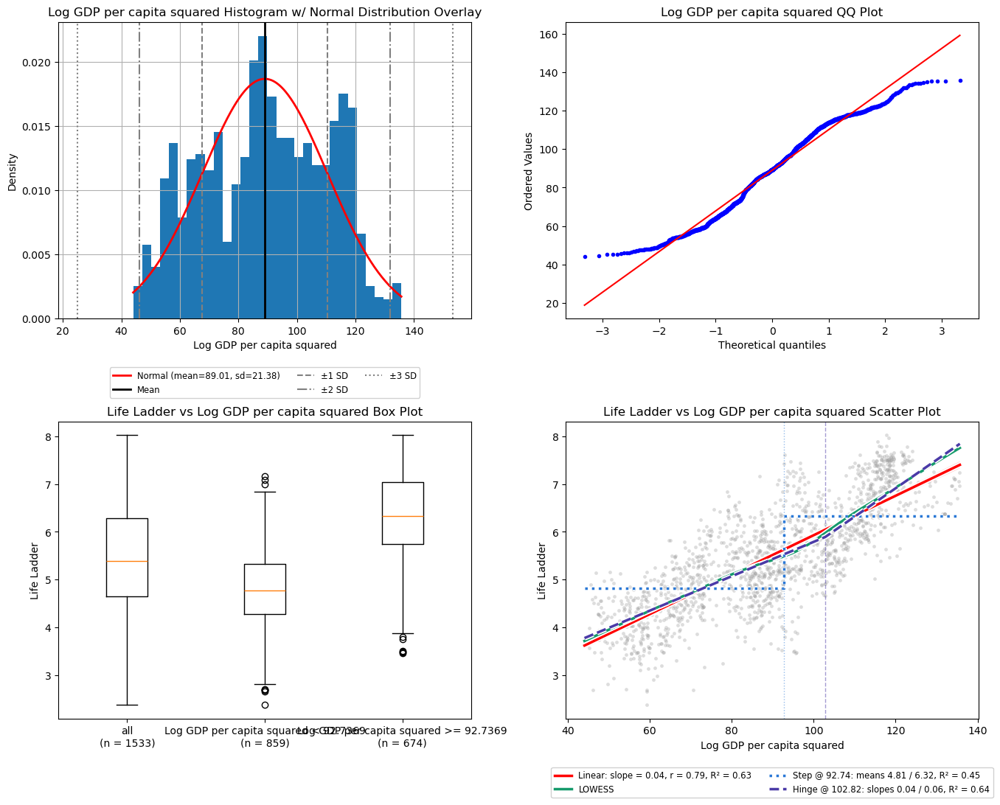

In [183]:
# fit on all gdp_df rows, for illustration only (the scores below refit inside each training fold)
gdp_e_df = pd.DataFrame(
	{"Log GDP per capita squared": np.ravel(FunctionTransformer(np.square).fit_transform(gdp_X)), TARGET: gdp_y},
	index=gdp_df.index,
)
plotting.single_feature_plots(df=gdp_e_df, feature="Log GDP per capita squared", target=TARGET, threshold="auto");

#### Intervention E vs Target

In [184]:
gdp_results["E"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.square)), ("model", LinearRegression())]),
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
display(scoring.results_df({k: gdp_results[k] for k in ["A", "E"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
E,0.679,0.011,0.550,0.009,0.626,0.016,-0.008,0.001,-6.065,0.0,candidate,20
A,0.687,0.011,0.557,0.009,0.617,0.015,0.000,NaN,NaN,NaN,baseline,20


### Intervention F | Log control

**What it targets**
Control. Q1B's Special Treatment says not to log the column again. Log stretches the low end and squeezes the top, the opposite of the steepening above about 10 that LOWESS shows. It is included to test that note.

**What the intervention does**
Replaces the raw value with its natural log:

`z = log(x)`

| x | log(x) |
|---|---|
| 6.635 | 1.892 |
| 7 | 1.946 |
| 8 | 2.079 |
| 9 | 2.197 |
| 10 | 2.303 |
| 11 | 2.398 |
| 11.648 | 2.455 |

The log spreads out the values near the bottom and squeezes those near the top: the gap from 7 to 8 becomes 0.133, while the same 1 unit gap from 10 to 11 becomes 0.095. Over 6.635 to 11.648 the squeeze is mild. The model becomes `Life Ladder = a + b·log(x)`, a straight line in log(x), which is a curve in x that is steeper at the low end and flatter at the top. The column min is 6.635, so x is always positive and the log is always defined.

**What it gives up**
It bends the fit the wrong way: toward a curve that flattens toward the top, the opposite of the steepening above about 10 that Q1B saw.

**Hypothesis**
Tests Q1B's note not to log the column again. Expected to lose to A.

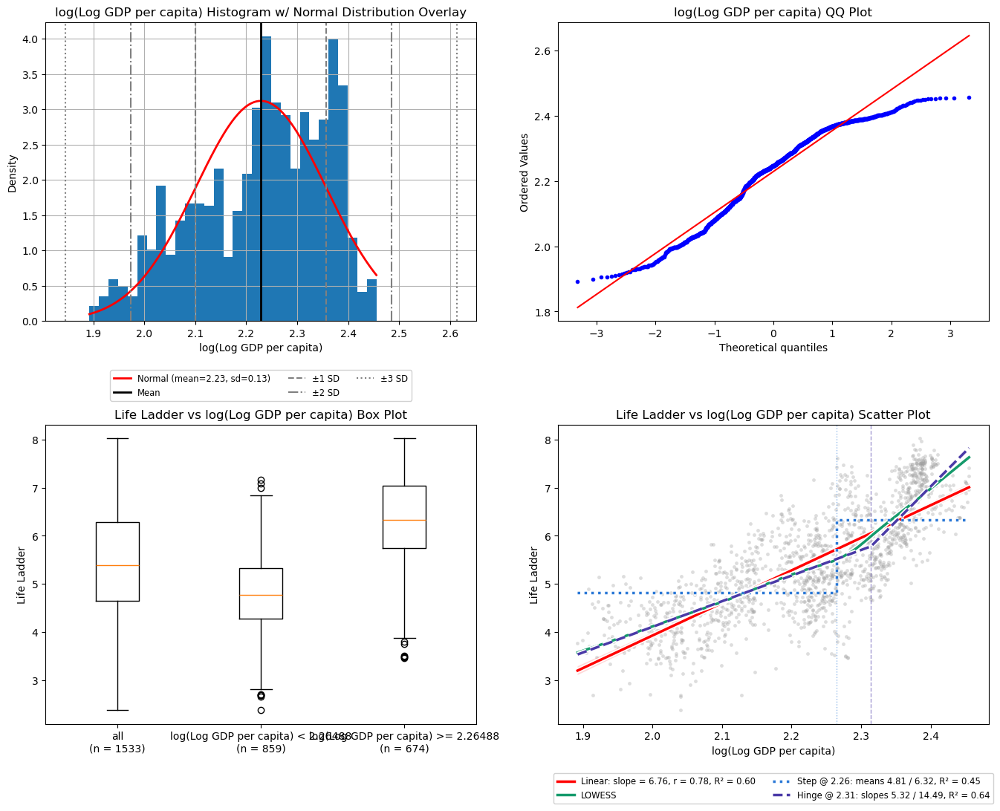

In [185]:
# fit on all gdp_df rows, for illustration only (the scores below refit inside each training fold)
gdp_f_df = pd.DataFrame(
	{"log(Log GDP per capita)": np.ravel(FunctionTransformer(np.log).fit_transform(gdp_X)), TARGET: gdp_y},
	index=gdp_df.index,
)
plotting.single_feature_plots(df=gdp_f_df, feature="log(Log GDP per capita)", target=TARGET, threshold="auto");

#### Intervention F vs Target

In [186]:
gdp_results["F"] = pipelines.evaluate_pipeline(
	Pipeline([("features", FunctionTransformer(np.log)), ("model", LinearRegression())]),
	X=gdp_X, y=gdp_y, folds=gdp_folds,
)
display(scoring.results_df({k: gdp_results[k] for k in ["A", "F"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
A,0.687,0.011,0.557,0.009,0.617,0.015,0.000,NaN,NaN,NaN,baseline,20
F,0.700,0.011,0.568,0.009,0.603,0.014,0.013,0.001,9.076,1.0,worse,20


### Intervention G | Flexible spline ceiling

**What it targets**
Not one specific shape. A ceiling: how much of Life Ladder any smooth single-column shape of Log GDP per capita can explain. B to F each force one shape (bend, two bends, jump, square, log curve). G tells whether those shapes leave signal behind.

**What the intervention does**
Replaces the raw value with a cubic spline basis (`SplineTransformer`, degree 3). The range of x is cut into equal-width pieces at `n_knots` knots, and the LR fits a separate cubic curve on each piece, joined smoothly at the knots. With enough knots it can follow a bend, a flat region and a steep region at the same time, wherever the data put them.

The number of knots is searched from [3, 4, 5, 6, 8, 10] inside each training fold (inner 4-fold CV), the same way the nested thresholds are (without the 5% guard, which only applies to thresholds), so the validation rows never influence it. Values outside the training range are extended in a straight line. No plot cell, since the feature is several columns.

**What it gives up**
Interpretability and simplicity: several coefficients instead of one or two, and no single threshold to carry forward. More knots can also fit noise, which the inner search is there to limit.

**Hypothesis**
- **If G scores about the same as the best of B to F:** the simple shapes already capture the signal, and the simpler one is carried forward.
- **If G is clearly better:** the simple shapes are missing part of the relationship.

#### Intervention G vs Target

In [187]:
gdp_g_pipeline = Pipeline([("features", SplineTransformer(degree=3, extrapolation="linear")), ("model", LinearRegression())])

gdp_results["G nested"] = pipelines.evaluate_pipeline(
	features.nested_threshold(gdp_g_pipeline, param="features__n_knots", grid=[3, 4, 5, 6, 8, 10], min_group_frac=None),
	X=gdp_X, y=gdp_y, folds=gdp_folds, return_estimator=True,
)
display(scoring.results_df({k: gdp_results[k] for k in ["A", "G nested"]}, baseline="A"))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,
G nested,0.641,0.015,0.504,0.011,0.667,0.021,-0.047,0.007,-6.491,0.0,candidate,20
A,0.687,0.011,0.557,0.009,0.617,0.015,0.000,NaN,NaN,NaN,baseline,20


In [188]:
# number of knots picked by the inner search in each of the 20 folds
gdp_g_picked = features.picked_thresholds(gdp_results["G nested"]["estimator"], param="features__n_knots")
display(pd.Series(gdp_g_picked).astype(int).value_counts().sort_index().rename_axis("G nested picked n_knots").to_frame("folds"))

,folds
G nested picked n_knots,
10,20


### Comparison

In [189]:
display(scoring.results_df(gdp_results, baseline="A", holm=True))

,rmse mean,rmse sd,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs A,Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,
G nested,0.641,0.015,0.504,0.011,0.667,0.021,-0.047,0.007,-6.491,0.000,0.000,significant,20
C nested,0.652,0.014,0.515,0.011,0.655,0.020,-0.036,0.006,-6.057,0.000,0.000,significant,20
D nested,0.660,0.015,0.527,0.012,0.647,0.020,-0.028,0.006,-4.918,0.000,0.000,significant,20
B fixed (t=10.13),0.670,0.013,0.539,0.010,0.636,0.018,-0.017,0.004,-4.486,0.000,0.001,significant,20
B nested,0.670,0.013,0.539,0.010,0.636,0.018,-0.017,0.004,-4.379,0.000,0.001,significant,20
E,0.679,0.011,0.550,0.009,0.626,0.016,-0.008,0.001,-6.065,0.000,0.000,significant,20
D fixed (t=9.63),0.685,0.011,0.556,0.009,0.619,0.015,-0.002,0.002,-1.418,0.086,0.172,candidate,20
A,0.687,0.011,0.557,0.009,0.617,0.015,0.000,NaN,NaN,NaN,NaN,baseline,20
F,0.700,0.011,0.568,0.009,0.603,0.014,0.013,0.001,9.076,1.000,1.000,worse,20


## Log GDP Per Capita Results

- **A is strong:** rmse 0.687 and r2 0.617, in line with Q1B's linear R² of 0.62 and the highest A of all eight attributes (Healthy life expectancy is next at 0.562). Log GDP per capita is not a candidate to drop.
- **Q1B's "None needed" does not hold.** Six of the eight interventions are significant, all with `p (Holm)` of 0.001 or less: G nested, C nested, D nested, B fixed, B nested and E. The best gain is Δ -0.047 (G nested) on an A rmse of 0.687, against -0.011 for Positive affect's best. D fixed is only a candidate (Δ -0.002, `p (Holm)` 0.172), and F loses to A.
- **The rise near 10.4 to 10.5 behaves like a jump, and the top bends again.** D nested (indicator + raw) scores rmse 0.660 against B's 0.670, with picks between 10.42 and 10.52 (10.42 or 10.45 in 15 of 20 folds), well above Q1B's step at 9.63, where D fixed barely moves (rmse 0.685 vs A's 0.687). C (two bends) does better still (rmse 0.652), picking (10.3, 10.9) in 15 of 20 folds and (10.3 or 10.4, 10.8) in the other 5, so the second bend sits at or next to the top of the guarded pair range (10.9). B scores 0.670 in both variants, with picks between 10.03 and 10.17 (10.12 to 10.14 in 15 of 20 folds).
- **The smooth transforms gain least, and the spline ceiling gains most.** E (square) scores rmse 0.679 (Δ -0.008) and trails B, though its gain is among the most consistent (Δ / SE -6.065). F, the log control, loses to A (rmse 0.700, Δ +0.013), which supports Q1B's "do not log it again". G, the flexible spline ceiling, has the lowest rmse (0.641, r2 0.667 vs C's 0.652 and 0.655) and picked 10 knots, the largest value in its grid, in all 20 folds. So the simple shapes leave signal behind, and the knot grid may be capping G.
- **Hypotheses that did not hold:** B nested's picks were expected to spread around 10.13, but they stayed between 10.03 and 10.17. The other hypotheses held: A near 0.62, B beating A, C's "top flattens or turns down" branch (C beats B), D's jump branch (D nested beats B) with D fixed adding little, E beating A and trailing B, F losing to A, and G's "clearly better" branch.

#### Carry forward

- **C (two bends `[x, max(0, x - t1), max(0, x - t2)]`)** as the main candidate for the multi-feature model, with the pair searched in each fold (picks at 10.3 or 10.4 and 10.8 or 10.9 in all 20 folds). It is the best simple shape (rmse 0.652) and significant, but its second bend sits at the edge of the guarded range, so it must clear the noise threshold again there.
- **D (raw + indicator `[x, 1[x < t]]`)** as the one-threshold alternative (rmse 0.660), with t near 10.42 to 10.45 (nested picks between 10.42 and 10.52), not at Q1B's step of 9.63.
- **G (cubic spline, 10 knots)** as the flexible option. It has the lowest rmse (0.641), and every fold picked the top of the knot grid.
- **B (raw + hinge, t = 10.13) and E (square)** as lower priority alternatives: significant, but with smaller gains (rmse 0.670 and 0.679).
- **Drop:** D fixed at 9.63 (rmse 0.685 vs A's 0.687, not significant) and F (log), which loses to A. Keep the column unlogged, as Q1B recommends.